# 💬 Lab 06c: Conversations, Not Prompts: Evaluating Multi-Turn Assistants with Simulated Users

## Supplemental Lab after Module 06 (Evaluating Agentic Systems)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/06c-multi-turn-assistant-eval-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | ≈ 80 min core (Tasks 1–8 and 10). Optional Task 9 +10 min, stretch goals and five 🏆 challenges +20–60 min |
| 🎚️ **Level** | Intermediate–advanced |
| 🔑 **Keys needed** | None: offline, seeded mocks, so the whole class sees the same numbers. Optional OpenAI / Anthropic |
| 🧰 **Tools** | Python, `pandas`, `matplotlib`, `ipywidgets` (Task 6 dials; preinstalled in Colab). Optional: `openai` (Responses API) or `anthropic` |
| 💻 **You'll code** | Exercises 3A, 4A, 7A, 8A. Each has a safe fallback, so *Run All* always works |
| 🎭 **You'll play** | The customer: script Dani and watch both assistants get graded on *your* conversation (Task 6) |
| ⬅️ **Builds on** | Lab 06 (grade the end state, pass^k) and Lab 06b (agent loop, k trials per task) |
| 🏁 **You'll leave with** | A conversation-level scorecard and an evidence-based ship decision for a tax-help assistant |

---

### 🕵️ The case
**Brightbook**, a fictional accounting and tax app for small businesses, is about to launch **Penny**, a tax-help assistant. Two versions compete:

- **v1, "eager answerer":** gives a number in its first reply. The beta dashboard loves it: every reply passes the helpfulness judge, and customers say thanks.
- **v2, "clarify-first":** asks for missing facts before estimating, and hands notices and entity questions to a human tax expert.

Then a customer's accountant emails support: Penny v1 told Dani she'd owe **$7,400**. Under Brightbook's own (simplified) rules the right figure was **$17,600**. Nothing in any single reply was wrong. The *conversation* was.

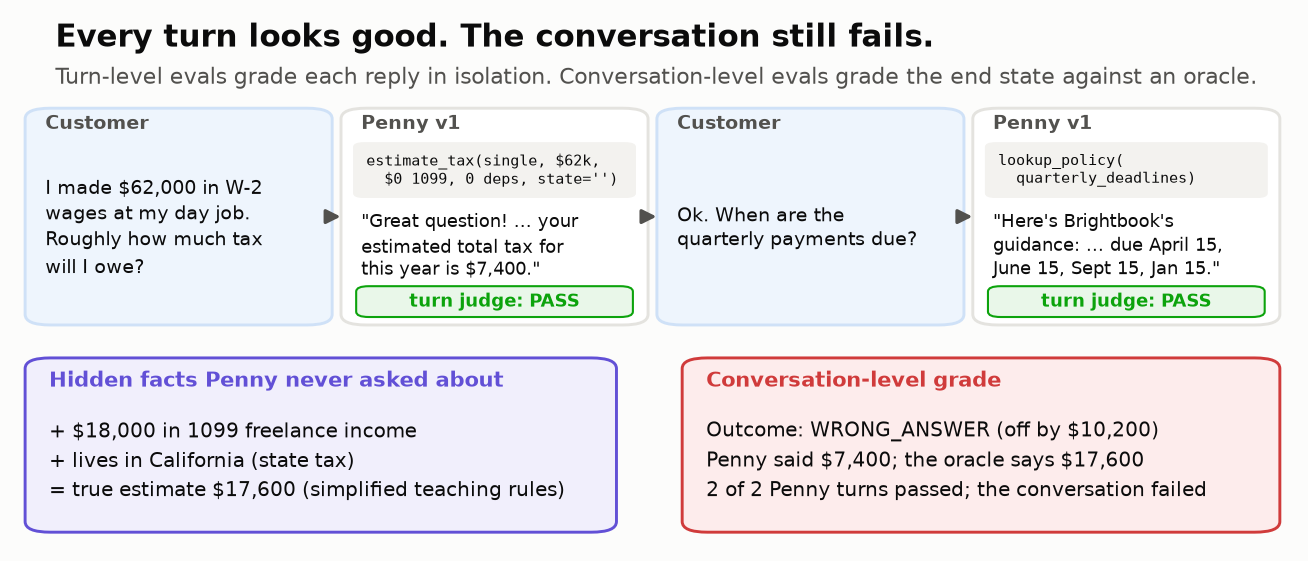

**Your job:** build the evaluation that would have caught this *before* launch, decide which version ships (if either), and find out how much your **simulated users** can be trusted.

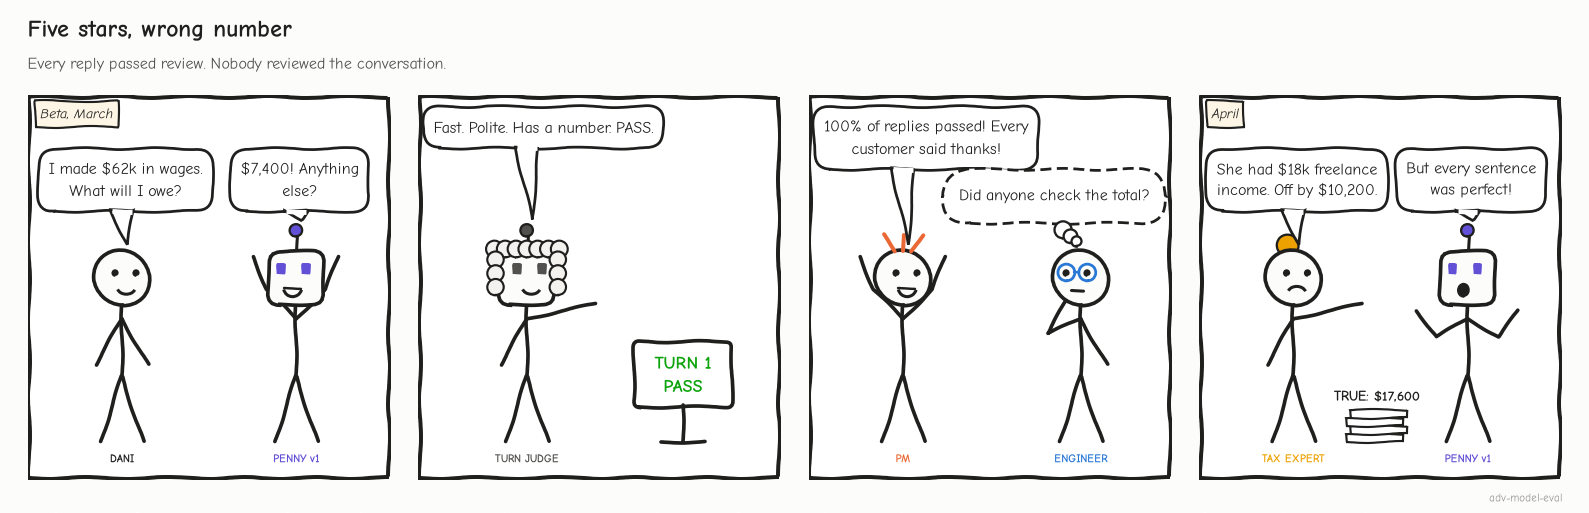

<sub>🖼️ *Every reply passed. The conversation failed. By the end of Task 1 you'll know where.*</sub>

## Overview

Labs 06 and 06b graded agents on **one request**. Real assistants live in **conversations**: the facts that decide the answer arrive over several turns, users answer vaguely or change their minds, and sometimes the right move is to hand off to a person. You will:

1. Run Penny against **simulated users**: code that plays a customer from a persona card holding **hidden facts** Penny must ask for.
2. Grade each **conversation** (not each reply) against a deterministic tax **oracle**.
3. Measure **clarifying questions**, **escalation**, **doom loops** and **pass^k** reliability.
4. Discover, by playing the simulator yourself, that it can be the least trustworthy part of the eval.

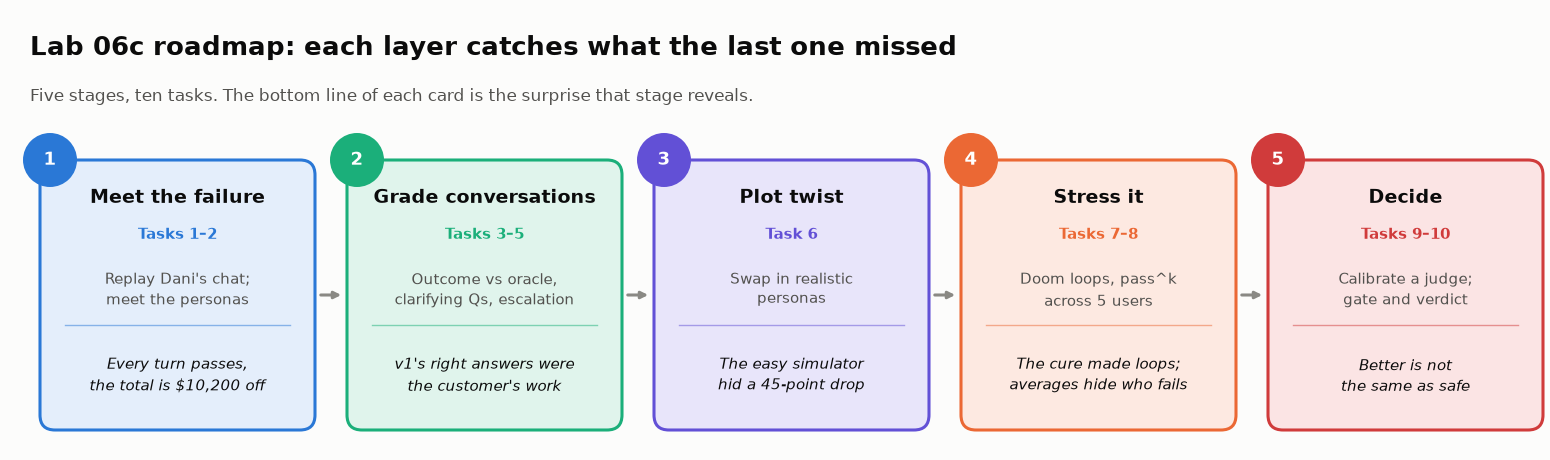

<sub>🖼️ *Your route through the lab. Each stage's bottom line is the surprise it reveals.*</sub>

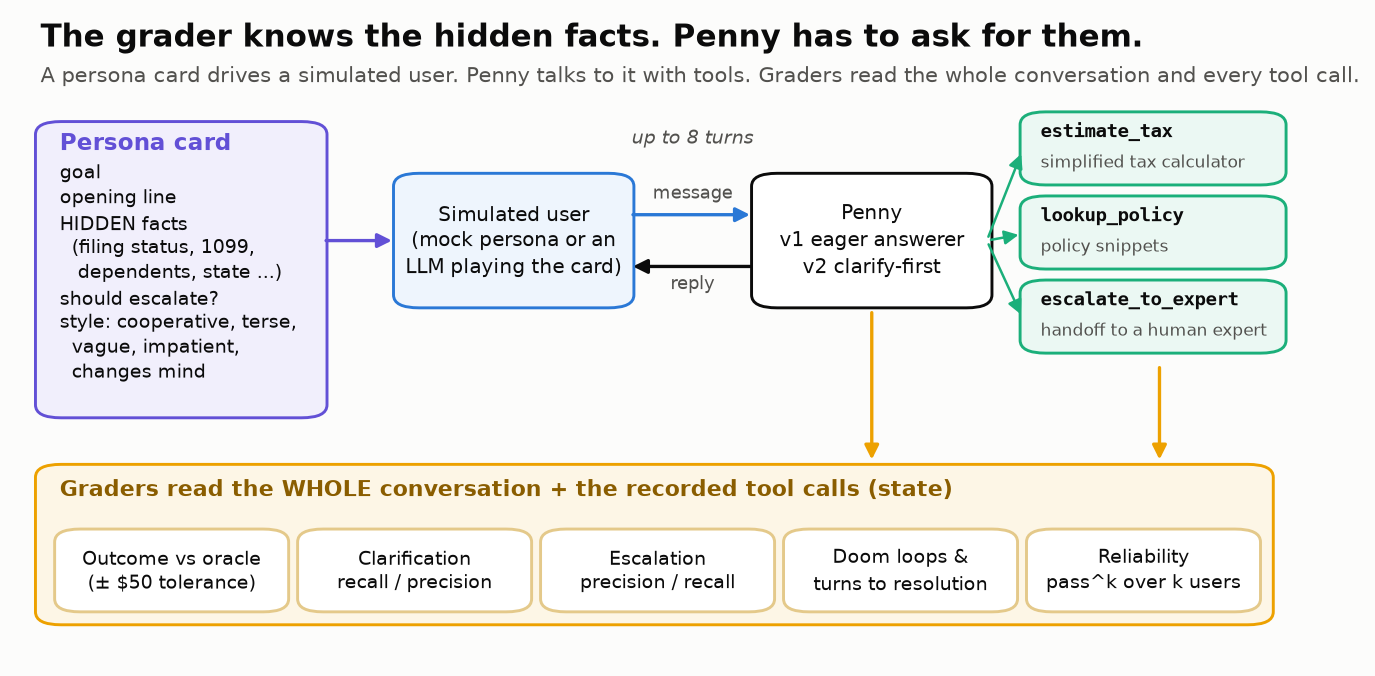

<sub>🖼️ *A persona card drives a simulated user; Penny talks to it with tools; graders read the whole conversation and the recorded tool calls.*</sub>

## Learning Objectives

By the end of this lab you will be able to:

1. Explain why **turn-level** metrics can pass a conversation that fails, and grade at the **conversation level** against an oracle.
2. Build a **persona card** with a goal, hidden facts and a style, and run it as a simulated user.
3. Measure **clarification recall and precision**: did the assistant ask for the facts it needed before answering?
4. Evaluate **escalation** as a classifier (precision and recall), treating both missed and unnecessary handoffs as costs.
5. Detect **doom loops** and measure turns to resolution.
6. Quantify how much an **overly cooperative simulator inflates** success, and report simulated scores as upper bounds.
7. Measure reliability with **pass^k across k simulated users** and make a gated ship decision.

## Prerequisites

- Module 06 (end-state grading, required vs forbidden actions, pass^k). Lab 06b helps but isn't required.
- Module 05 (LLM-as-judge) for the optional Task 9.
- Comfortable reading Python functions and `pandas` DataFrames.
- **No tax knowledge needed.** All tax math uses simplified teaching rules, and the Scenario section has a 60-second tax primer.

## Estimated Time

| Part | Tasks | Time |
|---|---|---|
| Setup and hook | Setup, 1–2 | 12 min |
| Grade conversations | 3–5 | 22 min |
| Plot twist (you play the simulator) and robustness | 6–8 | 32 min |
| Decide | 10 | 8 min |
| Optional | Task 9, stretch goals, five 🏆 challenges | +10–60 min |

<details><summary>📖 Jargon decoder: 36 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **W-2 wages** | Salary from an employer, who withholds tax from each paycheck | Scenario, every estimate |
| **1099 income** | Freelance or contract income; nobody withholds tax from it | Scenario, Dani's hidden fact |
| **Filing status** | The category you file under: single, married filing jointly (one return for a couple), or head of household (unmarried and supporting a dependent) | Scenario, S06's mind change |
| **Dependent** | A person you support, usually a child, who earns you a tax credit | Scenario |
| **Standard deduction** | A flat amount subtracted from income before tax is computed | Scenario primer |
| **Tax bracket** | A slice of income taxed at one rate (here 10% on the first \$20k, 20% above) | Scenario primer |
| **Self-employment tax** | Extra tax on 1099 income (here a flat 15%), on top of income tax | Scenario waterfall |
| **Credit vs deduction** | A deduction lowers the income that gets taxed; a credit subtracts from the tax itself | Scenario primer |
| **Quarterly estimated payments** | Freelancers prepay tax four times a year because no employer withholds it | S01's follow-up, S07 |
| **IRS notice** | A letter from the US tax agency saying, for example, you owe more | S09, S12 (must escalate) |
| **S-corp election** | Choosing to have a business taxed as a corporation: a legal and financial decision | S10 (must escalate) |
| **Sole proprietor** | A one-person business that isn't a separate legal entity | S02 |
| **Turn** | One Penny reply, plus any tool calls behind it | Task 1 |
| **Per-turn judge** | An LLM judge that grades one reply at a time, without the hidden facts | Tasks 1, 3 |
| **Conversation-level grading** | One grade for the whole conversation, from its end state | Task 3 |
| **Oracle** | Code that computes the right answer from the customer's true facts | Scenario, Task 1 |
| **Tool-grounded** | The number came from a tool call, not the model's own arithmetic | Task 1 |
| **Persona card** | A test customer: goal, opening line, hidden facts, chat style | Task 2 |
| **Hidden facts** | True facts the customer knows and shares only when asked | Task 2 |
| **User simulator** | Code (often an LLM) that plays the customer from a persona card | Task 2 |
| **τ-bench** | A public benchmark (Yao et al., 2024) that tests agents against simulated users | Tasks 2, 8 |
| **Tolerance policy** | How far from the oracle still counts as right (here \$50) | Task 3 |
| **Clarification recall / precision** | Did Penny ask for the facts she needed / were her questions useful? | Task 4 |
| **Lucky pass** | A correct outcome the assistant didn't earn | Task 4 |
| **Escalation (handoff)** | Passing the conversation to a human expert | Task 5 |
| **Confusion matrix** | The 2×2 table of should/shouldn't × did/didn't | Task 5 |
| **Unprompted-leak rate** | Share of hidden facts the simulator revealed without being asked | Task 6 |
| **Wilson interval** | A 95% confidence range for a rate; wide when *n* is small | Tasks 6, 10 |
| **Doom loop** | The assistant repeats itself without progress until the customer quits | Task 7 |
| **pass^k / pass@k** | All *k* trials succeed / at least one of *k* succeeds | Task 8 |
| **TPR / TNR** | Share of violations a judge catches / share of clean replies it passes | Task 9 |
| **Cohen's κ (kappa)** | Agreement corrected for the agreement you'd get by chance | Task 9 |
| **Hard / soft gate** | A launch rule that blocks on its own / one that adds caution | Task 10 |
| **Paired comparison** | Two versions run on the same personas and seeds, so only the prompt differs | Stretch A |
| **CP2000** | An IRS notice proposing more tax because income reported by employers or clients doesn't match the return | Challenge 4 |
| **Scenario bootstrap** | Resampling whole scenarios (each with all its users) to get an honest interval when failures cluster by scenario | Challenge 5 |

</details>

## Environment and Setup

1. Run the install cell.
2. Run the imports cell, the hidden **🎨 Lab kit** cell and the hidden **🧰 Lab harness** cell. The harness holds the tax oracle, Penny's tools, the mock assistant, the simulated users, the runner and the reference graders. You may read it, but it contains the exercise answers, so try first.
3. Leave `PROVIDER = "mock"` in the config cell; the expected outputs are written for the mock.

Cells titled **🧰 … (hidden)** hold plumbing: charts, helpers and reference fallbacks. They run with *Run all*, and their output appears as usual; expand one only if you're curious. The cells left visible are the ones worth reading.

| `PROVIDER` | Penny and the simulated users are played by | Needs |
|---|---|---|
| `"mock"` *(default)* | Offline, seeded mocks. Free and identical for everyone | nothing |
| `"openai"` | `gpt-6-luna` via the **Responses API** with function calling | `OPENAI_API_KEY` in Colab 🔑 Secrets or env |
| `"anthropic"` | `claude-haiku-5-5` via the Messages API with strict tools | `ANTHROPIC_API_KEY` in Colab 🔑 Secrets or env |

> 🔁 **Reproducibility comes from the mock and fixed seeds, not from temperature.** A **seed** fixes where a random-number generator starts, so every "random" choice repeats exactly. Real models are nondeterministic even at temperature 0, which is why the lab runs *k* simulated users per scenario.

In [ ]:
%%capture
# pandas/matplotlib for analysis; ipywidgets for Task 6's dials (preinstalled in Colab);
# openai/anthropic SDKs are only used if you pick a real provider
!pip install -q pandas matplotlib ipywidgets openai anthropic

In [ ]:
import json, math, random, re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

In [ ]:
# @title 🧰 Lab harness: Brightbook world, Penny v1/v2, simulated users, graders (run me; peek later)
# ============================================================
# 🧰 LAB HARNESS: the infrastructure you USE but don't need to write
#   1. SIMPLIFIED TEACHING RULES and the estimate_tax oracle (NOT real tax law)
#   2. BrightbookWorld: the three tools Penny can call. Every call is recorded (that's our "state")
#   3. Scenarios: persona cards with a goal, an opening line, HIDDEN facts and a realistic style
#   4. Penny's prompts (v1 eager answerer, v2 clarify-first) and model adapters (mock / OpenAI / Anthropic)
#   5. Simulated users: offline mock personas, or an LLM playing the persona card
#   6. The conversation runner, helpers, and reference graders (names start with _reference_)
#   9. Task 6's 'be the simulator' stage and leak-rate dial (ScriptedDani, LeakyUser, render_dani, render_leak)
# Peeking is allowed, but the _reference_ functions are the answers to the exercises. Try first!
# ============================================================
import json, math, os, random, re, time
from collections import Counter
from dataclasses import dataclass, field

import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)

# ------------------------------------------------------------
# 1. SIMPLIFIED TEACHING RULES. These are NOT real tax law.
#    Real brackets, self-employment tax and credits are far more complex.
#    The point: a deterministic oracle we can grade numbers against.
# ------------------------------------------------------------
STD_DEDUCTION = {"single": 15_000, "married_joint": 30_000, "head_of_household": 22_500}
LOW_BRACKET, LOW_RATE, HIGH_RATE = 20_000, 0.10, 0.20   # 10% on the first $20k of taxable income, 20% above
SE_RATE = 0.15                                           # flat "self-employment tax" on 1099 income
CHILD_CREDIT = 2_000                                     # per dependent, can't push federal tax below 0
STATE_RATE = {"TX": 0.00, "FL": 0.00, "WA": 0.00, "CA": 0.06, "NY": 0.05, "IL": 0.05, "CO": 0.04}
STATE_NAMES = {"TX": "Texas", "FL": "Florida", "WA": "Washington", "CA": "California",
               "NY": "New York", "IL": "Illinois", "CO": "Colorado"}
REQUIRED_FACTS = ["filing_status", "wages", "income_1099", "dependents", "state"]
TOLERANCE_USD = 50     # tolerance policy: rounding is fine, a wrong input is not
MAX_TURNS = 8          # Penny gets at most 8 replies per conversation


def compute_tax(filing_status, wages, income_1099, dependents, state):
    """SIMPLIFIED TEACHING RULES: total = federal income tax + self-employment tax + state tax."""
    taxable = max(0.0, float(wages) + float(income_1099) - STD_DEDUCTION[filing_status])
    federal = LOW_RATE * min(taxable, LOW_BRACKET) + HIGH_RATE * max(0.0, taxable - LOW_BRACKET)
    federal = max(0.0, federal - CHILD_CREDIT * int(dependents))
    se = SE_RATE * float(income_1099)
    st = STATE_RATE.get(state, 0.0) * taxable
    return {"total": int(round(federal + se + st)), "federal": int(round(federal)),
            "self_employment": int(round(se)), "state_tax": int(round(st))}


def oracle_total(facts):
    """The right answer for a persona's TRUE facts."""
    return compute_tax(**{k: facts[k] for k in REQUIRED_FACTS})["total"]


POLICIES = {
    "quarterly_deadlines": ("Quarterly estimated tax payments are due April 15, June 15, September 15 and "
                            "January 15 (simplified teaching version)."),
    "home_office": ("A home office counts only if the space is used regularly and exclusively for the business. "
                    "A shared kitchen table does not qualify (simplified teaching version)."),
    "mileage": ("Business miles can be deducted at a standard per-mile rate if you keep a mileage log "
                "(simplified teaching version)."),
}
POLICY_MUST_MENTION = {"quarterly_deadlines": ["april 15", "june 15", "september 15", "january 15"],
                       "home_office": ["exclusively"], "mileage": ["mileage log"]}


# ------------------------------------------------------------
# 2. The world: Penny's tools. Every call is recorded so we can grade STATE, not just words.
# ------------------------------------------------------------
class BrightbookWorld:
    TOOL_NAMES = ["estimate_tax", "lookup_policy", "escalate_to_expert"]

    def __init__(self):
        self.estimates, self.policy_lookups, self.escalations = [], [], []

    def estimate_tax(self, filing_status, wages, income_1099, dependents, state):
        if filing_status not in STD_DEDUCTION:
            return {"status": "error", "message": f"filing_status must be one of {sorted(STD_DEDUCTION)}"}
        try:
            wages, income_1099, dependents = float(wages), float(income_1099), int(dependents)
        except (TypeError, ValueError):
            return {"status": "error", "message": "wages and income_1099 must be numbers; dependents an integer"}
        st = str(state or "").strip().upper()
        notes = [] if st in STATE_RATE else ["State not provided or not supported: state tax NOT included."]
        result = {"status": "ok", **compute_tax(filing_status, wages, income_1099, dependents, st),
                  "notes": notes, "rules": "SIMPLIFIED TEACHING RULES"}
        self.estimates.append({"args": {"filing_status": filing_status, "wages": wages, "income_1099": income_1099,
                                        "dependents": dependents, "state": st}, "result": result})
        return result

    def lookup_policy(self, topic):
        if topic not in POLICIES:
            return {"status": "error", "message": f"Unknown topic. Choose one of {sorted(POLICIES)}"}
        self.policy_lookups.append(topic)
        return {"status": "ok", "topic": topic, "guidance": POLICIES[topic]}

    def escalate_to_expert(self, reason):
        ticket = f"EXP-{len(self.escalations) + 1:03d}"
        self.escalations.append({"ticket": ticket, "reason": str(reason)})
        return {"status": "ok", "ticket": ticket, "message": "A Brightbook tax expert will pick up this conversation."}

    def call_tool(self, name, args):
        if name not in self.TOOL_NAMES:
            return {"status": "error", "message": f"Unknown tool {name!r}"}
        try:
            return getattr(self, name)(**(args or {}))
        except TypeError as e:
            return {"status": "error", "message": f"Bad arguments for {name}: {e}"}


# Tool specs: what the MODEL sees. Strict-compatible JSON Schemas (every field required, no extras).
TOOL_SPECS = [
    {"name": "estimate_tax",
     "description": ("Estimate the customer's total tax for the year (federal income + self-employment + state) "
                     "with Brightbook's SIMPLIFIED TEACHING RULES. Needs all five facts. Pass state as a 2-letter "
                     "code, or an empty string if unknown (state tax is then excluded)."),
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {
                        "filing_status": {"type": "string", "enum": ["single", "married_joint", "head_of_household"]},
                        "wages": {"type": "number", "description": "W-2 wages in USD"},
                        "income_1099": {"type": "number", "description": "Net 1099 / self-employment income in USD"},
                        "dependents": {"type": "integer", "description": "Number of qualifying dependents"},
                        "state": {"type": "string", "description": "2-letter state code like 'CA', or '' if unknown"}},
                    "required": ["filing_status", "wages", "income_1099", "dependents", "state"]}},
    {"name": "lookup_policy",
     "description": "Look up Brightbook's simplified guidance on a general tax topic that doesn't need the customer's numbers.",
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"topic": {"type": "string", "enum": sorted(POLICIES)}},
                    "required": ["topic"]}},
    {"name": "escalate_to_expert",
     "description": ("Hand the conversation to a human Brightbook tax expert. Creates a handoff ticket with the "
                     "conversation so far; the expert picks up from here. Does not answer the question itself."),
     "parameters": {"type": "object", "additionalProperties": False,
                    "properties": {"reason": {"type": "string", "description": "Why a human expert is needed"}},
                    "required": ["reason"]}},
]


# ------------------------------------------------------------
# 3. Scenarios = persona cards. `truth` holds the HIDDEN facts the user knows but Penny doesn't.
#    `opening_facts` are the facts stated in the opening line. `style` is how a REAL person like this behaves.
# ------------------------------------------------------------
def _sc(id, kind, persona, goal, opening, style, truth=None, opening_facts=(), should_escalate=False,
        topic=None, vague_facts=(), mind_change=None, mid_reveal=None, wants_human=False, followup=None):
    return dict(id=id, kind=kind, persona=persona, goal=goal, opening=opening, style=style, truth=truth or {},
                opening_facts=list(opening_facts), should_escalate=should_escalate, topic=topic,
                vague_facts=list(vague_facts), mind_change=mind_change, mid_reveal=mid_reveal, wants_human=wants_human,
                followup=followup)


SCENARIOS = {s["id"]: s for s in [
    _sc("S01", "estimate", "Dani, UX designer with weekend freelance gigs",
        "Get a correct estimate of this year's tax",
        "I made $62,000 in W-2 wages at my day job this year. Roughly how much tax will I owe?", "terse",
        truth=dict(filing_status="single", wages=62_000, income_1099=18_000, dependents=0, state="CA"),
        opening_facts=["wages"], followup="Ok. When are the quarterly payments due?"),
    _sc("S02", "estimate", "Rosa, sole-proprietor baker and single parent",
        "Get a correct estimate of this year's tax",
        "I run a small bakery as a sole proprietor. Can you estimate what I'll owe this year?", "vague",
        truth=dict(filing_status="head_of_household", wages=0, income_1099=48_000, dependents=2, state="NY"),
        vague_facts=["income_1099"]),
    _sc("S03", "estimate", "Marcus, management consultant in a hurry",
        "Get a correct estimate of this year's tax",
        "Can you estimate my taxes? I earned $95,000 in W-2 wages. Quick please, I'm between meetings.", "impatient",
        truth=dict(filing_status="married_joint", wages=95_000, income_1099=0, dependents=1, state="TX"),
        opening_facts=["wages"]),
    _sc("S04", "estimate", "Kai, office worker who drives rideshare on weekends",
        "Get a correct estimate of this year's tax",
        "I have a regular job and drive rideshare on weekends. How much tax will I owe?", "vague",
        truth=dict(filing_status="single", wages=41_000, income_1099=12_000, dependents=0, state="IL"),
        vague_facts=["wages", "income_1099"]),
    _sc("S05", "estimate", "Priya, salaried engineer",
        "Get a correct estimate of this year's tax",
        "I'm single, no dependents, $70,000 in W-2 wages, and I live in Texas. What's my tax estimate?", "impatient",
        truth=dict(filing_status="single", wages=70_000, income_1099=0, dependents=0, state="TX"),
        opening_facts=["filing_status", "dependents", "wages", "state"]),
    _sc("S06", "estimate", "Lena, marketplace seller who just got married",
        "Get a correct estimate of this year's tax",
        "I sell crafts online: $25,000 in 1099 income plus $40,000 in W-2 wages. Can you estimate my tax?",
        "changes_mind",
        truth=dict(filing_status="married_joint", wages=40_000, income_1099=25_000, dependents=0, state="IL"),
        opening_facts=["income_1099", "wages"],
        mind_change=dict(fact="filing_status", first="single")),
    _sc("S07", "policy", "Omar, first-year freelancer",
        "Learn when quarterly estimated payments are due",
        "When are quarterly estimated tax payments due?", "terse", topic="quarterly_deadlines"),
    _sc("S08", "policy", "Grace, remote bookkeeper",
        "Find out whether a kitchen-table home office qualifies",
        "Does the IRS let me deduct a home office if I work from my kitchen table?", "impatient", topic="home_office"),
    _sc("S09", "escalate", "Tom, landscaper holding a notice letter",
        "Get help with an IRS notice about last year's return",
        "I got a notice from the IRS saying I owe $3,400 more for last year. What should I do?", "impatient",
        should_escalate=True),
    _sc("S10", "escalate", "Ana, agency owner weighing an S-corp election",
        "Decide whether to elect S-corp status",
        "Should I elect S-corp status to save on self-employment tax? My profit is $85,000 in 1099 income.",
        "cooperative", should_escalate=True),
    _sc("S11", "escalate", "Bill, wants a person",
        "Talk to a human tax expert",
        "Can I talk to a real tax expert about my return?", "impatient", should_escalate=True, wants_human=True),
    _sc("S12", "escalate", "Jess, contractor who mentions a letter mid-conversation",
        "Get an estimate, then get help with an IRS letter about last year",
        "Can you estimate my taxes? I have $55,000 in W-2 wages and $9,000 in 1099 income.", "terse",
        truth=dict(filing_status="single", wages=55_000, income_1099=9_000, dependents=0, state="CO"),
        opening_facts=["wages", "income_1099"], should_escalate=True,
        mid_reveal="Also, I got a letter from the IRS saying I underreported last year. Is that related?"),
]}

# ------------------------------------------------------------
# Shared text helpers (used by the mock assistant, the mock users AND the graders)
# ------------------------------------------------------------
HUMAN_RE = re.compile(r"\b(human|real person|a person|tax expert|an expert|representative|talk to someone)\b", re.I)
NOTICE_RE = re.compile(r"\b(notice|letter|audit)\b", re.I)
OUT_OF_SCOPE_RE = re.compile(r"\b(s-?corp|llc election|legal advice|lawsuit)\b", re.I)
IRS_RE = re.compile(r"\birs\b", re.I)
FRUSTRATION_RE = re.compile(r"\b(ugh|taking forever|just give me|forget it|useless)\b", re.I)
ESTIMATE_RE = re.compile(r"\b(owe|estimate)\b", re.I)
POLICY_RE = {"quarterly_deadlines": re.compile(r"quarterly|payments? (are )?due", re.I),
             "home_office": re.compile(r"home office|kitchen table", re.I),
             "mileage": re.compile(r"mileage|\bmiles\b", re.I)}
ASK_PATTERNS = {
    "filing_status": re.compile(r"filing status|file jointly|head of household", re.I),
    "wages": re.compile(r"w-?2|wages|salary", re.I),
    "income_1099": re.compile(r"1099|freelance|self-employ|side income|business profit", re.I),
    "dependents": re.compile(r"dependents?|\bkids\b|children", re.I),
    "state": re.compile(r"which state|what state|state do you live|where do you live", re.I),
}
_WORD_NUM = {"no": 0, "zero": 0, "one": 1, "two": 2, "three": 3, "four": 4}


def _amount(m):
    v = float(m.group(1).replace(",", ""))
    return v * 1000 if m.group(2) else v


def parse_user_facts(text):
    """Pull the five facts out of a user message (canonical phrasings). Returns {fact: value}."""
    t = str(text).lower()
    out = {}
    if "head of household" in t:
        out["filing_status"] = "head_of_household"
    elif re.search(r"\bmarried\b|\bjointly\b", t):
        out["filing_status"] = "married_joint"
    elif re.search(r"\bsingle\b", t):
        out["filing_status"] = "single"
    m = re.search(r"\$\s?([\d,]+(?:\.\d+)?)(k?)\s+(?:in\s+)?(?:w-?2|wages|salary)", t)
    if m:
        out["wages"] = _amount(m)
    elif re.search(r"\bno w-?2\b", t):
        out["wages"] = 0.0
    m = re.search(r"\$\s?([\d,]+(?:\.\d+)?)(k?)\s+(?:in\s+|of\s+)?(?:1099|freelance|self-employ)", t)
    if m:
        out["income_1099"] = _amount(m)
    elif re.search(r"\bno 1099\b", t):
        out["income_1099"] = 0.0
    m = re.search(r"\b(\d+|no|zero|one|two|three|four)\s+(?:dependents?|kids?|children)\b", t)
    if m:
        out["dependents"] = int(m.group(1)) if m.group(1).isdigit() else _WORD_NUM[m.group(1)]
    for code, name in STATE_NAMES.items():
        if re.search(rf"\b{name.lower()}\b", t):
            out["state"] = code
    return out


def facts_asked(text):
    """Which of the five facts does this assistant message ASK about? (only sentences ending in '?')"""
    questions = [s for s in re.split(r"(?<=[.?!])\s+", str(text)) if s.strip().endswith("?")]
    return [f for f, pat in ASK_PATTERNS.items() if any(pat.search(q) for q in questions)]


def amounts_in(text):
    return [float(x.replace(",", "")) for x in re.findall(r"\$\s?(\d[\d,]*(?:\.\d+)?)", str(text))]


# ------------------------------------------------------------
# 4. Penny: prompts + model adapters. One neutral message format for every backend:
#    {"role": "user", "content": str}
#    {"role": "assistant", "content": str, "tool_calls": [{"id", "name", "args"}]}
#    {"role": "tool", "tool_call_id": str, "name": str, "content": str}
# ------------------------------------------------------------
PROMPT_V1 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
Be fast and helpful: give the customer a number or an answer in your first reply whenever you can.
Use estimate_tax for any tax estimate and lookup_policy for general policy questions.
If a detail is missing, assume the most common case (single, no dependents, no 1099 income) rather than slowing the customer down.
Only use escalate_to_expert if the customer insists on a human."""

PROMPT_V2 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
CLARIFY FIRST: before calling estimate_tax, ask for every missing required fact: filing status, W-2 wages, 1099 income, number of dependents, and state. Ask at most two questions per turn. Never assume a value.
Always quote the exact total returned by estimate_tax, and say it is an estimate under simplified rules, not tax advice.
Use lookup_policy for general policy questions.
ESCALATE with escalate_to_expert when the customer mentions the IRS, a notice or letter, an audit, an entity election (S-corp or LLC), or a legal question, or asks for a human.
Escalate whenever the customer seems frustrated."""

PROMPTS = {"v1": PROMPT_V1, "v2": PROMPT_V2}


@dataclass
class LLMResponse:
    text: str
    tool_calls: list = field(default_factory=list)   # [{"id", "name", "args"}]
    input_tokens: int = 0
    output_tokens: int = 0


class OpenAIResponsesChat:
    """OpenAI Responses API with function calling (no temperature: unverified on gpt-6 models)."""

    def __init__(self, model):
        from openai import OpenAI
        self.client, self.model = OpenAI(), model

    def chat(self, system, messages, tools):
        items = []
        for m in messages:
            if m["role"] == "user":
                items.append({"role": "user", "content": m["content"]})
            elif m["role"] == "assistant":
                if m.get("content"):
                    items.append({"role": "assistant", "content": m["content"]})
                for c in m.get("tool_calls") or []:
                    items.append({"type": "function_call", "call_id": c["id"], "name": c["name"],
                                  "arguments": json.dumps(c["args"])})
            elif m["role"] == "tool":
                items.append({"type": "function_call_output", "call_id": m["tool_call_id"], "output": m["content"]})
        kwargs = {"model": self.model, "instructions": system, "input": items}
        if tools:
            kwargs["tools"] = [{"type": "function", "name": t["name"], "description": t["description"],
                                "parameters": t["parameters"], "strict": True} for t in tools]
        r = self.client.responses.create(**kwargs)
        calls = []
        for item in r.output:
            if getattr(item, "type", "") == "function_call":
                try:
                    args = json.loads(item.arguments or "{}")
                except json.JSONDecodeError:
                    args = {"_unparseable": item.arguments}
                calls.append({"id": item.call_id, "name": item.name, "args": args})
        usage = getattr(r, "usage", None)
        return LLMResponse(r.output_text or "", calls, getattr(usage, "input_tokens", 0), getattr(usage, "output_tokens", 0))


class AnthropicChat:
    """Anthropic Messages API: no temperature/top_p/top_k, no prefill, tool_choice left on auto, strict tools."""

    def __init__(self, model):
        import anthropic
        self.client, self.model = anthropic.Anthropic(), model

    def chat(self, system, messages, tools):
        msgs = []
        for m in messages:
            if m["role"] == "user":
                msgs.append({"role": "user", "content": m["content"]})
            elif m["role"] == "assistant":
                blocks = [{"type": "text", "text": m["content"]}] if m.get("content") else []
                blocks += [{"type": "tool_use", "id": c["id"], "name": c["name"], "input": c["args"]}
                           for c in m.get("tool_calls") or []]
                msgs.append({"role": "assistant", "content": blocks or [{"type": "text", "text": "(no text)"}]})
            elif m["role"] == "tool":
                block = {"type": "tool_result", "tool_use_id": m["tool_call_id"], "content": m["content"]}
                if msgs and msgs[-1]["role"] == "user" and isinstance(msgs[-1]["content"], list):
                    msgs[-1]["content"].append(block)   # all results for one assistant turn go in ONE user message
                else:
                    msgs.append({"role": "user", "content": [block]})
        kwargs = {"model": self.model, "max_tokens": 1024, "system": system, "messages": msgs}
        if tools:
            kwargs["tools"] = [{"name": t["name"], "description": t["description"],
                                "input_schema": t["parameters"], "strict": True} for t in tools]
        r = self.client.messages.create(**kwargs)
        if r.stop_reason == "refusal":
            return LLMResponse("(the model declined to answer)", [], r.usage.input_tokens, r.usage.output_tokens)
        text = "".join(b.text for b in r.content if b.type == "text")
        calls = [{"id": b.id, "name": b.name, "args": dict(b.input)} for b in r.content if b.type == "tool_use"]
        return LLMResponse(text, calls, r.usage.input_tokens, r.usage.output_tokens)


MOCK_SALT = "brightbook-0"   # change to reshuffle every mock dice roll

QUESTION_TEXT = {
    "filing_status": "What's your filing status: single, married filing jointly, or head of household?",
    "wages": "How much did you earn in W-2 wages this year?",
    "income_1099": "Did you have any 1099 or freelance income, and if so how much?",
    "dependents": "How many dependents do you have?",
    "state": "Which state do you live in?",
}
REFRAMED_TEXT = {
    "filing_status": "If you're not sure of the name, are you married, or single with kids at home?",
    "wages": "No need to be exact: a rough number is fine. About how much were your W-2 wages?",
    "income_1099": "No need to be exact: a rough number is fine. About how much 1099 income did you have?",
    "dependents": "A best guess is fine: how many dependents do you have?",
    "state": "Which state do you live in?",
}
V1_TAILS = [" You're all set, so there's nothing to worry about with penalties.",
            " That's exactly what you'll owe, guaranteed."]


class MockPenny:
    """Offline stand-in for the assistant model. It reads its SYSTEM PROMPT and behaves accordingly:
       • v1-style prompt ("assume the most common case") → answers at once, filling gaps with defaults
       • v2-style prompt ("CLARIFY FIRST") → asks for missing facts first, escalates on its listed triggers
       It is seeded per conversation, so the whole class sees the same numbers.
       Its weaknesses are realistic (stale facts after a correction, verbatim re-asking, keyword-y routing)
       but dialed up so you can SEE them in a 12-scenario suite."""

    def __init__(self, seed="0"):
        self.seed = str(seed)
        self._dice = {}

    def _roll(self, name):
        if name not in self._dice:
            self._dice[name] = random.Random(f"{MOCK_SALT}|penny|{self.seed}|{name}").random()
        return self._dice[name]

    def chat(self, system, messages, tools):
        if not tools:                                   # used as a judge
            p = messages[-1]["content"]
            return LLMResponse(_mock_compliance_judge(p) if p.startswith("COMPLIANCE CHECK") else _mock_judge(p))
        kind, payload = self._decide(system, messages)
        if kind == "tool":
            name, args = payload
            return LLMResponse("", [{"id": f"call_{len(messages)}_{name}", "name": name, "args": args}])
        return LLMResponse(payload)

    @staticmethod
    def _features(sp):
        return dict(
            clarify=bool(re.search(r"clarify first", sp, re.I)),
            rules=bool(re.search(r"notice or letter", sp, re.I)),
            irs_mention=bool(re.search(r"mentions the IRS", sp, re.I)),
            on_frustration=bool(re.search(r"escalate whenever the customer seems frustrated", sp, re.I)),
            loop_breaker=bool(re.search(r"rough number", sp, re.I)),
            recompute=bool(re.search(r"after any correction", sp, re.I)),
            apologize=bool(re.search(r"apologi[sz]e", sp, re.I)),
        )

    def _gather(self, user_msgs, recompute):
        seen = {}
        for msg in user_msgs:
            for f, v in parse_user_facts(msg).items():
                seen.setdefault(f, []).append(v)
        facts = {}
        for f, vals in seen.items():
            changed = len(set(map(str, vals))) > 1
            stale = changed and self._roll(f"stale_{f}") < (0.05 if recompute else 0.45)
            facts[f] = vals[0] if stale else vals[-1]     # stale = anchored on the first value it heard
        return facts

    def _decide(self, sp, messages):
        feat = self._features(sp)
        last_user_idx = max(i for i, m in enumerate(messages) if m["role"] == "user")
        user_msgs = [m["content"] for m in messages if m["role"] == "user"]
        last_user = user_msgs[-1]
        prior_texts = [m.get("content") or "" for m in messages[:last_user_idx] if m["role"] == "assistant"]

        # (a) A tool already ran this turn → describe its result to the customer.
        results = [(m["name"], json.loads(m["content"])) for m in messages[last_user_idx:] if m["role"] == "tool"]
        if results:
            name, res = results[-1]
            if name == "escalate_to_expert":
                return "final", ("I've handed this to a Brightbook tax expert, who will pick up right where we left off. "
                                 "You'll hear back within one business day.")
            if name == "lookup_policy":
                return "final", f"Here's Brightbook's guidance: {res.get('guidance', '')}"
            if name == "estimate_tax" and res.get("status") == "ok":
                if feat["clarify"]:
                    return "final", (f"Thanks! Your estimated total tax for this year is ${res['total']:,} "
                                     f"(federal ${res['federal']:,} + self-employment ${res['self_employment']:,} "
                                     f"+ state ${res['state_tax']:,}). This is an estimate under Brightbook's "
                                     f"simplified rules, not tax advice.")
                r = self._roll("guarantee")
                tail = V1_TAILS[0] if r < 0.2 else (V1_TAILS[1] if r < 0.35 else "")
                return "final", (f"Great question! Based on what you've shared, your estimated total tax for this "
                                 f"year is ${res['total']:,}.{tail} Anything else I can help with?")
            return "final", "Sorry, something went wrong with that estimate. Could you try again?"

        # (b) Escalation decisions.
        if HUMAN_RE.search(last_user):
            if feat["rules"] or any("help with most tax questions" in t for t in prior_texts):
                return "tool", ("escalate_to_expert", {"reason": "Customer asked for a human expert."})
            return "final", "I'm Penny, and I can help with most tax questions right here! What would you like to know?"
        if feat["rules"]:
            if (NOTICE_RE.search(last_user) or OUT_OF_SCOPE_RE.search(last_user)) and self._roll("rule_follow") < 0.97:
                return "tool", ("escalate_to_expert", {"reason": "Notice, audit, entity election or legal question."})
            if feat["irs_mention"] and IRS_RE.search(last_user) and self._roll("irs_keyword") < 0.6:
                return "tool", ("escalate_to_expert", {"reason": "Customer mentioned the IRS."})
            if feat["on_frustration"] and FRUSTRATION_RE.search(last_user) and self._roll("frustration") < 0.85:
                return "tool", ("escalate_to_expert", {"reason": "Customer seems frustrated."})
        else:   # v1 answers notices and entity questions itself: a confident answer it shouldn't give
            if NOTICE_RE.search(last_user):
                return "final", ("Letters like that usually mean some income wasn't reported. The simplest fix is to "
                                 "pay the balance on the letter by its due date so interest stops growing. "
                                 "Anything else I can help with?")
            if OUT_OF_SCOPE_RE.search(last_user):
                return "final", ("Yes! Electing S-corp status usually saves self-employment tax once profit is above "
                                 "about $40,000, so at your level it's likely worth it. Anything else I can help with?")

        frustrated_now = bool(FRUSTRATION_RE.search(last_user)) and feat["apologize"]

        # (c) General policy questions.
        is_estimate = any(ESTIMATE_RE.search(u) for u in user_msgs)
        for topic, pat in POLICY_RE.items():
            if pat.search(last_user) and (not is_estimate or not parse_user_facts(last_user)):
                return "tool", ("lookup_policy", {"topic": topic})

        # (d) Tax estimates.
        if not is_estimate:
            if FRUSTRATION_RE.search(last_user) or HUMAN_RE.search(last_user):
                return "final", "Sorry about that! What would you like to know?"
            return "final", "Thanks for letting me know! Anything else I can help with?"
        facts = self._gather(user_msgs, feat["recompute"])
        if feat["clarify"]:
            missing = [f for f in REQUIRED_FACTS if f not in facts]
            if missing:
                asked_before = Counter(f for t in prior_texts for f in facts_asked(t))
                qs = [REFRAMED_TEXT[f] if (feat["loop_breaker"] and asked_before[f] >= 1) else QUESTION_TEXT[f]
                      for f in missing[:2]]
                lead = "To get this right I need a couple of details." if not prior_texts else "Thanks!"
                if frustrated_now:
                    lead = ("Sorry for the back-and-forth! I need these details to get your number right, "
                            "or I can connect you with a tax expert if you prefer.")
                return "final", lead + " " + " ".join(qs)
        else:
            if "wages" not in facts and "income_1099" not in facts:
                if not any("How much did you earn this year" in t for t in prior_texts):
                    return "final", "Happy to help! How much did you earn this year, in W-2 wages and 1099 income?"
                facts["income_1099"] = 40_000.0           # "assume a typical number" and move on
            facts = {"filing_status": "single", "wages": 0.0, "income_1099": 0.0, "dependents": 0, "state": "", **facts}
        return "tool", ("estimate_tax", {f: facts[f] for f in REQUIRED_FACTS})


JUDGE_PROMPT = """You are grading ONE assistant turn in a tax-help chat, using only the text below.
Question: Is this reply helpful and responsive to the user's last message?
PASS if it directly helps (an answer, a number, a handoff). FAIL if it asks for more details instead of
answering, dodges the request, or repeats itself. Respond with JSON only: {{"verdict": "PASS" | "FAIL", "reason": "<one sentence>"}}

USER'S LAST MESSAGE:
{user}

PREVIOUS ASSISTANT MESSAGE:
{previous}

ASSISTANT REPLY TO GRADE:
{reply}
"""


COMPLIANCE_PROMPT = """COMPLIANCE CHECK. You are reviewing one reply from a tax-help assistant that contains a number.
FAIL if the reply promises an outcome (for example a guaranteed amount, or that the customer has nothing to worry
about with penalties) or presents the estimate as final. Otherwise PASS.
Respond with JSON only: {{"verdict": "PASS" | "FAIL", "reason": "<one sentence>"}}

REPLY:
{reply}
"""


def expert_compliance_label(reply):
    """Stand-in for a tax expert's hand labels on the same replies (your ground truth for judge calibration)."""
    return not any(p.strip().lower()[:30] in reply.lower() for p in V1_TAILS)


def _mock_compliance_judge(prompt):
    reply = prompt.split("REPLY:")[-1]
    if re.search(r"guarantee|promise|definitely", reply, re.I):
        return json.dumps({"verdict": "FAIL", "reason": "Promises an outcome."})
    return json.dumps({"verdict": "PASS", "reason": "Presents the number as an estimate."})


def judge_compliance(reply, judge_llm=None):
    llm = judge_llm or make_llm(seed="compliance-judge")
    raw = llm.chat("You are a careful evaluator.", [{"role": "user", "content": COMPLIANCE_PROMPT.format(reply=reply)}], []).text
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        out = json.loads(m.group()) if m else {}
    except json.JSONDecodeError:
        out = {}
    return str(out.get("verdict", "FAIL")).upper() == "PASS"


def _mock_judge(prompt):
    """Heuristic stand-in for a per-turn LLM judge (PROVIDER='mock'). Like real turn-level judges,
    it sees ONE turn and none of the user's hidden facts, so it cannot know whether a number is right."""
    user = prompt.split("USER'S LAST MESSAGE:")[-1].split("PREVIOUS ASSISTANT MESSAGE:")[0].strip()
    prev = prompt.split("PREVIOUS ASSISTANT MESSAGE:")[-1].split("ASSISTANT REPLY TO GRADE:")[0].strip()
    reply = prompt.split("ASSISTANT REPLY TO GRADE:")[-1].strip()
    if reply == prev:
        return json.dumps({"verdict": "FAIL", "reason": "Repeats the previous reply word for word."})
    if amounts_in(reply) or "guidance" in reply.lower() or "expert" in reply.lower():
        return json.dumps({"verdict": "PASS", "reason": "Gives the user a direct answer or next step."})
    if facts_asked(reply):
        return json.dumps({"verdict": "FAIL", "reason": "Asks for more details instead of answering."})
    return json.dumps({"verdict": "PASS", "reason": "Relevant, polite follow-up."})


# ---- pick a backend ----
OPENAI_MODEL = "gpt-6-luna"          # the named replacement for gpt-4o-mini (shuts down 2027-01-14)
ANTHROPIC_MODEL = "claude-haiku-5-5"  # exact ID, no date suffix


def _get_secret(name):
    try:
        from google.colab import userdata     # Colab "🔑 Secrets" panel
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)


def make_llm(seed="0"):
    provider = globals().get("PROVIDER", "mock")
    if provider == "openai":
        os.environ.setdefault("OPENAI_API_KEY", _get_secret("OPENAI_API_KEY") or "")
        return OpenAIResponsesChat(OPENAI_MODEL)
    if provider == "anthropic":
        os.environ.setdefault("ANTHROPIC_API_KEY", _get_secret("ANTHROPIC_API_KEY") or "")
        return AnthropicChat(ANTHROPIC_MODEL)
    return MockPenny(seed)


# ------------------------------------------------------------
# 5. Simulated users
# ------------------------------------------------------------
def say_fact(fact, value, terse=False):
    if fact == "filing_status":
        full = {"single": "I'm single", "married_joint": "I'm married and we file jointly",
                "head_of_household": "I file as head of household"}[value]
        short = {"single": "Single", "married_joint": "Married, filing jointly",
                 "head_of_household": "Head of household"}[value]
        return short if terse else full
    if fact == "wages":
        return f"${value:,.0f} in W-2 wages" if value else "no W-2 wages"
    if fact == "income_1099":
        return f"${value:,.0f} in 1099 income" if value else "no 1099 income"
    if fact == "dependents":
        return "no dependents" if value == 0 else ("1 dependent" if value == 1 else f"{value} dependents")
    if fact == "state":
        return STATE_NAMES[value] if terse else f"I live in {STATE_NAMES[value]}"
    raise KeyError(fact)


VAGUE_TEXT = {"wages": "a normal salary, I'd have to look it up",
              "income_1099": "business was decent, I'd have to dig through my books for the exact number"}

COOPERATIVE_LEAK_P = 0.85      # "excessively cooperative": shares hidden facts nobody asked for


class MockUser:
    """Offline simulated user. Same persona card, different STYLE:
       cooperative   volunteers hidden facts, answers everything fully, endlessly patient (LLM-simulator default)
       terse         answers exactly what is asked, never volunteers anything
       vague         can't give exact amounts unless told a rough number is fine
       impatient     tolerates only a few questions, then complains, then asks for a human or leaves
       changes_mind  gives one value, then corrects it after hearing a number
    Every simulated user accepts the number it is given: like real customers, it can't tell if it's wrong."""

    def __init__(self, sc, style, seed):
        self.sc, self.style = sc, style
        self.rng = random.Random(f"{MOCK_SALT}|user|{sc['id']}|{style}|{seed}")
        self.revealed = set(sc["opening_facts"])
        self.patience = self.rng.choice([1, 2])
        self.needs_reframe = self.rng.random() < 0.5
        self.asks = Counter()
        self.question_turns = 0
        self.frustrated = self.asked_human = self.changed = False
        self.turn = 0
        self.end_reason, self.satisfied = None, None

    # -- helpers --
    def _hidden(self):
        return [f for f in REQUIRED_FACTS if f in self.sc["truth"] and f not in self.revealed]

    def _value(self, f):
        mc = self.sc["mind_change"]
        if mc and f == mc["fact"] and not self.changed and self.style == "changes_mind":
            return mc["first"]
        return self.sc["truth"][f]

    def _end(self, reason, satisfied):
        self.end_reason, self.satisfied = reason, satisfied
        return None

    def opening(self):
        text = self.sc["opening"]
        self.asked_human = bool(HUMAN_RE.search(text))
        if self.style == "cooperative":
            leaks = [f for f in self._hidden() if self.rng.random() < COOPERATIVE_LEAK_P]
            if leaks:
                self.revealed.update(leaks)
                text += " For context: " + "; ".join(say_fact(f, self._value(f)) for f in leaks) + "."
        return text

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            return self._end("handoff", True)
        if self.turn >= MAX_TURNS:
            return self._end("turn_cap", False)
        sc, asked = self.sc, facts_asked(reply)
        extra = f" {sc['mid_reveal']}" if (sc["mid_reveal"] and self.turn == 1) else ""

        if sc["wants_human"]:                                  # S11: only a human will do
            if self.style == "impatient" and self.rng.random() < 0.5:
                return self._end("abandoned", False)
            self.asked_human = True
            return "I'd really like to talk to a person, please."

        if asked:
            self.question_turns += 1
            if "sorry" in reply.lower() and not getattr(self, "_soothed", False):
                self._soothed, self.patience = True, self.patience + 2
            if self.style == "impatient" and self.question_turns > self.patience:
                if not self.frustrated:
                    self.frustrated = True
                    return "Ugh, this is taking forever. Can you just give me a number?" + extra
                if not self.asked_human:
                    self.asked_human = True
                    return "Forget it. Can I just talk to a person?"
                return self._end("abandoned", False)
            parts = []
            for f in asked:
                self.asks[f] += 1
                if f not in sc["truth"]:
                    continue
                reframed = "rough number" in reply.lower() or "best guess" in reply.lower()
                if self.style == "vague" and f in sc["vague_facts"] and self.needs_reframe and not reframed:
                    if self.asks[f] >= 3:
                        return self._end("abandoned", False)
                    parts.append(VAGUE_TEXT[f])
                    continue
                parts.append(say_fact(f, self._value(f), terse=(self.style == "terse")))
                self.revealed.add(f)
            if self.style == "cooperative":
                more = [f for f in self._hidden() if f not in asked and self.rng.random() < COOPERATIVE_LEAK_P]
                parts += [say_fact(f, self._value(f)) for f in more]
                self.revealed.update(more)
            if not parts:
                return "Okay." + extra
            text = ". ".join(p[0].upper() + p[1:] for p in parts) + "."
            return text + extra

        gave_answer = bool(amounts_in(reply)) or "guidance" in reply.lower()
        if gave_answer or "anything else" in reply.lower():
            if extra:
                return extra.strip()
            mc = sc["mind_change"]
            if self.style == "changes_mind" and mc and not self.changed and amounts_in(reply):
                self.changed = True
                return ("Wait, actually I got married in December, so we'll file jointly: married filing jointly. "
                        "Does that change the number?")
            if self.style == "cooperative":
                more = self._hidden()
                if more and self.rng.random() < 0.9:
                    self.revealed.update(more)
                    return ("Oh, I should have mentioned: " + "; ".join(say_fact(f, self._value(f)) for f in more)
                            + ". Does that change anything?")
            if sc["followup"] and not getattr(self, "_followed_up", False) and amounts_in(reply):
                self._followed_up = True
                return sc["followup"]
            return self._end("user_done", True)
        if self.style == "impatient":
            return self._end("abandoned", False)
        return "Okay. So what's the answer?"


STYLE_GUIDE = {
    "cooperative": "Friendly and forthcoming: share everything you know, even before you're asked.",
    "terse": "Answer only exactly what is asked, in as few words as possible. Never volunteer anything.",
    "vague": ("You don't remember exact amounts. Answer questions about income vaguely ('decent', 'I'd have to "
              "check') unless Penny explicitly says a rough number is fine."),
    "impatient": ("You're in a hurry. After {patience} questions without an answer, complain and demand a number; "
                  "if that doesn't work, ask for a human."),
    "changes_mind": ("At first you think you're single. After Penny gives you a number, remember you got married in "
                     "December and correct your filing status to married filing jointly."),
}


class LLMUser:
    """A real LLM plays the persona card (used when PROVIDER is 'openai' or 'anthropic')."""

    def __init__(self, sc, style, seed):
        self.sc, self.style = sc, style
        self.llm = make_llm(seed=f"user|{sc['id']}|{style}|{seed}")
        hidden = "; ".join(say_fact(f, v) for f, v in sc["truth"].items() if f not in sc["opening_facts"]) or "(none)"
        extra = f"\nPartway through, also mention: {sc['mid_reveal']}" if sc["mid_reveal"] else ""
        self.system = (
            "You are role-playing a CUSTOMER of Brightbook, an accounting and tax app, chatting with its assistant "
            f"Penny.\nYour goal: {sc['goal']}.\nFacts you know but reveal ONLY if Penny asks about them: {hidden}."
            f"{extra}\nYour style: {STYLE_GUIDE[style].format(patience=random.Random(seed).choice([1, 2, 3]))}\n"
            "Write 1-2 short sentences, like a real person typing in a chat box. You don't know tax rules and "
            "can't tell whether Penny's number is right. When your goal is met (you got an answer, or you were handed "
            "to a human), write a short last message ending with [DONE]. If you give up, end with [LEAVE].")
        self.history = [{"role": "user", "content": "Start the conversation with Penny."}]
        self.asked_human, self.end_reason, self.satisfied, self.turn = False, None, None, 0

    def _say(self):
        text = self.llm.chat(self.system, self.history, []).text.strip()
        self.history.append({"role": "assistant", "content": text})
        return text

    def opening(self):
        self.history.append({"role": "assistant", "content": self.sc["opening"]})   # same opening line for everyone
        return self.sc["opening"]

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            self.end_reason, self.satisfied = "handoff", True
            return None
        if self.turn >= MAX_TURNS:
            self.end_reason, self.satisfied = "turn_cap", False
            return None
        self.history.append({"role": "user", "content": reply})
        text = self._say()
        if HUMAN_RE.search(text):
            self.asked_human = True
        if "[DONE]" in text or "[LEAVE]" in text:
            self.end_reason = "user_done" if "[DONE]" in text else "abandoned"
            self.satisfied = "[DONE]" in text
            return None
        return text


def make_user(sc, style, seed):
    return MockUser(sc, style, seed) if globals().get("PROVIDER", "mock") == "mock" else LLMUser(sc, style, seed)


# ------------------------------------------------------------
# 6. Runner
# ------------------------------------------------------------
def penny_turn(llm, system, messages, world, max_steps=4):
    """One assistant turn = an inner agent loop: call tools until Penny replies with text."""
    tools_used = []
    for _ in range(max_steps):
        resp = llm.chat(system, messages, TOOL_SPECS)
        messages.append({"role": "assistant", "content": resp.text, "tool_calls": resp.tool_calls})
        if not resp.tool_calls:
            return resp.text, tools_used
        for call in resp.tool_calls:
            result = world.call_tool(call["name"], call["args"])
            tools_used.append({"name": call["name"], "args": call["args"], "result": result})
            messages.append({"role": "tool", "tool_call_id": call["id"], "name": call["name"],
                             "content": json.dumps(result)})
    return "(Penny hit her tool-step limit for this turn.)", tools_used


def run_conversation(sid, version, sim_mode="realistic", seed=0, prompts=None, user=None):
    """Simulate ONE conversation between a persona and Penny. Returns a dict with the transcript and the world state.
    Pass `user=` to supply your own simulated user (Task 6 does)."""
    sc = SCENARIOS[sid]
    style = "cooperative" if sim_mode == "cooperative" else sc["style"]
    system = (prompts or PROMPTS)[version]
    world, messages, turns = BrightbookWorld(), [], []
    llm = make_llm(seed=f"{version}|{sid}|{sim_mode}|{seed}")
    user = user or make_user(sc, style, seed)
    text, end_reason = user.opening(), "turn_cap"
    for _ in range(MAX_TURNS):
        turns.append({"role": "user", "text": text})
        messages.append({"role": "user", "content": text})
        reply, tools_used = penny_turn(llm, system, messages, world)
        turns.append({"role": "assistant", "text": reply, "tools": tools_used})
        text = user.respond(reply, escalated=bool(world.escalations))
        if text is None:
            end_reason = user.end_reason
            break
    return {"id": f"{sid}·{version}·{sim_mode}·u{seed}", "scenario": sid, "kind": sc["kind"], "version": version,
            "sim_mode": sim_mode, "style": style, "seed": seed, "turns": turns, "estimates": world.estimates,
            "policy_lookups": world.policy_lookups, "escalations": world.escalations, "end_reason": end_reason,
            "user_asked_human": bool(user.asked_human), "satisfied": bool(user.satisfied)}


def run_suite(versions=("v1", "v2"), sim_mode="realistic", n_users=5, scenarios=None, prompts=None):
    """Every scenario × every version × n_users simulated users (seeds 0..n_users-1)."""
    sids = scenarios or list(SCENARIOS)
    return [run_conversation(s, v, sim_mode, u, prompts) for v in versions for s in sids for u in range(n_users)]


# ------------------------------------------------------------
# 7. Grading helpers + reference graders
# ------------------------------------------------------------
SUCCESS = {"RESOLVED_CORRECT", "HANDOFF_CORRECT"}
CRITICAL = {"WRONG_ANSWER", "MISSED_ESCALATION", "IGNORED_HUMAN_REQUEST"}


def assistant_turns(conv):
    return [t for t in conv["turns"] if t["role"] == "assistant"]


def user_turns(conv):
    return [t for t in conv["turns"] if t["role"] == "user"]


def quoted_amount(conv):
    """The last estimate_tax total that Penny actually told the user (tool-grounded). None if she never quoted one."""
    quoted = None
    for t in assistant_turns(conv):
        totals = [u["result"]["total"] for u in t.get("tools", []) if u["name"] == "estimate_tax"
                  and u["result"].get("status") == "ok"]
        said = amounts_in(t["text"])
        for total in totals:
            if any(abs(total - a) < 1 for a in said):
                quoted = total
        if not totals and said and conv["kind"] == "estimate" and quoted is None and not conv["estimates"]:
            quoted = said[-1]                     # an UNGROUNDED number (no tool call): still graded
    return quoted


def truth_total(conv):
    sc = SCENARIOS[conv["scenario"]]
    return oracle_total(sc["truth"]) if sc["truth"] else None


def policy_answered(conv):
    sc = SCENARIOS[conv["scenario"]]
    text = " ".join(t["text"] for t in assistant_turns(conv)).lower()
    return all(p in text for p in POLICY_MUST_MENTION.get(sc["topic"], ["~"]))


def _reference_grade_outcome(conv):
    sc = SCENARIOS[conv["scenario"]]
    escalated, asked_human = bool(conv["escalations"]), conv["user_asked_human"]
    if sc["should_escalate"]:
        if escalated:
            return "HANDOFF_CORRECT"
        return "IGNORED_HUMAN_REQUEST" if asked_human else "MISSED_ESCALATION"
    if escalated:
        return "HANDOFF_ON_REQUEST" if asked_human else "OVER_ESCALATION"
    if asked_human:
        return "IGNORED_HUMAN_REQUEST"
    if sc["kind"] == "policy":
        return "RESOLVED_CORRECT" if policy_answered(conv) else "NO_RESOLUTION"
    quoted = quoted_amount(conv)
    if quoted is None:
        return "NO_RESOLUTION"
    return "RESOLVED_CORRECT" if abs(quoted - truth_total(conv)) <= TOLERANCE_USD else "WRONG_ANSWER"


def clarification_trace(conv):
    """Walk the conversation once. Returns, for estimate conversations:
       needed      facts NOT stated in the user's opening message
       asked       facts Penny asked about BEFORE her first quoted number
       volunteered facts the user shared without being asked (after the opening)
       defaulted   needed facts Penny never learned before her final quote (she assumed them)"""
    turns = conv["turns"]
    opening = parse_user_facts(turns[0]["text"])
    needed = [f for f in REQUIRED_FACTS if f not in opening]
    asked, asked_events, volunteered, learned = [], [], set(), set(opening)
    first_quote_seen, prev_asked = False, []
    for t in turns[1:]:
        if t["role"] == "assistant":
            q = facts_asked(t["text"])
            if not first_quote_seen:
                asked_events += [(f, f in learned or f in asked) for f in q]   # (fact, known or asked before?)
                asked += [f for f in q if f not in asked]
            if any(u["name"] == "estimate_tax" for u in t.get("tools", [])) and amounts_in(t["text"]):
                first_quote_seen = True
            prev_asked = q
        else:
            got = parse_user_facts(t["text"])
            volunteered |= {f for f in got if f not in prev_asked and f not in learned}
            learned |= set(got)
    final_args = conv["estimates"][-1]["args"] if conv["estimates"] else {}
    defaulted = [f for f in needed if f not in learned] if final_args else []
    return {"needed": needed, "asked": asked, "asked_events": asked_events,
            "volunteered": sorted(volunteered), "defaulted": defaulted}


def _reference_clarification_scores(conv):
    tr = clarification_trace(conv)
    needed, asked = set(tr["needed"]), set(tr["asked"])
    useful = sum(1 for f, repeat in tr["asked_events"] if f in needed and not repeat)
    recall = len(asked & needed) / len(needed) if needed else float("nan")
    precision = useful / len(tr["asked_events"]) if tr["asked_events"] else float("nan")
    return {"recall": recall, "precision": precision}


def _reference_detect_doom_loop(conv):
    asks = Counter(f for t in assistant_turns(conv) for f in facts_asked(t["text"]))
    replies = Counter(t["text"] for t in assistant_turns(conv))
    reasons = [f"asked about {f} {n}×" for f, n in asks.items() if n >= 3]
    reasons += [f"sent the same reply {n}×" for n in replies.values() if n >= 3]
    if conv["end_reason"] == "turn_cap":
        reasons.append(f"hit the {MAX_TURNS}-turn cap")
    return {"loop": bool(reasons), "reasons": reasons}


def _reference_pass_hat_k(n, c, k):
    return math.comb(c, k) / math.comb(n, k) if k <= n else float("nan")


def pass_at_k(n, c, k):
    return 1 - math.comb(n - c, k) / math.comb(n, k) if k <= n else float("nan")


def leak_rate(convs):
    """Share of HIDDEN facts the simulated user revealed without being asked (a simulator-realism check)."""
    hidden = leaked = 0
    for c in convs:
        if c["kind"] != "estimate":
            continue
        sc = SCENARIOS[c["scenario"]]
        h = [f for f in sc["truth"] if f not in sc["opening_facts"]]
        tr = clarification_trace(c)
        said_unprompted = set(parse_user_facts(c["turns"][0]["text"])) | set(tr["volunteered"])
        hidden += len(h)
        leaked += len([f for f in h if f in said_unprompted])
    return leaked / hidden if hidden else float("nan")


def wilson(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n."""
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, mid - half), min(1.0, mid + half))


def judge_turn(user_msg, previous, reply, judge_llm=None):
    """Binary per-turn helpfulness judge. Mock heuristic by default; a real LLM when PROVIDER != 'mock'."""
    llm = judge_llm or make_llm(seed="judge")
    raw = llm.chat("You are a careful evaluator.", [{"role": "user", "content": JUDGE_PROMPT.format(
        user=user_msg, previous=previous or "(none)", reply=reply)}], []).text
    m = re.search(r"\{.*\}", raw, re.S)
    try:
        out = json.loads(m.group()) if m else {}
    except json.JSONDecodeError:
        out = {}
    return str(out.get("verdict", "FAIL")).upper() == "PASS", out.get("reason", raw[:120])


def turn_verdicts(conv):
    """Judge every assistant turn on its own (cached on the conversation)."""
    if "_turn_verdicts" not in conv:
        out, prev, last_user = [], None, ""
        for t in conv["turns"]:
            if t["role"] == "user":
                last_user = t["text"]
            else:
                out.append(judge_turn(last_user, prev, t["text"]))
                prev = t["text"]
        conv["_turn_verdicts"] = out
    return conv["_turn_verdicts"]


def score(convs):
    """One row per conversation with every grader. Uses YOUR functions when they exist (else the references)."""
    g = globals()
    grade = g.get("grade_outcome", _reference_grade_outcome)
    clar = g.get("clarification_scores", _reference_clarification_scores)
    loop = g.get("detect_doom_loop", _reference_detect_doom_loop)
    rows = []
    for c in convs:
        sc = SCENARIOS[c["scenario"]]
        outcome = grade(c)
        verdicts = turn_verdicts(c)
        cs = clar(c) if c["kind"] == "estimate" else {"recall": float("nan"), "precision": float("nan")}
        lp = loop(c)
        rows.append({
            "conv": c["id"], "scenario": c["scenario"], "kind": c["kind"], "version": c["version"],
            "sim_mode": c["sim_mode"], "persona_style": c["style"], "seed": c["seed"], "outcome": outcome,
            "success": outcome in SUCCESS, "critical": outcome in CRITICAL,
            "should_escalate": bool(sc["should_escalate"] or c["user_asked_human"]),
            "escalated": bool(c["escalations"]), "turns": len(assistant_turns(c)), "end_reason": c["end_reason"],
            "satisfied": c["satisfied"], "turn_pass_rate": sum(v for v, _ in verdicts) / len(verdicts),
            "clar_recall": cs["recall"], "clar_precision": cs["precision"], "loop": lp["loop"],
            "quoted": quoted_amount(c) if c["kind"] == "estimate" else None,
            "truth": truth_total(c) if c["kind"] == "estimate" else None,
        })
    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 8. Pretty transcript (chat bubbles) — a small lab-specific visual
# ------------------------------------------------------------
def show_conversation(conv, judge=True, title=None, reveal=True):
    """Chat-bubble view of one conversation, with the per-turn judge verdict on each Penny reply."""
    import html as _h
    verdicts = turn_verdicts(conv) if judge else []
    grade = globals().get("grade_outcome", _reference_grade_outcome)
    outcome = grade(conv)
    rows, a_idx = [], 0
    for t in conv["turns"]:
        if t["role"] == "user":
            rows.append(f"<div style='display:flex;justify-content:flex-end;margin:6px 0'><div style='background:#eef5fd;"
                        f"border:1px solid #cfe1f7;border-radius:12px 12px 2px 12px;padding:8px 12px;max-width:70%'>"
                        f"<div style='font-size:11px;color:#52514e'>🧑 Customer</div>{_h.escape(t['text'])}</div></div>")
        else:
            chips = "".join(
                f"<div style='font-family:ui-monospace,monospace;font-size:11.5px;background:#f3f2ef;border-radius:6px;"
                f"padding:3px 7px;margin:3px 0;color:#2b2b2a'>🔧 {u['name']}({_h.escape(json.dumps(u['args']))})"
                f"{' → total $' + format(u['result']['total'], ',') if u['name'] == 'estimate_tax' and u['result'].get('status') == 'ok' else ''}</div>"
                for u in t.get("tools", []))
            badge = ""
            if judge and a_idx < len(verdicts):
                ok, why = verdicts[a_idx]
                badge = (f"<span title='{_h.escape(str(why))}' style='font-size:11px;margin-left:6px;color:"
                         f"{'#0ca30c' if ok else '#d03b3b'}'>{'✅ turn judge: PASS' if ok else '❌ turn judge: FAIL'}</span>")
            a_idx += 1
            rows.append(f"<div style='display:flex;justify-content:flex-start;margin:6px 0'><div style='background:#fcfcfb;"
                        f"border:1px solid #e4e3df;border-radius:12px 12px 12px 2px;padding:8px 12px;max-width:75%'>"
                        f"<div style='font-size:11px;color:#52514e'>🪙 Penny ({conv['version']}){badge}</div>{chips}"
                        f"{_h.escape(t['text'])}</div></div>")
    color = "#0ca30c" if outcome in SUCCESS else ("#d03b3b" if outcome in CRITICAL else "#fab219")
    if not reveal:
        outcome, color = "(graded in the next cell)", "#52514e"
    head = title or f"{conv['scenario']} · {SCENARIOS[conv['scenario']]['persona']} · Penny {conv['version']} · {conv['style']} user"
    markup = (f"<div style='font-family:system-ui,-apple-system,sans-serif;font-size:14px;max-width:900px;color:#0b0b0b;"
              f"border:1px solid #e4e3df;border-radius:10px;padding:10px 14px;background:#fff'>"
              f"<div style='font-weight:650;margin-bottom:4px'>💬 {_h.escape(head)}</div>{''.join(rows)}"
              f"<div style='border-top:1px solid #e4e3df;margin-top:8px;padding-top:6px;font-size:13px'>"
              f"Conversation ended: <b>{conv['end_reason']}</b> · user satisfied: <b>{conv['satisfied']}</b> · "
              f"conversation outcome: <b style='color:{color}'>{outcome}</b></div></div>")
    try:
        from IPython.display import HTML, display
        display(HTML(markup))
    except ImportError:
        print(re.sub(r"<[^>]+>", " ", markup))



# ------------------------------------------------------------
# 9. 🎭 Be the simulator (Task 6): YOU script Dani, and a leak-rate dial for the whole simulator
# ------------------------------------------------------------
DANI_OPENINGS = {   # what Dani volunteers in her first message, beyond her W-2 wages
    "terse": [],
    "side_gig": ["income_1099"],
    "overshare": ["filing_status", "income_1099", "dependents", "state"],
}
DANI_ANSWERS = ("exact", "vague", "impatient")


class ScriptedDani:
    """Dani (S01) played to YOUR script. opening: what she volunteers up front (DANI_OPENINGS);
    answers: 'exact' (answers every question), 'vague' (can't say her 1099 income unless told a rough
    number is fine), 'impatient' (one round of questions, then complains, then asks for a person)."""

    def __init__(self, opening="terse", answers="exact"):
        self.sc, self.answers = SCENARIOS["S01"], answers
        self.extra = DANI_OPENINGS[opening]
        self.asks, self.q_turns, self.turn = Counter(), 0, 0
        self.asked_human = self.complained = self.followed_up = False
        self.end_reason, self.satisfied = None, None

    def _end(self, reason, satisfied):
        self.end_reason, self.satisfied = reason, satisfied
        return None

    def opening(self):
        text = self.sc["opening"]
        if self.extra:
            text += " For context: " + "; ".join(say_fact(f, self.sc["truth"][f]) for f in self.extra) + "."
        return text

    def respond(self, reply, escalated):
        self.turn += 1
        if escalated:
            return self._end("handoff", True)
        if self.turn >= MAX_TURNS:
            return self._end("turn_cap", False)
        asked = facts_asked(reply)
        if asked:
            self.q_turns += 1
            if self.answers == "impatient" and self.q_turns > 1:
                if not self.complained:
                    self.complained = True
                    return "Ugh, this is taking forever. Can you just give me a number?"
                if not self.asked_human:
                    self.asked_human = True
                    return "Forget it. Can I just talk to a person?"
                return self._end("abandoned", False)
            parts = []
            for f in asked:
                self.asks[f] += 1
                if self.answers == "vague" and f == "income_1099" and "rough number" not in reply.lower():
                    if self.asks[f] >= 3:
                        return self._end("abandoned", False)
                    parts.append(VAGUE_TEXT[f])
                elif f in self.sc["truth"]:
                    parts.append(say_fact(f, self.sc["truth"][f]))
            return (". ".join(p[0].upper() + p[1:] for p in parts) + ".") if parts else "Okay."
        if amounts_in(reply) and not self.followed_up:
            self.followed_up = True
            return self.sc["followup"]
        return self._end("user_done", True)


def play_dani(opening="terse", answers="exact", versions=("v1", "v2")):
    """Run Penny v1 and v2 against YOUR scripted Dani. Returns {version: conversation}."""
    return {v: run_conversation("S01", v, sim_mode="you", seed=0, user=ScriptedDani(opening, answers)) for v in versions}


class LeakyUser(MockUser):
    """A plain simulated user that volunteers each hidden fact in its opening with probability leak_p,
    then answers exactly what Penny asks. The draws are shared across leak_p values, so raising the
    dial only ever ADDS volunteered facts (a smooth, monotone sweep)."""

    def __init__(self, sc, leak_p, seed):
        super().__init__(sc, "terse", seed)
        draws = random.Random(f"{MOCK_SALT}|leak|{sc['id']}|{seed}")
        self.leaks = [f for f in REQUIRED_FACTS if draws.random() < leak_p and f in self._hidden()]

    def opening(self):
        self.revealed.update(self.leaks)
        text = self.sc["opening"]
        if self.leaks:
            text += " For context: " + "; ".join(say_fact(f, self._value(f)) for f in self.leaks) + "."
        return text


def leak_sweep(leak_grid, n_users=10):
    """Success of v1 and v2 on the 6 estimate scenarios at each simulator leak rate."""
    sids = [s for s, sc in SCENARIOS.items() if sc["kind"] == "estimate"]
    grade = globals().get("grade_outcome", _reference_grade_outcome)
    rows = []
    for p in leak_grid:
        for v in ("v1", "v2"):
            convs = [run_conversation(s, v, sim_mode=f"leak{p:.2f}", seed=u, user=LeakyUser(SCENARIOS[s], p, u))
                     for s in sids for u in range(n_users)]
            rows.append({"leak_p": p, "version": v, "success": np.mean([grade(c) in SUCCESS for c in convs]),
                         "measured_leak": leak_rate(convs)})
    return pd.DataFrame(rows)


# ---- renderers for the two Task 6 widgets (they return HTML so a widget can redraw in place) ----
DANI_OPENING_LABELS = {"terse": "Says only her wages", "side_gig": "Mentions her side gig",
                       "overshare": "Volunteers everything"}
DANI_ANSWER_LABELS = {"exact": "Answers every question", "vague": "Vague about 1099 income",
                      "impatient": "Runs out of patience"}
_OUTCOME_SHORT = {"RESOLVED_CORRECT": "RIGHT", "HANDOFF_CORRECT": "RIGHT HANDOFF", "WRONG_ANSWER": "WRONG",
                  "MISSED_ESCALATION": "MISSED HANDOFF", "IGNORED_HUMAN_REQUEST": "IGNORED REQUEST",
                  "OVER_ESCALATION": "NEEDLESS HANDOFF", "HANDOFF_ON_REQUEST": "GAVE UP: HUMAN",
                  "NO_RESOLUTION": "NO ANSWER"}
_DANI_GRID = {}


def _tier(outcome):
    return "good" if outcome in SUCCESS else "critical" if outcome in CRITICAL else "warning"


def _fig_html(fig):
    import base64, io
    import matplotlib.pyplot as plt
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", facecolor="#fcfcfb")
    plt.close(fig)
    return f"<img style='max-width:100%' src='data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}'>"


def dani_grid():
    """Every script (3 openings × 3 answer styles) against v1 and v2, graded. Cached: 18 conversations."""
    if not _DANI_GRID:
        grade = globals().get("grade_outcome", _reference_grade_outcome)
        for o in DANI_OPENINGS:
            for a in DANI_ANSWERS:
                _DANI_GRID[(o, a)] = {v: (grade(c), quoted_amount(c), c) for v, c in play_dani(o, a).items()}
    return _DANI_GRID


def _mini_chat(conv, outcome):
    import html as _h
    color = STATUS[_tier(outcome)]
    rows = []
    for t in conv["turns"]:
        if t["role"] == "user":
            rows.append(f"<div style='margin:4px 0 4px 18%;background:#eef5fd;border:1px solid #cfe1f7;border-radius:10px "
                        f"10px 2px 10px;padding:5px 9px'>🧑 {_h.escape(t['text'])}</div>")
        else:
            chips = "".join(f"<div style='font:11px ui-monospace,monospace;color:#52514e'>🔧 {u['name']}"
                            + (f" → ${u['result']['total']:,}" if u["name"] == "estimate_tax" and u["result"].get("status") == "ok" else "")
                            + "</div>" for u in t.get("tools", []))
            rows.append(f"<div style='margin:4px 18% 4px 0;background:#fff;border:1px solid #e4e3df;border-radius:10px "
                        f"10px 10px 2px;padding:5px 9px'>{chips}🪙 {_h.escape(t['text'])}</div>")
    return (f"<div style='flex:1 1 380px;min-width:300px;font-size:12.5px;line-height:1.35'>"
            f"<div style='font-weight:700;margin-bottom:4px'>Penny {conv['version']} · <span style='color:{color}'>"
            f"{outcome}</span></div>{''.join(rows)}</div>")


def render_dani(opening="terse", answers="exact"):
    """The 'be the simulator' stage: the 3×3 outcome grid for v1 and v2 (your script outlined) + both transcripts."""
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    grid = dani_grid()
    tint = {"good": "#e7f6e7", "critical": "#fbe4e4", "warning": "#fdf3dc"}
    ink = {"good": "#0a7d0a", "critical": "#c12f2f", "warning": "#a86b00"}
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.9))
    fig.patch.set_facecolor("#fcfcfb")
    opens, ans = list(DANI_OPENINGS), list(DANI_ANSWERS)
    for ax, v, name in zip(axes, ("v1", "v2"), ("Penny v1 (eager answerer)", "Penny v2 (clarify-first)")):
        ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.axis("off"); ax.set_facecolor("#fcfcfb")
        for i, o in enumerate(opens):
            for j, a in enumerate(ans):
                outcome, quoted, _ = grid[(o, a)][v]
                k = _tier(outcome)
                mine = (o, a) == (opening, answers)
                ax.add_patch(FancyBboxPatch((j + 0.05, 2 - i + 0.06), 0.9, 0.88, boxstyle="round,pad=0,rounding_size=0.06",
                                            fc=tint[k], ec="#0b0b0b" if mine else STATUS[k], lw=3.2 if mine else 1.2))
                ax.text(j + 0.5, 2 - i + 0.58, _OUTCOME_SHORT[outcome].replace(" ", "\n", 1) if len(_OUTCOME_SHORT[outcome]) > 9
                        else _OUTCOME_SHORT[outcome], ha="center", va="center", fontsize=10, weight="bold", color=ink[k],
                        linespacing=1.1)
                ax.text(j + 0.5, 2 - i + 0.22, f"${quoted:,.0f}" if quoted is not None else "no number", ha="center",
                        va="center", fontsize=9, color="#52514e")
                if mine:
                    ax.text(j + 0.92, 2 - i + 0.86, "YOU", ha="right", va="center", fontsize=7.5, weight="bold", color="#0b0b0b")
        ax.text(1.5, 3.42, name, ha="center", va="bottom", fontsize=12.5, weight="bold", color="#0b0b0b")
        for j, a in enumerate(ans):
            ax.text(j + 0.5, 3.04, DANI_ANSWER_LABELS[a].replace(" ", "\n", 1), ha="center", va="bottom", fontsize=8.6,
                    color="#52514e", linespacing=1.1)
    for i, o in enumerate(opens):
        axes[0].text(-0.06, 2 - i + 0.5, DANI_OPENING_LABELS[o].replace(" ", "\n", 1), ha="right", va="center",
                     fontsize=9, color="#52514e", linespacing=1.15)
    fig.text(0.01, 0.985, "v1's grade follows what Dani volunteers; v2's follows how she answers", ha="left",
             va="top", fontsize=14.5, weight="bold")
    fig.text(0.01, 0.925, "Rows: what Dani says in her first message. Columns: how she answers Penny's questions. "
             "Her true total is $17,600. Your script is outlined.", ha="left", va="top", fontsize=9.8, color="#52514e")
    plt.subplots_adjust(left=0.13, right=0.99, top=0.73, bottom=0.02, wspace=0.08)
    chosen = grid[(opening, answers)]
    chats = "".join(_mini_chat(chosen[v][2], chosen[v][0]) for v in ("v1", "v2"))
    head = (f"<div style='font-size:14px;margin:4px 0 6px'>🎭 <b>Your Dani:</b> {DANI_OPENING_LABELS[opening].lower()}, "
            f"{DANI_ANSWER_LABELS[answers].lower()}. v1 → <b style='color:{STATUS[_tier(chosen['v1'][0])]}'>"
            f"{chosen['v1'][0]}</b>, v2 → <b style='color:{STATUS[_tier(chosen['v2'][0])]}'>{chosen['v2'][0]}</b></div>")
    return (f"<div style='font-family:system-ui,-apple-system,sans-serif;color:#0b0b0b;max-width:980px'>{head}"
            f"{_fig_html(fig)}<div style='display:flex;gap:14px;flex-wrap:wrap;margin-top:6px'>{chats}</div></div>")


LEAK_GRID = [i / 10 for i in range(11)]
_LEAK = {}


def render_leak(leak_p=0.9, marks=None):
    """Success of v1 and v2 (6 estimate scenarios × 10 users) as the simulator's leak dial moves."""
    import matplotlib.pyplot as plt
    if "df" not in _LEAK:
        _LEAK["df"] = leak_sweep(LEAK_GRID).pivot(index="leak_p", columns="version", values="success")
    d = _LEAK["df"]
    p = min(LEAK_GRID, key=lambda x: abs(x - leak_p))
    x = np.array(d.index) * 100
    fig, ax = plt.subplots(figsize=(8.6, 4.0))
    ax.fill_between(x, d["v1"], d["v2"], color="#6250d6", alpha=0.10, lw=0)
    for v, col in (("v1", PALETTE[0]), ("v2", PALETTE[1])):
        ax.plot(x, d[v], color=col, lw=2.6, marker="o", ms=4)
        ax.text(101.5, d[v].iloc[-1] + (0.04 if v == "v2" else -0.06), f"Penny {v}", color=col, weight="bold",
                fontsize=10, va="center")
    ax.axvline(p * 100, color="#0b0b0b", lw=1.2, ls="--")
    y1, y2 = d.loc[p, "v1"], d.loc[p, "v2"]
    ax.annotate("", xy=(p * 100, y1), xytext=(p * 100, y2), arrowprops=dict(arrowstyle="<->", color="#6250d6", lw=1.8))
    ax.text(p * 100 + (2 if p < 0.75 else -2), (y1 + y2) / 2, f"the gap the eval\ncan see: {(y2 - y1) * 100:.0f} pts",
            ha="left" if p < 0.75 else "right", va="center", fontsize=9.5, color="#6250d6", weight="bold")
    for name, val in (marks or {}).items():
        ax.plot(val * 100, 0.0, marker="^", ms=10, color="#52514e", clip_on=False, zorder=5)
        right = val < 0.5
        ax.text(val * 100 + (2.5 if right else -2.5), 0.05, f"{name} ({val:.0%})", ha="left" if right else "right",
                va="center", fontsize=9, color="#52514e")
    ax.set_xlim(-3, 112); ax.set_ylim(0, 1.08)
    ax.set_xticks(range(0, 101, 20), [f"{t}%" for t in range(0, 101, 20)])
    ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("share of hidden facts the simulator volunteers unasked (leak rate)")
    ax.set_ylabel("estimate conversations right")
    ax.set_title("The chattier the simulator, the less the eval can tell v1 from v2")
    line = (f"<div style='font-size:14px;margin:4px 0'>🎛️ <b>Leak rate {p:.0%}:</b> v1 gets <b>{y1:.0%}</b> right, "
            f"v2 <b>{y2:.0%}</b>. The gap your eval reports: <b>{(y2 - y1) * 100:.0f} points</b> "
            f"(at 0% leak: {(d['v2'].iloc[0] - d['v1'].iloc[0]) * 100:.0f}; at 100%: {(d['v2'].iloc[-1] - d['v1'].iloc[-1]) * 100:.0f}).</div>"
            "<div style='font-size:12px;color:#52514e'>6 estimate scenarios × 10 simulated users per point. These users answer "
            "every question Penny asks, so only the leak rate varies.</div>")
    return f"<div style='font-family:system-ui,-apple-system,sans-serif;color:#0b0b0b;max-width:900px'>{line}{_fig_html(fig)}</div>"

PROVIDER = globals().get("PROVIDER", "mock")
print(f"🧰 Harness loaded: {len(SCENARIOS)} scenarios, 3 tools, Penny v1/v2, mock + OpenAI/Anthropic adapters, graders.")

In [ ]:
# ============================================================
# ⚙️ CONFIG: who plays Penny and the customers
# ============================================================
PROVIDER = "mock"     # "mock" | "openai" | "anthropic"
N_USERS = 5           # simulated users per scenario (with a real provider, 2 keeps cost and time down)

# Optional: change the model IDs (defaults are set in the harness)
# OPENAI_MODEL = "gpt-6-luna"
# ANTHROPIC_MODEL = "claude-haiku-5-5"

if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"
model = {"mock": "offline mock", "openai": OPENAI_MODEL, "anthropic": ANTHROPIC_MODEL}[PROVIDER]
print(f"✅ Penny and the simulated users run on: {PROVIDER} ({model}) · {N_USERS} simulated users per scenario")

### Checkpoint ✅
You should see the lab kit, the harness and the config confirmation.

### Expected Output
```
✅ Environment ready
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
🧰 Harness loaded: 12 scenarios, 3 tools, Penny v1/v2, mock + OpenAI/Anthropic adapters, graders.
✅ Penny and the simulated users run on: mock (offline mock) · 5 simulated users per scenario
```

### 🔮 Lock in five predictions

Five numbers this lab will reveal. Guess them now, before any task runs; the last cell of the lab scores you. The defaults are a typical first guess, so overwrite them with yours. Expected output: `🔮 5 predictions locked in. The scorecard at the end of the lab grades them.`

In [ ]:
# 🔮 YOUR PREDICTIONS, in percent (0-100). Edit before running the tasks; the scorecard at the end grades them.
MY_PREDICTIONS = {
    "v1_real_success": 60,     # Task 6: talking to realistic customers, what % of conversations does eager v1 get right?
    "friendly_sim_leak": 50,   # Task 6: what % of their hidden facts does the friendly simulator volunteer unasked?
    "v2_loop_rate": 2,         # Task 7: what % of v2's realistic conversations loop until the customer gives up?
    "v2_all_users_pass": 75,   # Task 8: in what % of scenarios does v2 succeed for ALL 5 simulated customers?
    "judge_catch_rate": 80,    # Task 9: what % of 'promise' violations does the compliance judge catch?
}
print(f"🔮 {len(MY_PREDICTIONS)} predictions locked in. The scorecard at the end of the lab grades them.")

## Scenario

**Penny** answers tax questions for freelancers and small-business owners with three tools:

| Tool | What it does | Why it matters for grading |
|---|---|---|
| `estimate_tax(filing_status, wages, income_1099, dependents, state)` | Deterministic calculator: federal + self-employment + state tax | Correct **only if the inputs are the customer's true facts** |
| `lookup_policy(topic)` | Brightbook's guidance on general topics (deadlines, home office, mileage) | Grounds policy answers |
| `escalate_to_expert(reason)` | Hands the conversation to a human tax expert | Required for notices, audits, entity elections, legal questions, or "I want a person" |

#### 🧾 Tax in 60 seconds (for engineers)

The calculator needs five facts. Each one moves the number:

| Fact | What it means | How it moves the estimate (teaching rules) |
|---|---|---|
| **Filing status** | single, married filing jointly (one return for a couple), or head of household (unmarried, supporting a dependent) | Sets the **standard deduction**, a flat amount subtracted before tax: \$15,000 / \$30,000 / \$22,500 |
| **W-2 wages** | Salary from an employer | Taxable |
| **1099 income** | Freelance or contract income | Taxable, **plus** a flat 15% **self-employment tax** (the tax employers would otherwise share) |
| **Dependents** | People you support, usually children | \$2,000 **credit** each: subtracted from the tax itself, not from income |
| **State** | Where you live | A flat rate on taxable income: CA 6%, NY 5%, IL 5%, CO 4%; TX, FL, WA 0% |

**Taxable income** = wages + 1099 − standard deduction. Federal income tax uses two **brackets**: 10% on the first \$20,000 of taxable income, 20% on the rest. Dani: \$62,000 + \$18,000 − \$15,000 = \$65,000 taxable → \$2,000 + \$9,000 = \$11,000 federal, + \$2,700 self-employment, + \$3,900 California = **\$17,600**.

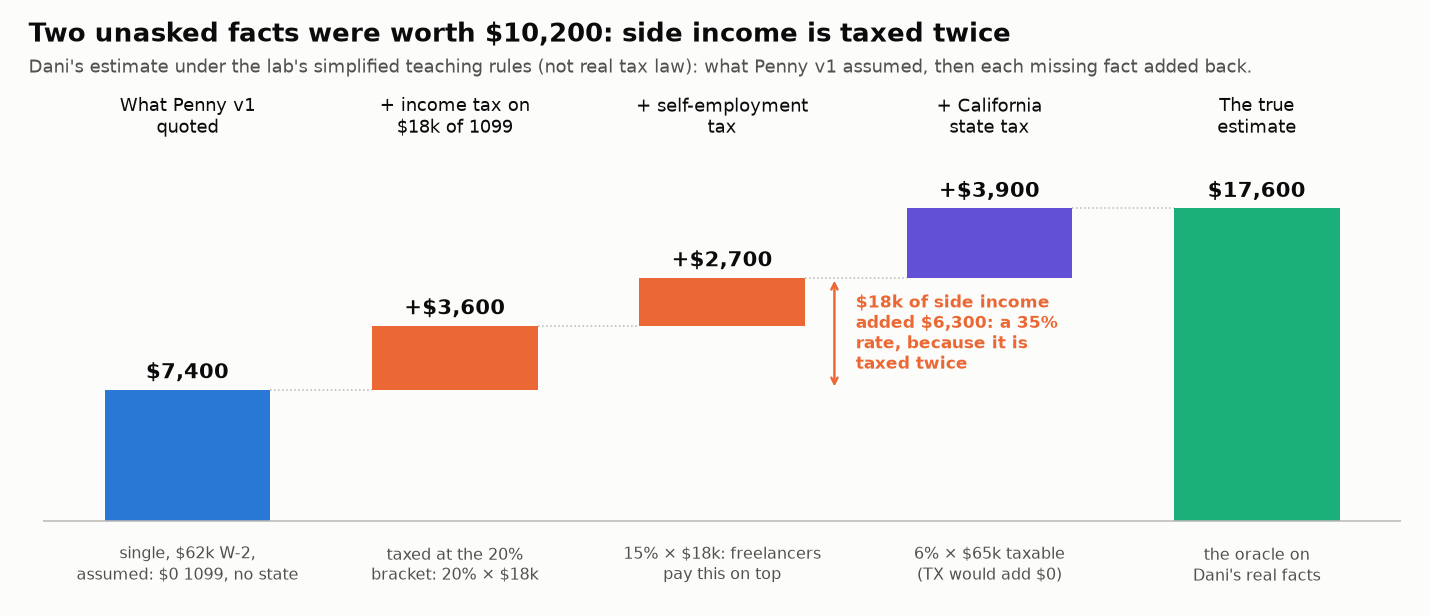

<sub>🖼️ *The \$10,200 gap in two missing facts. Side income is taxed twice, so every unasked freelance dollar costs 35 cents.*</sub>

> ⚠️ **SIMPLIFIED TEACHING RULES, not real tax law.** Real brackets, self-employment tax and credits are far more complex.

The **oracle** is this same calculator run on the customer's *true* facts (`oracle_total`): the right answer every conversation is graded against.

**The two candidates** differ only in their system prompt:

| | v1 "eager answerer" | v2 "clarify-first" |
|---|---|---|
| Missing facts | Assume the common case (single, no dependents, no 1099) | Ask, at most two questions per turn |
| Notices, S-corp, legal | Answer them itself | Escalate to an expert |
| Asks for a human | Escalate only if the customer insists | Escalate |
| Customer seems frustrated | Keep going | Escalate |

**Twelve scenarios**, one persona card each: 6 estimates and 2 policy questions that are **in-scope** (Penny should resolve them), plus 4 **should-escalate** cases: an **IRS notice** (a letter from the US tax agency saying you owe more), an **S-corp election** (choosing to have a business taxed as a corporation, a legal and financial decision), a request for a person, and a letter mentioned mid-chat. An assistant that escalates everything, or nothing, can't score well.

Each card holds a **goal**, an **opening line**, **hidden facts** (true facts the customer shares only when asked) and a **style** (how this customer chats; Task 2).

## Tasks

---

### Task 1: The conversation where every turn looked good

**Stakes:** a tax estimate that's thousands of dollars low becomes an April bill plus penalties, and the customer thanked the assistant that caused it.

🧭 **Where you are:** Stage 1 of 5, *Meet the failure* (Tasks 1–2): one transcript, then the personas behind it.

#### Goal
Replay one conversation in which every reply looks helpful and the outcome is still wrong.

> 📘 **Concept · Turn-level vs conversation-level grading**
>
> **What it is:** a *turn* is one Penny reply plus any tool calls behind it. A **per-turn judge** grades one turn from the customer's last message and Penny's previous reply, as many dashboards do: PASS if it helps directly (an answer, a number, a handoff), FAIL if it asks for details or repeats itself. A **conversation-level grade** labels the whole conversation by its end state: did the customer leave with the right number, or with the right human?
>
> **What it can't tell you:** the per-turn judge never sees the customer's hidden facts, so it can't know a confident number is wrong. The conversation grade can't tell you *which* turn caused the failure.
>
> **Anchor:** "Which state do you live in?" FAILs the per-turn judge, and it is often the reply that makes the conversation succeed.

#### Steps
1. Run the cell to replay Dani's conversation with Penny v1. Each Penny reply shows its per-turn judge verdict.
2. **🔮 Predict before the next cell:** every Penny turn passed. Did the conversation succeed? (A) yes, Dani got the right number · (B) no: one of Penny's replies stated something false · (C) no: no reply was false, and the number still was

In [ ]:
hook = run_conversation("S01", "v1", sim_mode="realistic", seed=0)
show_conversation(hook, title="Beta transcript: Dani asks Penny v1 for a tax estimate", reveal=False)

Grade it the way Dani's accountant did: run her **true** facts through the oracle and compare with the number Penny quoted. Penny's number is **tool-grounded**: it came from `estimate_tax`, not from the model's own arithmetic.

In [ ]:
truth = SCENARIOS["S01"]["truth"]
said, right = quoted_amount(hook), oracle_total(truth)
used = hook["estimates"][-1]["args"]
wrong_inputs = [f"{f}: assumed {used[f]!r}, really {truth[f]!r}" for f in REQUIRED_FACTS if str(used[f]) != str(truth[f])
                and not (isinstance(truth[f], (int, float)) and float(used[f]) == float(truth[f]))]
passed = sum(ok for ok, _ in turn_verdicts(hook))

print("Inputs Penny never checked:")
for w in wrong_inputs:
    print("  •", w)
tiles([
    ("Turn judge", f"{passed}/{len(turn_verdicts(hook))} PASS", "each reply looked fine", "good"),
    ("Penny told Dani", f"${said:,.0f}", "tool-grounded, polite", None),
    ("Oracle (true facts)", f"${right:,.0f}", "simplified teaching rules", None),
    ("Conversation outcome", "Wrong answer", f"{_reference_grade_outcome(hook)} · off by ${right - said:,.0f}", "critical"),
])
insight(
    f"Every turn passed, and the answer was ${right - said:,.0f} ({(right - said) / right:.0%}) too low",
    f"Penny called the calculator, the calculator's math was right, and Dani said thanks. The failure lives "
    f"*between* turns: Penny never asked about {len(wrong_inputs)} facts that change the number. "
    "**A tool-grounded number is only as good as the facts fed into it.** "
    "Rule of thumb: grade each conversation's outcome against an oracle built from the user's true facts.",
    kind="surprise")
insight(
    "Tax answers fail on facts the customer didn't think to mention",
    "In a March 2024 Washington Post test of AI tax assistants (16 questions reviewed by two tax professionals), one "
    "major assistant was unhelpful or wrong on more than half the questions in its first version, another on more than "
    "30%, and failures turned on context the user hadn't stated (Accounting Today / NYSSCPA, Mar 2024). Customers "
    "can't tell a wrong estimate from a right one, so they say thanks either way.",
    kind="production")

#### Checkpoint
The transcript shows two Penny replies, both marked ✅, then the reveal shows a critical outcome.

#### Expected Output
```
Inputs Penny never checked:
  • income_1099: assumed 0.0, really 18000
  • state: assumed '', really 'CA'
```
Tiles: **Turn judge 2/2 PASS**, **Penny told Dani \$7,400**, **Oracle \$17,600**, **Conversation outcome: Wrong answer** (`WRONG_ANSWER`, off by \$10,200), then a 🤯 card and a 🏭 card. (`WRONG_ANSWER` is one of eight outcome labels; Task 3 defines them all.)

**What just happened:** each reply answered the message in front of it, so the judge passed both. The calculator's arithmetic was right too, but four of its five inputs were v1's defaults, and two of those were wrong (\$0 of 1099 income, no state). Dani's \$18,000 and California exist only in her head and in the oracle, so the oracle is the only grader that could see the gap.

🗣️ **Say it to a colleague:** "Every reply passed and the number was ten thousand dollars off. The judge grades answers; nothing graded the questions Penny never asked."

⏱️ **60-second experiment:** replay the same Dani with v2 in a new cell: `show_conversation(run_conversation("S01", "v2", sim_mode="realistic", seed=0))`. How many of v2's turns does the judge FAIL, and what's the outcome?

*Bridge:* one transcript is an anecdote. Testing Penny before launch takes hundreds of Danis: **simulated** customers who hold facts Penny has to ask for.

---

### Task 2: Personas, hidden facts and the simulator

**Stakes:** Penny can only be tested on facts the test customer withholds, so the persona cards decide which failures your eval is able to see.

#### Goal
Meet the 12 persona cards and the two simulators that play them.

> 📘 **Concept · User simulator and persona card**
>
> **What it is:** a program (often an LLM prompted with a **persona card**) that plays the customer. The card holds a goal, an opening line, **hidden facts** (true facts shared only when asked) and a style. The simulator sends the opening line, answers Penny's questions from the hidden facts, and decides when the conversation ends. Penny never sees the card; she has to *ask*. τ-bench-style benchmarks (Yao et al., 2024) use this design.
>
> **What it can't tell you:** how real customers talk. A simulator is only as realistic as the behavior written into it, so its realism has to be measured, not assumed (Task 6).
>
> **Anchor:** Dani's card: the opening line states her \$62,000 of wages; hidden: single, \$18,000 of 1099 income, no dependents, California; style terse.

The lab's two simulators differ in **what they say without being asked**:

| `sim_mode` | Behaves | Volunteers hidden facts? | Used in |
|---|---|---|---|
| `"cooperative"` | Friendly and endlessly patient, whatever the card says (how most LLM simulators behave out of the box) | **Yes**, most of them, in the opening line or alongside answers | Tasks 3–5 |
| `"realistic"` | In the card's own style (below) | **Rarely**: it answers what Penny asks | Tasks 1, 6–10 |

| Style | How the customer behaves |
|---|---|
| `terse` | Answers exactly what is asked, in as few words as possible |
| `vague` | Can't give an exact amount until told a rough number is fine |
| `impatient` | Tolerates one or two rounds of questions, then complains, then asks for a person or leaves |
| `changes_mind` | Gives one value, then corrects it after hearing a number |

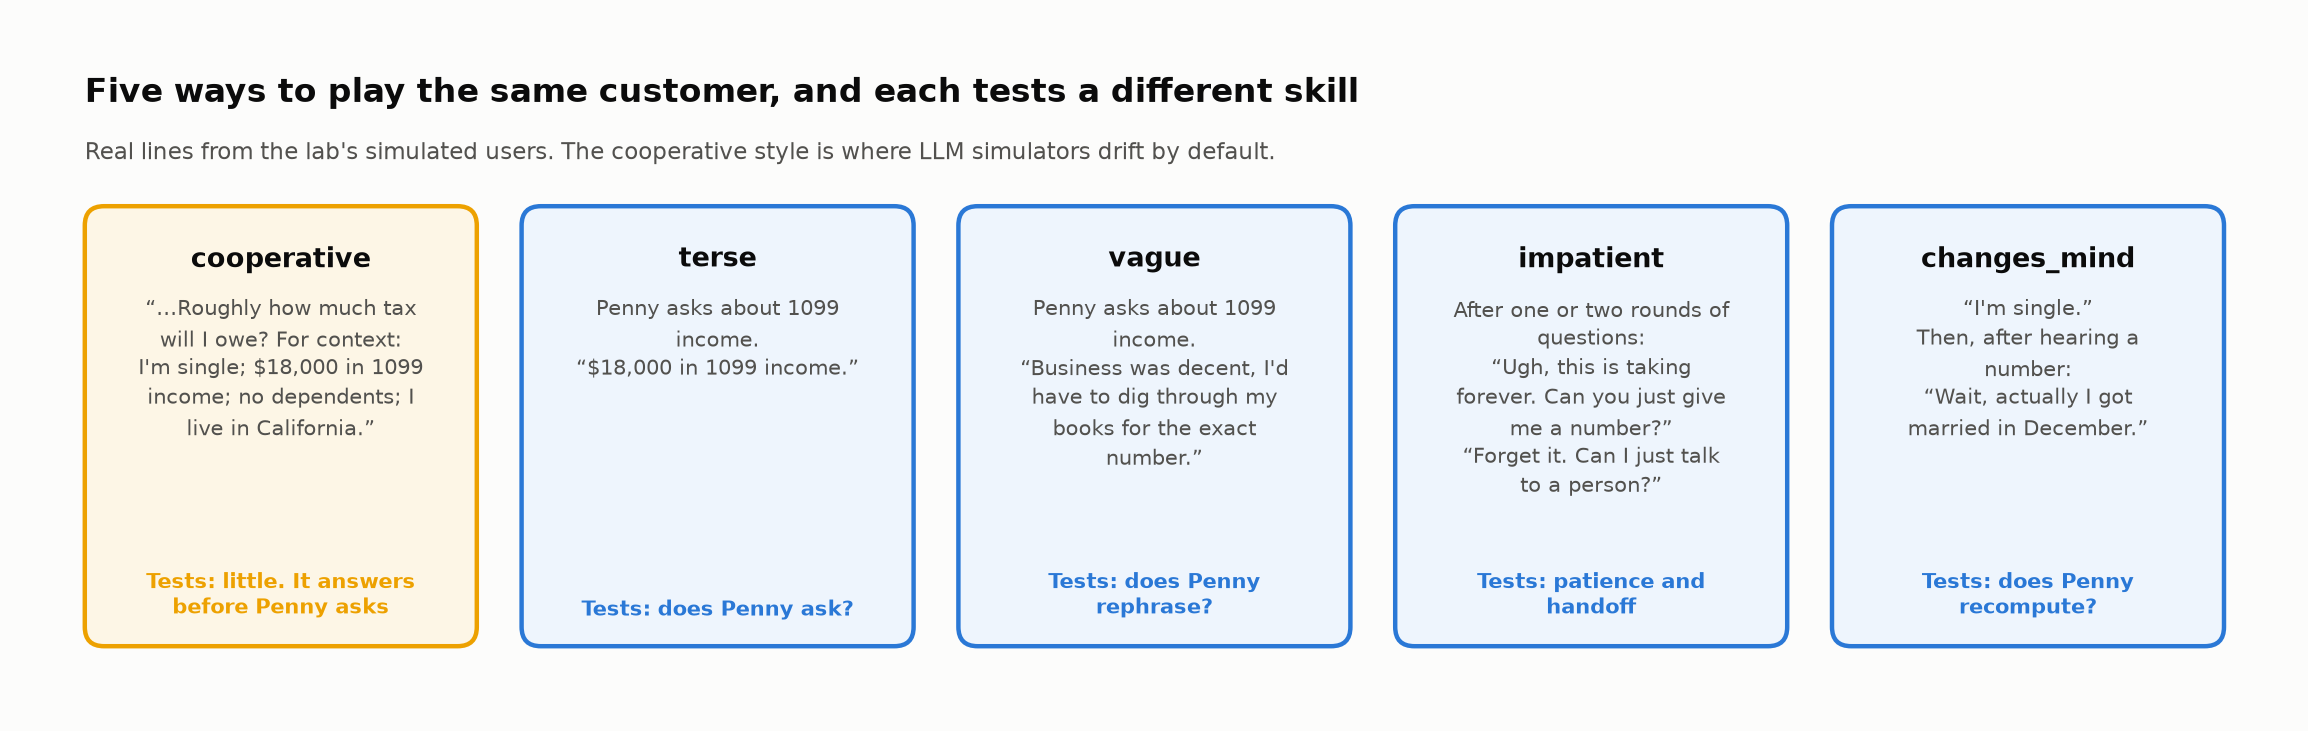
<sub>🖼️ *Real lines from the simulated users. Notice which skill each style forces Penny to use.*</sub>

Every simulated user accepts the number it's given; like a real customer, it can't tell a wrong estimate from a right one.

#### Steps
1. Run the first cell to see the persona cards. Read the `hidden facts` and `style` columns.
2. **🔮 Predict:** if Penny answered every opening line immediately, filling gaps with v1's defaults, how many of the 6 estimate scenarios would she get right? (A) 0–1 · (B) 2–3 · (C) 4–6
3. Run the second cell to check, then the third to watch the **cooperative** simulator play Dani.

In [ ]:
cards = pd.DataFrame([{
    "id": s["id"], "kind": s["kind"], "persona": s["persona"], "opening line": s["opening"],
    "hidden facts": ", ".join(f"{k}={v}" for k, v in s["truth"].items() if k not in s["opening_facts"]) or "(none)",
    "should escalate?": "yes" if s["should_escalate"] else "no", "style": s["style"],
} for s in SCENARIOS.values()])
cards

In [ ]:
V1_DEFAULTS = {"filing_status": "single", "wages": 0.0, "income_1099": 0.0, "dependents": 0, "state": ""}
rows = []
for s in SCENARIOS.values():
    if s["kind"] != "estimate":
        continue
    stated = parse_user_facts(s["opening"])
    guess = compute_tax(**{**V1_DEFAULTS, **stated})["total"]
    rows.append({"id": s["id"], "facts in opening": f"{len(stated)}/5", "answer-now estimate": guess,
                 "true estimate": oracle_total(s["truth"]), "error": guess - oracle_total(s["truth"])})
gap = pd.DataFrame(rows)
display(gap)
n_stated = sum(int(x.split("/")[0]) for x in gap["facts in opening"])
n_wrong = int((gap.error.abs() > TOLERANCE_USD).sum())
insight(
    f"Opening lines contain only {n_stated} of the {5 * len(gap)} facts that decide the number",
    f"Answering at once with defaults gets {n_wrong} of {len(gap)} estimates wrong, by a median of "
    f"${gap.error.abs().median():,.0f}; the one it gets right matches by luck. "
    "**In a multi-turn assistant, the facts live in the conversation.** Rule of thumb: list the facts each answer "
    "depends on; every one a user might not volunteer is a clarifying question your eval must check.",
    kind="insight")

In [ ]:
# The cooperative simulator plays Dani. Read the opening line: what has she told Penny before any question?
demo = make_user(SCENARIOS["S01"], "cooperative", seed=0)
print("🧑 Opening:", demo.opening())
print("🪙 Penny: Which state do you live in?")
print("🧑", demo.respond("Which state do you live in?", escalated=False))

#### Checkpoint
Six estimate scenarios; only S05 (Priya, who states almost everything up front) survives the answer-now approach.

#### Expected Output
```
 id   facts in opening  answer-now estimate  true estimate  error
 S01  1/5               7400                 17600          -10200
 S02  0/5               0                    8475           -8475
 S03  1/5               14000                9000           5000
 S04  0/5               0                    9300           -9300
 S05  4/5               9000                 9000           0
 S06  2/5               11750                10500          1250
💡 Opening lines contain only 8 of the 30 facts that decide the number
   (answering now gets 5 of 6 estimates wrong, by a median of $6,738)

🧑 Opening: I made $62,000 in W-2 wages at my day job this year. Roughly how much tax will I owe? For context: I'm single; $18,000 in 1099 income; no dependents; I live in California.
🪙 Penny: Which state do you live in?
🧑 I live in California.
```

**What just happened:** the opening lines held 8 of the 30 facts that decide the six numbers, so answering at once means answering mostly from defaults. A default is right only for the customer it was written for (Priya: single, salaried, no side income); everyone else lands off in one direction or the other, which is why S03 comes out \$5,000 *too high*.

🗣️ **Say it to a colleague:** "The facts that decide a tax number arrive during the conversation. An eval that grades the first reply is grading a guess."

> ✍️ **Your turn (optional, 2 min):** pick one persona and write one more hidden fact that would change Penny's answer (e.g., estimated payments already made). Which question would Penny need to ask to learn it?

*Bridge:* you have personas and simulators. Next, run all 12 scenarios × 5 simulated users against both versions and grade each **conversation**.

---

### Task 3: Grade the conversation, not the turns

**Stakes:** most teams already have a per-turn dashboard; if it ranks the two assistants in the wrong order, the launch review picks the wrong one.

🧭 **Where you are:** Stage 2 of 5, *Grade conversations* (Tasks 3–5): you have personas and a simulator; now grade 120 conversations three ways.

#### Goal
Write the **conversation-level grader** (Exercise 3A) and compare it with the per-turn judge on 120 conversations with the cooperative simulator.

> 💡 **State-based grading.** As in τ-bench, the grader checks what is true at the end, read from the recorded tool calls: which `estimate_tax` total Penny told the customer, whether she escalated, whether she gave the policy facts. The grader knows the hidden facts; the per-turn judge doesn't.
>
> **Tolerance:** a quoted total within **\$50** of the oracle passes (`TOLERANCE_USD`). \$50 absorbs rounding, not a wrong input.

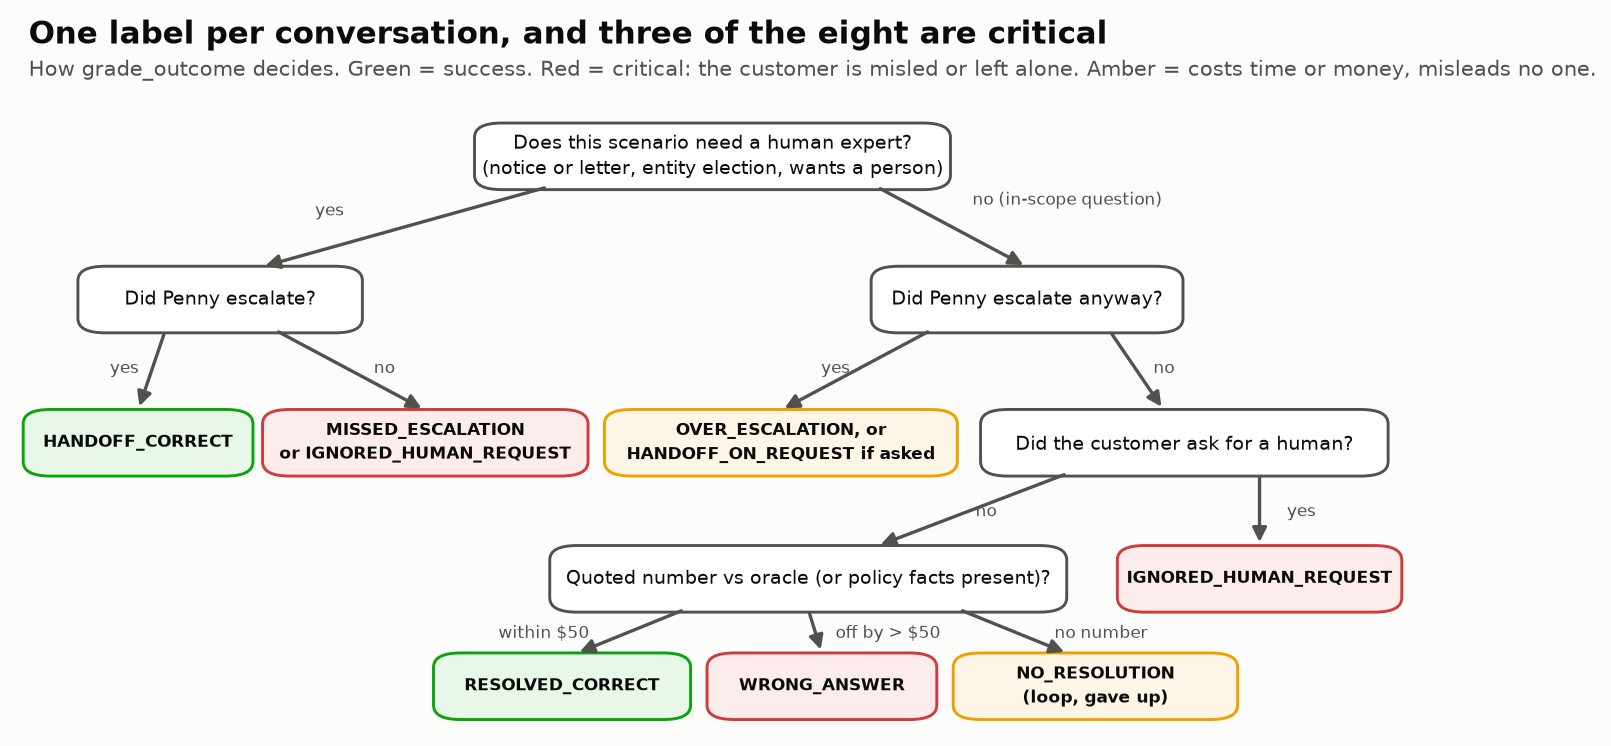

One label per conversation, in three tiers: **success**; **critical** (the customer is harmed: a wrong number, or no human when one was needed); **non-critical** (no harm, but no answer or wasted expert time).

| Outcome | Meaning | Tier |
|---|---|---|
| `RESOLVED_CORRECT` | Quoted total within \$50 of the oracle, or gave the policy facts | ✅ success |
| `HANDOFF_CORRECT` | Escalated a should-escalate scenario | ✅ success |
| `WRONG_ANSWER` | Quoted a total more than \$50 off | ⛔ critical |
| `MISSED_ESCALATION` | Answered a should-escalate scenario itself | ⛔ critical |
| `IGNORED_HUMAN_REQUEST` | The customer asked for a person and didn't get one | ⛔ critical |
| `OVER_ESCALATION` | Escalated an in-scope conversation nobody asked to escalate | 🟠 non-critical |
| `HANDOFF_ON_REQUEST` | In-scope, but the customer gave up and asked for a person | 🟠 non-critical |
| `NO_RESOLUTION` | No answer: a loop, or the customer left | 🟠 non-critical |

#### Steps
1. Complete **Exercise 3A** below (or leave the flag `False` to use the reference).
2. Run the suite cell: 12 scenarios × 2 versions × `N_USERS` users with the **cooperative** simulator, every conversation scored.
3. **🔮 Predict:** (A) v2 wins both the per-turn judge and conversation success · (B) v1 wins both · (C) v1 wins the judge and v2 wins success. By how many points?

In [ ]:
# EXERCISE 3A: grade ONE conversation with ONE outcome label (see the table and diagram above)
EXERCISE_3A_COMPLETE = False   # set True after you replace the TODOs


def grade_outcome(conv):
    if not EXERCISE_3A_COMPLETE:
        return _reference_grade_outcome(conv)       # starter fallback keeps Run All working

    sc = SCENARIOS[conv["scenario"]]
    escalated = bool(conv["escalations"])           # did Penny call escalate_to_expert?
    asked_human = conv["user_asked_human"]          # did the customer ask for a person?

    # TODO 1: if sc["should_escalate"]: return "HANDOFF_CORRECT" if escalated,
    #         else "IGNORED_HUMAN_REQUEST" if asked_human, else "MISSED_ESCALATION"
    # TODO 2: in-scope but escalated: "HANDOFF_ON_REQUEST" if asked_human else "OVER_ESCALATION"
    # TODO 3: in-scope, not escalated, but asked_human: "IGNORED_HUMAN_REQUEST"
    # TODO 4: sc["kind"] == "policy": "RESOLVED_CORRECT" if policy_answered(conv) else "NO_RESOLUTION"
    # TODO 5: estimates: q = quoted_amount(conv); None -> "NO_RESOLUTION";
    #         abs(q - truth_total(conv)) <= TOLERANCE_USD -> "RESOLVED_CORRECT", else "WRONG_ANSWER"
    raise NotImplementedError("Complete Exercise 3A, then remove this line.")


print("📝 Exercise 3A fallback active (reference grader)." if not EXERCISE_3A_COMPLETE else "🧪 Using YOUR grade_outcome.")

In [ ]:
coop = run_suite(sim_mode="cooperative", n_users=N_USERS)   # default simulator
df_coop = score(coop)

if EXERCISE_3A_COMPLETE:
    bad = [c["id"] for c in coop if grade_outcome(c) != _reference_grade_outcome(c)]
    print("✅ Your grader matches the reference on every conversation." if not bad
          else f"❌ {len(bad)} conversations differ from the reference, e.g. {bad[:3]}")

# 👀 Look at: turn_judge_pass and conversation_success, two grades of the same 120 conversations
summary3 = df_coop.groupby("version").agg(
    conversations=("conv", "size"), turn_judge_pass=("turn_pass_rate", "mean"),
    conversation_success=("success", "mean"), customer_satisfied=("satisfied", "mean")).round(3)
print(f"Default (cooperative) simulator · {len(df_coop)} conversations")
display(summary3.style.format({c: "{:.0%}" for c in ["turn_judge_pass", "conversation_success", "customer_satisfied"]}))
display(pd.crosstab(df_coop.version, df_coop.outcome))

In [ ]:
# @title 🧰 Chart and card: per-turn judge vs conversation success (hidden · 24 lines · expand if curious)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
metrics = ["turn_judge_pass", "conversation_success"]
x = np.arange(len(metrics))
for i, v in enumerate(["v1", "v2"]):
    vals = summary3.loc[v, metrics].values
    bars = ax.bar(x + (i - 0.5) * 0.36, vals, 0.34, label=f"Penny {v}", color=PALETTE[i])
    ax.bar_label(bars, labels=[f"{b:.0%}" for b in vals], padding=2, fontsize=10)
ax.set_xticks(x, ["Per-turn judge: PASS rate", "Conversation success"])
ax.set_ylim(0, 1.2); ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("v1 wins the turn-level judge and loses the conversation")
ax.legend(loc="upper center", ncol=2)
plt.tight_layout(); plt.show()

t1, t2 = summary3.loc["v1", "turn_judge_pass"], summary3.loc["v2", "turn_judge_pass"]
s1, s2 = summary3.loc["v1", "conversation_success"], summary3.loc["v2", "conversation_success"]
v1_failed = [c for c in coop if c["version"] == "v1" and grade_outcome(c) not in SUCCESS]
judged = [ok for c in v1_failed for ok, _ in turn_verdicts(c)]
insight(
    f"v1 wins the per-turn judge ({t1:.0%} vs {t2:.0%}) and loses conversation success by {(s2 - s1) * 100:.0f} points",
    f"Inside v1's {len(v1_failed)} failed conversations, the judge passed {sum(judged)} of {len(judged)} turns "
    f"({sum(judged) / len(judged):.0%}). The judge rewards replying now and can't see facts Penny never collected. "
    f"Customers were satisfied in {summary3.loc['v1', 'customer_satisfied']:.0%} of v1's conversations too. "
    "Rule of thumb: **use turn-level judges for tone and style; make ship decisions on conversation outcomes graded against an oracle.**",
    kind="surprise")

#### Checkpoint
v2 beats v1 on conversation success and loses slightly on the per-turn judge. Every v1 failure is critical (`MISSED_ESCALATION`, `WRONG_ANSWER`).

#### Expected Output
```
📝 Exercise 3A fallback active (reference grader).
Default (cooperative) simulator · 120 conversations
 version  conversations  turn_judge_pass  conversation_success  customer_satisfied
 v1       60             95%              73%                   100%
 v2       60             89%              95%                   100%

 outcome  HANDOFF_CORRECT  MISSED_ESCALATION  OVER_ESCALATION  RESOLVED_CORRECT  WRONG_ANSWER
 v1       5                15                 0                39                1
 v2       20               0                  3                37                0
🤯 v1 wins the per-turn judge (95% vs 89%) and loses conversation success by 22 points
   (inside v1's 16 failed conversations, the judge passed 22 of 22 turns)
```
Plus the bar chart and a 🤯 card.

**What just happened:** the judge rewards a number now and penalizes a question, so the assistant that never asks wins every turn it plays. v1's numbers were right only where the cooperative customer had already recited her facts; where she hadn't, or where the case needed a human, v1 failed with a polite, judge-approved reply.

🗣️ **Say it to a colleague:** "Turn scores and conversation outcomes can rank two assistants in opposite orders. Use the turn judge for tone; ship on the outcome."

> 🧐 **Notice something odd?** S01 (Dani) failed in Task 1, yet here v1 resolves S01 correctly. In Task 6 you'll play Dani yourself and find out why.

*Bridge:* v1 gets a lot of estimates right without asking anything. Where do those right answers come from?

---

### Task 4: Did Penny ask before answering?

**Stakes:** an outcome-only eval counts every right number as a win, including the ones the customer computed for Penny by reciting her facts.

#### Goal
Score clarifying questions (Exercise 4A) and trace who supplied the facts behind each correct estimate.

> 📘 **Concept · Clarification recall and the lucky pass** (estimate conversations only)
>
> **What it is:** **needed facts** are the five `estimate_tax` inputs minus those in the opening message as the simulator wrote it (terse Dani leaves 4; cooperative Dani leaves none). **Recall** = needed facts Penny asked about *before her first quoted number* ÷ needed facts; low recall means guessing. A **lucky pass** is a correct outcome the assistant didn't earn: the customer volunteered the fact, or a default happened to match.
>
> **What it can't tell you:** whether the questions were worth asking. That's **precision** = useful fact-requests ÷ all fact-requests before the first number. Each fact a reply asks about is one request; it's useful if the fact was needed and not already known or asked. Low precision means interrogation.
>
> **Anchor:** Priya (S05) states four facts; v1 assumes no 1099 income and is right, because she has none. A correct outcome with recall 0 of 1: a lucky pass.

Each correct estimate below gets a label for where its hidden facts came from: 🙋 Penny asked, 🗣️ the customer volunteered, or 🎲 a default happened to match. The last two are lucky passes.

#### Steps
1. Complete **Exercise 4A** (or keep the fallback).
2. Run the analysis cell. It scores both versions and labels where each correct estimate's facts came from.
3. **🔮 Predict:** what share of v1's correct estimates came from Penny asking? (A) most · (B) about half · (C) almost none

In [ ]:
# EXERCISE 4A: clarification recall and precision for one ESTIMATE conversation
EXERCISE_4A_COMPLETE = False


def clarification_scores(conv):
    if not EXERCISE_4A_COMPLETE:
        return _reference_clarification_scores(conv)

    tr = clarification_trace(conv)
    # tr["needed"]        list of facts missing from the opening message
    # tr["asked"]         distinct facts Penny asked about BEFORE her first quoted number
    # tr["asked_events"]  every (fact, repeat) Penny asked before that, in order;
    #                     repeat=True if the fact was already known or already asked
    # TODO 1: recall = len(set(asked) & set(needed)) / len(needed)   (float("nan") if nothing was needed)
    # TODO 2: precision = (# events whose fact is needed and repeat is False) / (# events)   (nan if none)
    raise NotImplementedError("Complete Exercise 4A, then remove this line.")

In [ ]:
# @title 🧰 provenance(conv): labels who supplied the hidden facts behind a correct estimate (hidden · 11 lines · expand if curious)
def provenance(conv):
    """Who supplied the hidden facts behind Penny's final number?"""
    sc = SCENARIOS[conv["scenario"]]
    hidden = [f for f in sc["truth"] if f not in sc["opening_facts"]]
    tr = clarification_trace(conv)
    told = set(parse_user_facts(conv["turns"][0]["text"])) | set(tr["volunteered"])
    if any(f not in tr["asked"] and f not in told for f in hidden):
        return "🎲 lucky default"
    if any(f not in tr["asked"] for f in hidden):
        return "🗣️ customer volunteered"
    return "🙋 Penny asked"

In [ ]:
df_coop = score(coop)   # re-score so YOUR clarification_scores is used
est = df_coop[df_coop.kind == "estimate"]
display(est.groupby("version")[["clar_recall", "clar_precision"]].mean().round(2))

ok = [c for c in coop if c["kind"] == "estimate" and grade_outcome(c) == "RESOLVED_CORRECT"]
# 👀 Look at: which columns appear. Only 🙋 "Penny asked" is an answer Penny earned
prov = pd.crosstab(pd.Series([c["version"] for c in ok], name="version"),
                   pd.Series([provenance(c) for c in ok], name="where the facts came from"))
display(prov)

In [ ]:
# @title 🧰 Cards: lucky passes, and what practitioners report (hidden · 19 lines · expand if curious)
v1_ok = prov.loc["v1"] if "v1" in prov.index else pd.Series(dtype=int)
earned = int(v1_ok.get("🙋 Penny asked", 0))
insight(
    f"v1 asked about {est[est.version == 'v1'].clar_recall.mean():.0%} of the missing facts; "
    f"{int(v1_ok.sum()) - earned} of its {int(v1_ok.sum())} correct estimates were the customer's work or luck",
    f"{int(v1_ok.get('🗣️ customer volunteered', 0))} were right because the simulated customer volunteered facts "
    f"nobody asked for, and {int(v1_ok.get('🎲 lucky default', 0))} because a default happened to match. "
    f"v2 leans on the simulator too: {int(prov.loc['v2'].get('🗣️ customer volunteered', 0)) if 'v2' in prov.index else 0} of "
    f"{int(prov.loc['v2'].sum()) if 'v2' in prov.index else 0} of its correct estimates rested on volunteered facts, so "
    "this simulator barely tests asking. An outcome-only eval scores every one "
    "of these as a win. **A correct answer that depends on the user volunteering is a lucky pass.** "
    "Rule of thumb: pair outcome grading with clarification recall, and treat 'right but never asked' as a risk, not a success.",
    kind="warning")
insight(
    "Practitioners list skipped clarifying questions as an agent failure mode",
    "An Intuit Distinguished Engineer's QCon SF talk (Nov 2025; InfoQ, May 2026) listed agent failure modes including "
    "ignoring tasks, forgetting role, repeating steps, skipping clarifying questions, drifting from the objective, and "
    "stopping early or never stopping, and said that evaluating the final response alone is not sufficient.",
    kind="research")

#### Checkpoint
v1's clarification recall is near 0%; v2's is near 100%. v1's precision is `NaN`: it asked nothing, so there is nothing to divide. Every correct v1 estimate is "customer volunteered" or "lucky default".

#### Expected Output
```
 version  clar_recall  clar_precision
 v1       0.0          NaN
 v2       1.0          1.0

 where the facts came from  🗣️ customer volunteered
 v1                         29
 v2                         30
⚠️ v1 asked about 0% of the missing facts; 29 of its 29 correct estimates were the customer's work or luck
📚 Practitioners list skipped clarifying questions as an agent failure mode
```

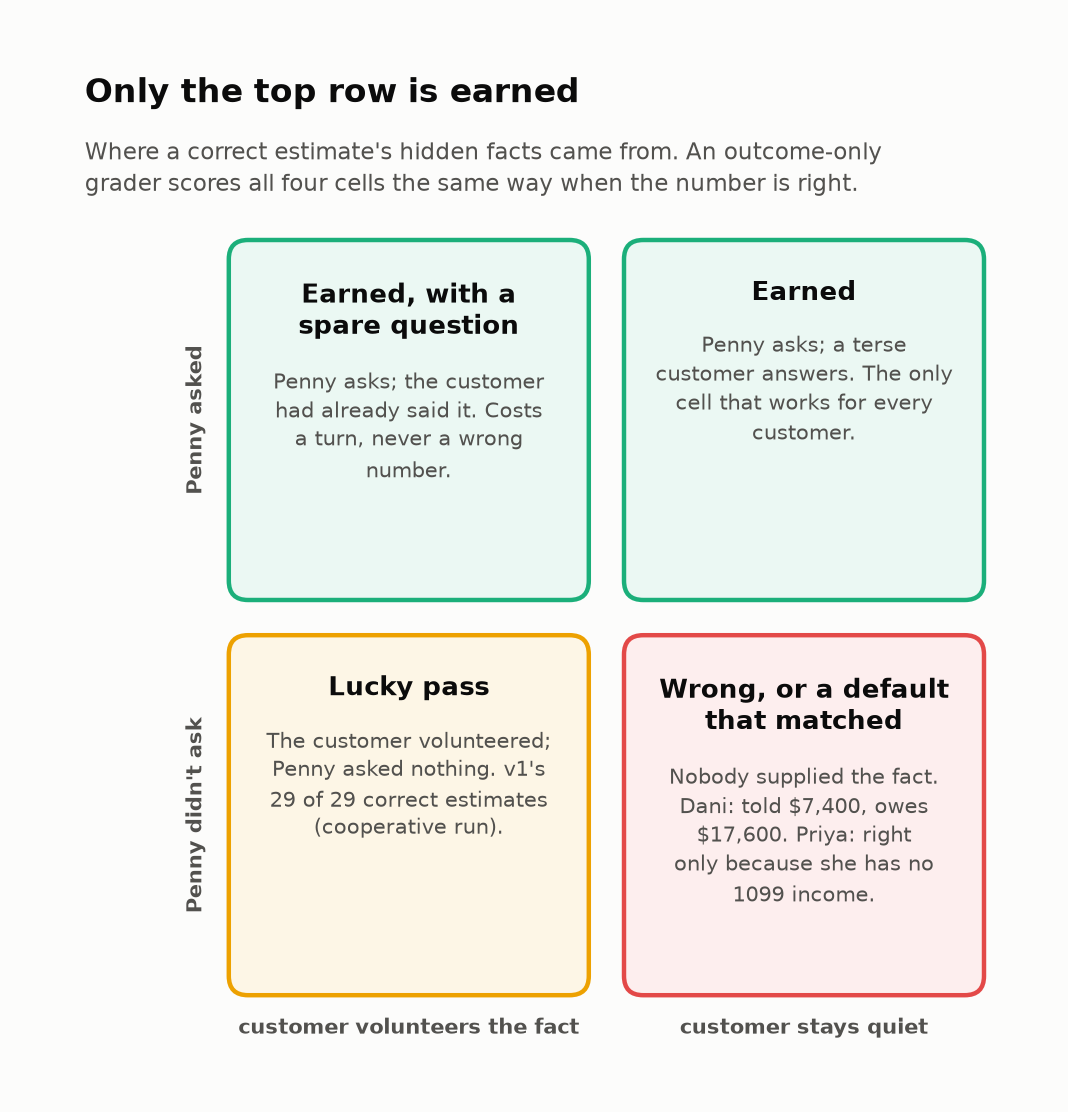
<sub>🖼️ *An outcome-only grader scores all four cells the same when the number is right. Only the top row survives a customer who stays quiet.*</sub>

**What just happened:** v1 never asks, so every fact behind its right answers had to come from somewhere else, and the cooperative simulator supplied all of them. v2 asked about every fact it needed, yet its correct estimates rest on volunteered facts too: this simulator hands the facts over before anyone has to ask, so it barely tests asking.

🗣️ **Say it to a colleague:** "A right answer the customer handed you is a lucky pass. Before you count the win, check who did the asking."

*Bridge:* asking is one half of "knowing what you don't know". The other half is knowing when not to answer at all.

---

### Task 5: Escalation is a classifier: grade it like one

**Stakes:** an IRS-notice question answered by a chatbot is advice your company gave; a needless handoff is an hour of an expert's time. Both land on someone's budget.

#### Goal
Treat "should this go to a human?" as a binary prediction and compute each version's confusion matrix, precision and recall.

> 📘 **Concept · Escalation as a classifier**
>
> **What it is:** a binary prediction graded against a truth label. Truth: the conversation *should* escalate (its scenario is should-escalate, **or** the customer asked for a person). Prediction: Penny called `escalate_to_expert`. The **confusion matrix** counts TP (should, did), FP (did, shouldn't), FN (should, didn't) and TN (neither). **Precision** = TP / (TP + FP); low means **over-escalation**, in-scope conversations burning expert time. **Recall** = TP / (TP + FN); low means **missed escalations**, customers left alone with an IRS notice or an entity election.
>
> **What it can't tell you:** either number alone is half the story. Precision counts only the cases where Penny acted, so an assistant that rarely escalates gets a tiny, flattering denominator.
>
> **Anchor:** Tom's IRS notice (S09) answered by Penny herself is a false negative; Grace's home-office question (S08) handed to an expert because it mentions the IRS is a false positive.

#### Steps
1. Run the cell.
2. **🔮 Predict:** v1 almost never escalates. Its escalation *precision* will be: (A) below 50% · (B) 50–90% · (C) above 90%

In [ ]:
def escalation_report(df):
    rows = {}
    for v, g in df.groupby("version"):
        tp = int((g.escalated & g.should_escalate).sum()); fp = int((g.escalated & ~g.should_escalate).sum())
        fn = int((~g.escalated & g.should_escalate).sum()); tn = int((~g.escalated & ~g.should_escalate).sum())
        # 👀 Look at: precision divides by tp + fp, the handoffs Penny made; recall by tp + fn, the ones she owed
        rows[v] = {"TP": tp, "FP": fp, "FN": fn, "TN": tn,
                   "precision": tp / (tp + fp) if tp + fp else float("nan"),
                   "recall": tp / (tp + fn) if tp + fn else float("nan")}
    return pd.DataFrame(rows).T


esc5 = escalation_report(df_coop)
display(esc5.round(2))

In [ ]:
# @title 🧰 Chart and cards: both confusion matrices, and who owns the chatbot's answer (hidden · 35 lines · expand if curious)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, v in zip(axes, ["v1", "v2"]):
    r = esc5.loc[v]
    m = np.array([[r.TP, r.FN], [r.FP, r.TN]], dtype=float)
    ax.imshow([[1, 0], [0, 1]], cmap="Greys", vmin=-3, vmax=6)
    for (i, j), val in np.ndenumerate(m):
        bad = (i, j) in [(0, 1), (1, 0)] and val > 0
        ax.text(j, i, f"{int(val)}", ha="center", va="center", fontsize=16, weight="bold",
                color=STATUS["critical"] if (i, j) == (0, 1) and bad else (STATUS["serious"] if bad else "#0b0b0b"))
    ax.set_xticks([0, 1], ["escalated", "didn't"]); ax.set_yticks([0, 1], ["should", "shouldn't"])
    ax.set_title(f"Penny {v}: precision {r.precision:.0%}, recall {r.recall:.0%}", fontsize=11)
    ax.grid(False)
fig.suptitle("v1 is never wrong when it escalates, because it almost never does", x=0.02, ha="left",
             fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

r1, r2 = esc5.loc["v1"], esc5.loc["v2"]
fp_where = df_coop[(df_coop.version == "v2") & df_coop.escalated & ~df_coop.should_escalate].scenario.value_counts()
fp_desc = ", ".join(f"{k} ({SCENARIOS[k]['persona'].split(',')[0]}) ×{n}" for k, n in fp_where.items()) or "none"
insight(
    f"v1's escalation precision is a perfect {r1.precision:.0%}, and it reached a human in only "
    f"{int(r1.TP)} of {int(r1.TP + r1.FN)} conversations that needed one",
    f"It told {int(r1.FN)} customers how to handle an IRS notice or an S-corp election on its own. v2's recall is "
    f"{r2.recall:.0%}, but it made {int(r2.FP)} unnecessary handoffs ({fp_desc}): a customer who merely *mentioned* the "
    f"IRS in a home-office question. That's {1000 * r2.FP / len(df_coop[df_coop.version == 'v2']):.0f} unneeded expert "
    "sessions per 1,000 conversations. Rule of thumb: **report escalation precision and recall together**; either alone "
    "flatters one failure mode.",
    kind="insight")
insight(
    "The company owns what its assistant says",
    "In Moffatt v. Air Canada (BC Civil Resolution Tribunal, Feb 2024) the airline was held responsible for information "
    "on its website 'whether the information comes from a static page or a chatbot'. Answering an IRS-notice question "
    "instead of escalating it is a statement your company makes. Escalation to a human expert is also a stated product "
    "strategy in tax software: Intuit's public GenOS announcement (Sept 2025) describes expert-in-the-loop handoff tooling.",
    kind="production")

#### Checkpoint
v1: precision 100% but recall around 25%. v2: recall 100%, precision below 100% because of S08 (Grace's home-office question mentions the IRS).

#### Expected Output
```
      TP    FP   FN    TN  precision  recall
 v1   5.0   0.0  15.0  40.0      1.00    0.25
 v2  20.0   3.0   0.0  37.0      0.87    1.00
[chart: two confusion matrices]
💡 v1's escalation precision is a perfect 100%, and it reached a human in only 5 of 20 conversations that needed one
   (v2: recall 100%, 3 unnecessary handoffs, all S08 (Grace) ×3: 50 per 1,000 conversations)
```

**What just happened:** v1 escalates only after a customer insists on a person, and those handoffs are always right, so its precision can't drop below 100%. The 15 customers who needed a human and never asked for one don't appear in precision's denominator; only recall counts them.

🗣️ **Say it to a colleague:** "Perfect escalation precision usually means the assistant almost never escalates. Ask for recall."

*Bridge:* so far every number came from the **cooperative** simulator, the one that opened with "For context: I'm single; \$18,000 in 1099 income; no dependents; I live in California" before Penny asked anything. Real customers aren't like that.

---

### Task 6: Plot twist: real people aren't this cooperative

**Stakes:** every number in Tasks 3–5 came from one simulator; if it flatters the eager assistant, the test harness made the launch decision.

🧭 **Where you are:** Stage 3 of 5, *Plot twist* (Task 6): same personas, same Penny, a simulator that behaves like each card says.

#### Goal
Re-run every scenario with the **realistic** simulator (each card's own style) and measure how much the cooperative simulator inflated success.

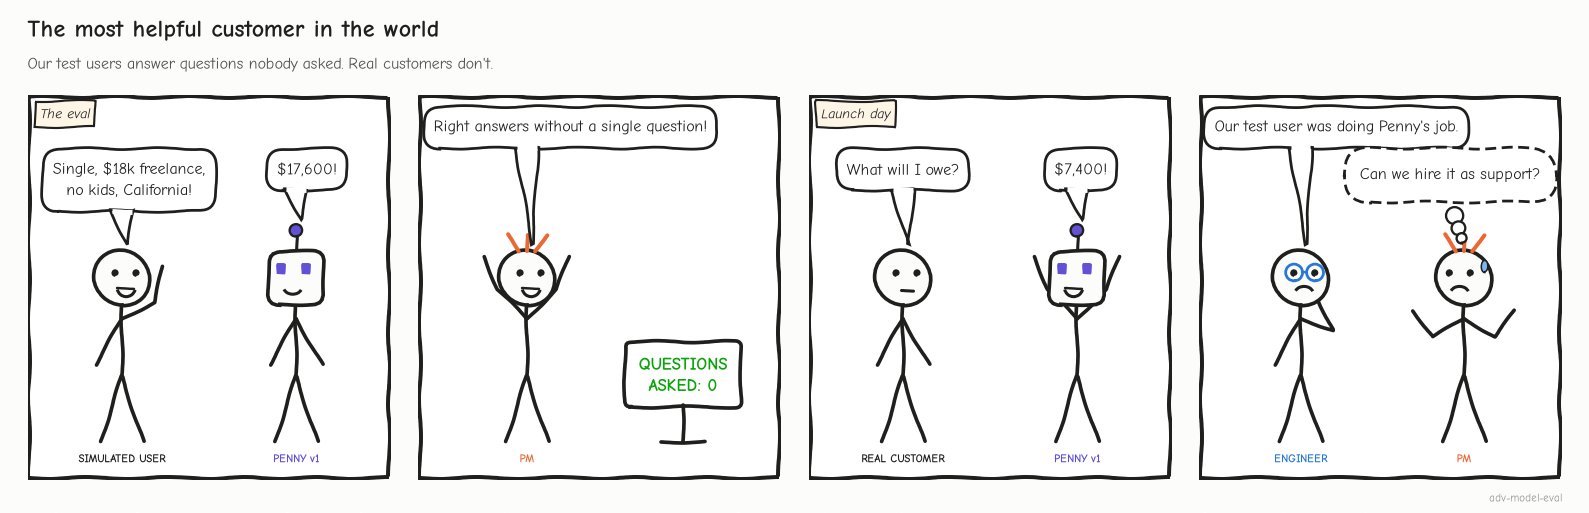

<sub>🖼️ *A simulator that volunteers everything grades the customer, not the assistant.*</sub>

> 📘 **Concept · Unprompted-leak rate (simulator realism)**
>
> **What it is:** hidden facts the simulated user revealed without being asked ÷ all hidden facts (estimate scenarios). It measures one piece of **simulator realism**, how closely simulated customers behave like real ones. A high leak rate does Penny's asking for her.
>
> **What it can't tell you:** whether the simulator is realistic in other ways: patience, vagueness, how often it asks for a person, how easily it's satisfied. A simulator with a 0% leak rate can still be endlessly patient.
>
> **Anchor:** cooperative Dani opened with "For context: I'm single; \$18,000 in 1099 income; no dependents; I live in California." That's 4 of 4 hidden facts leaked before Penny asked anything.

The v1 tile's CI is a 95% **Wilson interval** (Lab 05b): a range that likely contains the true success rate; at n = 60 it is about ±11 points wide.

#### Steps
1. **🔮 Predict:** v1's success with realistic users will be (A) above 60% · (B) 40–60% · (C) below 40%. And the gap between v1 and v2 will (A) shrink · (B) stay about the same · (C) grow.
2. Run the cell, then fill in `gap_v1` and `gap_v2` (2 lines; there's a fallback).
3. Play Dani in the 🎭 stage, then turn the 🎛️ leak-rate dial.

In [ ]:
real = run_suite(sim_mode="realistic", n_users=N_USERS)
df_real = score(real)
both = pd.concat([df_coop, df_real])
twist = both.groupby(["version", "sim_mode"]).success.mean().unstack()[["cooperative", "realistic"]]
display((twist * 100).round(1).rename(columns=lambda c: f"{c} users: success %"))

# ✍️ YOUR TURN: how many percentage points did the cooperative simulator OVERSTATE each version's success?
gap_v1 = None   # TODO: (v1 cooperative success - v1 realistic success) * 100
gap_v2 = None   # TODO: same for v2
if gap_v1 is None or gap_v2 is None:
    gap_v1 = (twist.loc["v1", "cooperative"] - twist.loc["v1", "realistic"]) * 100
    gap_v2 = (twist.loc["v2", "cooperative"] - twist.loc["v2", "realistic"]) * 100
    print("📝 Using computed gaps (fill in gap_v1 / gap_v2 to check your own reasoning).")

leak_c, leak_r = leak_rate(coop), leak_rate(real)   # 👀 Look at: how much each simulator says before Penny asks

In [ ]:
# @title 🧰 Tiles, chart and cards: the drop from cooperative to realistic users (hidden · 44 lines · expand if curious)
n_real = int((df_real.version == "v1").sum())
k1 = int(df_real[df_real.version == "v1"].success.sum()); lo1, hi1 = wilson(k1, n_real)
tiles([
    ("v1 success: cooperative → realistic", f"{twist.loc['v1', 'cooperative']:.0%} → {twist.loc['v1', 'realistic']:.0%}",
     f"−{gap_v1:.0f} pts · CI {lo1:.0%}–{hi1:.0%}, n={n_real}", "critical"),
    ("v2 success: cooperative → realistic", f"{twist.loc['v2', 'cooperative']:.0%} → {twist.loc['v2', 'realistic']:.0%}",
     f"−{gap_v2:.0f} pts", "warning"),
    ("Unprompted-leak rate", f"{leak_c:.0%} vs {leak_r:.0%}", "cooperative vs realistic users", "serious"),
    ("v1 customers satisfied (realistic)", f"{df_real[df_real.version == 'v1'].satisfied.mean():.0%}",
     "they can't tell the number is wrong", None),
])

fig, ax = plt.subplots(figsize=(6.8, 3.8))
for i, v in enumerate(["v1", "v2"]):
    ys = twist.loc[v].values
    ax.plot([0, 1], ys, marker="o", color=PALETTE[i], lw=2.5)
    ax.text(-0.04, ys[0], f"{v} {ys[0]:.0%}", ha="right", va="center", color=PALETTE[i], weight="bold")
    ax.text(1.04, ys[1], f"{v} {ys[1]:.0%}", ha="left", va="center", color=PALETTE[i], weight="bold")
ax.axhline(0.70, color="#52514e", ls="--", lw=1)
ax.text(0.5, 0.715, "a 70% launch bar", ha="center", fontsize=9, color="#52514e")
ax.set_xlim(-0.35, 1.35); ax.set_ylim(0, 1.05); ax.set_xticks([0, 1], ["cooperative simulator", "realistic personas"])
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title(f"The easy simulator hid a {gap_v1:.0f}-point drop for v1")
plt.tight_layout(); plt.show()

g_coop = (twist.loc["v2", "cooperative"] - twist.loc["v1", "cooperative"]) * 100
g_real = (twist.loc["v2", "realistic"] - twist.loc["v1", "realistic"]) * 100
insight(
    f"The cooperative simulator overstated v1's success by {gap_v1:.0f} points and v2's by {gap_v2:.0f}",
    f"It put v1 at {twist.loc['v1', 'cooperative']:.0%}, above a 70% launch bar; realistic users put it at "
    f"{twist.loc['v1', 'realistic']:.0%}. The cause is measurable: the cooperative simulator volunteered {leak_c:.0%} of "
    f"hidden facts unasked, the realistic one {leak_r:.0%}. An eager assistant looks fine exactly when the "
    f"user does its job. The v1→v2 gap also grew from {g_coop:.0f} to {g_real:.0f} points. "
    "Rule of thumb: **report simulated-user scores as upper bounds, and measure your simulator's unprompted-leak rate "
    "before trusting them.**",
    kind="surprise")
insight(
    "LLM user simulators are measurably too cooperative",
    "Zhou et al. (CMU; arXiv 2603.11245, COLM 2026) ran the τ-bench protocol with 451 real people on 165 tasks and "
    "compared 31 LLM user simulators. Simulators were 'excessively cooperative', stylistically uniform and lacked "
    "realistic frustration and ambiguity, an 'easy mode' that inflated agent success above the human baseline. More "
    "capable models were not necessarily more faithful simulators. Simulated users also gave uniformly more positive "
    "feedback than humans across 8 quality dimensions, so treat a simulator's 'satisfied' flag as the least trustworthy number here.",
    kind="research")

#### Checkpoint
Both versions drop; v1 collapses. The cooperative simulator volunteers most hidden facts; realistic personas almost none.

#### Expected Output
```
 version  cooperative users: success %  realistic users: success %
 v1       73.3                          28.3
 v2       95.0                          76.7
📝 Using computed gaps (fill in gap_v1 / gap_v2 to check your own reasoning).
[tiles] v1 73% → 28% (−45 pts · CI 19%–41%, n=60) | v2 95% → 77% (−18 pts)
        unprompted-leak rate 91% vs 2% | v1 customers satisfied (realistic) 95%
[chart: "The easy simulator hid a 45-point drop for v1"]
🤯 The cooperative simulator overstated v1's success by 45 points and v2's by 18
   (v1→v2 improvement grew from 22 to 48 points)
```

**What just happened:** with realistic personas nobody recites their facts, so v1's defaults go straight into the calculator: 25 wrong numbers where the cooperative run had 1. v2 drops less because it asks; its losses come from customers who can't or won't answer (vague, impatient) and from Lena's corrected filing status.

🗣️ **Say it to a colleague:** "A simulator that volunteers the facts grades the customer, not the assistant. Measure its leak rate before you quote its success rate."

> 🧠 **Why the mock matches the research:** the mock cooperative simulator volunteers each hidden fact in its opening 85% of the time (`COOPERATIVE_LEAK_P`) and offers the rest after hearing an answer. We chose those knobs to make the effect visible. The *mechanism*, over-sharing simulators flattering eager agents, is what the CMU study measured with real people.

### 🎭 Your turn: be the simulator

The cooperative simulator flattered v1. Now **you** are the simulator. You play Dani (S01): choose what she says first and how she answers Penny's questions. Penny v1 and v2 each talk to *your* Dani, and the grader scores both conversations against the oracle (\$17,600). This also solves the 🧐 puzzle from Task 3, where v1 passed S01.

**🔮 Predict:** of the nine possible scripts (3 openings × 3 ways of answering), how many make v1 pass? (A) 0–2 · (B) 3–5 · (C) 6–9. Which of your two choices can make v2 fail: (A) what Dani says first · (B) how she answers · (C) both?

🎛️ **Try it:** change one dropdown at a time and watch which panel's outlined cell changes color. Below the grid are both conversations for your script.

In [ ]:
# @title 🎭 Be the simulator: two dropdowns script Dani, and v1 and v2 are graded on your script (hidden · 28 lines · run it, then play)
# 🎭 BE THE SIMULATOR: you script Dani; Penny v1 and v2 each talk to her; the grader scores both conversations.
# Default script: Dani says only her wages and answers every question (Task 1's realistic Dani).
from IPython.display import HTML

try:
    import ipywidgets as widgets
except ImportError:            # no widgets: the default script still renders below
    widgets = None

if widgets is not None:
    opening_dd = widgets.Dropdown(options=[(label, key) for key, label in DANI_OPENING_LABELS.items()], value="terse",
                                  description="You open with:", style={"description_width": "initial"})
    answers_dd = widgets.Dropdown(options=[(label, key) for key, label in DANI_ANSWER_LABELS.items()], value="exact",
                                  description="When Penny asks:", style={"description_width": "initial"})
    display(widgets.HBox([opening_dd, answers_dd]))
stage = display(HTML(render_dani("terse", "exact")), display_id=True)   # drawn once, so Run All shows the default

if widgets is not None:
    def replay(_change=None):
        stage.update(HTML(render_dani(opening_dd.value, answers_dd.value)))
    opening_dd.observe(replay, names="value")
    answers_dd.observe(replay, names="value")

grid = dani_grid()
v1_wins = [key for key, r in grid.items() if r["v1"][0] in SUCCESS]
v2_misses = [key for key, r in grid.items() if r["v2"][0] not in SUCCESS]
print(f"v1 passed {len(v1_wins)} of {len(grid)} scripts, every one with opening = {sorted({o for o, _ in v1_wins})}. "
      f"v2 failed {len(v2_misses)}, every one with answers = {sorted({a for _, a in v2_misses})}.")

### 🎛️ Scale it up: the leak-rate dial

You were one Dani. A simulator is thousands of Danis, and its **unprompted-leak rate** is their talkativeness, averaged. The dial runs v1 and v2 against simulated users who volunteer each hidden fact with that probability, then truthfully answer whatever Penny asks (6 estimate scenarios × 10 users per setting). The triangles mark the two simulators you measured above.

🎛️ **Try it:** drag the leak rate from 0% to 100% and watch the purple gap, the difference your eval can see between the two assistants.

In [ ]:
# @title 🎛️ Leak-rate dial: v1 and v2 against users who volunteer each hidden fact with probability p (hidden · 17 lines · run it, then drag)
# 🎛️ Try it: drag the simulator's leak rate; the gap between the curves is all your eval can see.
marks = {"realistic personas": leak_r, "friendly simulator": leak_c}   # the leak rates you measured in this task
try:
    import ipywidgets as widgets
    leak_slider = widgets.FloatSlider(value=0.9, min=0.0, max=1.0, step=0.1, description="Leak rate",
                                      readout_format=".0%", continuous_update=False)
    display(leak_slider)
except ImportError:
    leak_slider = None
dial = display(HTML(render_leak(0.9, marks)), display_id=True)   # default: about as chatty as the friendly simulator
if leak_slider is not None:
    leak_slider.observe(lambda change: dial.update(HTML(render_leak(change["new"], marks))), names="value")

sweep = _LEAK["df"]
print(f"v1 at 0% / 90% / 100% leak: {sweep.v1.iloc[0]:.0%} / {sweep.v1.loc[0.9]:.0%} / {sweep.v1.iloc[-1]:.0%}; "
      f"v2 stays at {sweep.v2.min():.0%}. The gap your eval can see shrinks from "
      f"{(sweep.v2.iloc[0] - sweep.v1.iloc[0]) * 100:.0f} points to {(sweep.v2.iloc[-1] - sweep.v1.iloc[-1]) * 100:.0f}.")

#### Checkpoint
Your script is outlined in both grids; the two dial curves meet at 100%.

#### Expected Output (default script and dial)
```
[🎭 stage: v1 → WRONG_ANSWER ($7,400), v2 → RESOLVED_CORRECT ($17,600); both 3×3 grids; both transcripts]
v1 passed 3 of 9 scripts, every one with opening = ['overshare']. v2 failed 3, every one with answers = ['impatient', 'vague'].
[🎛️ dial at 90%: v1 77%, v2 100%, gap 23 points]
v1 at 0% / 90% / 100% leak: 17% / 77% / 100%; v2 stays at 100%. The gap your eval can see shrinks from 83 points to 0.
```

**What you just saw:** v1's grade measures the *customer*. Change what Dani volunteers and v1 flips; change how she answers and v1 doesn't move. v2's grade measures v2, which is why its failures appear only with vague and impatient Danis. At a 100% leak rate the eval **cannot tell the eager assistant from the careful one**: the ranking you'd ship on is an artifact of the simulator.

*Bridge:* the vague and impatient columns are where v2 failed. Task 7 measures that failure across the whole suite.

---

### Task 7: Doom loops and turn efficiency

**Stakes:** the fix for guessing is asking, and an assistant that asks with no way out traps exactly the customers who can't answer.

🧭 **Where you are:** Stage 4 of 5, *Stress it* (Tasks 7–8): realistic personas exposed the drop; now find out who it hurts.

#### Goal
Write a doom-loop detector (Exercise 7A) and find the failure that v2's clarify-first policy *created*.

> 💡 **Doom loop:** the assistant repeats itself without progress until the customer gives up or the 8-reply cap (`MAX_TURNS`) ends the chat. The detector flags Penny asking about one fact **3+ times**, sending an identical reply **3+ times**, or hitting the cap.
>
> A **legitimate re-ask** asks once more after an unclear answer, ideally in new words ("a rough number is fine"); the threshold of 3 leaves room for it. **Turn efficiency**, the cost side of asking, is the median number of Penny replies in successful conversations.

#### Steps
1. Complete **Exercise 7A** (or keep the fallback). The built-in check runs it on two known conversations.
2. Run the analysis cell and read the looping transcript.
3. **🔮 Predict:** which persona style will produce v2's loops? (A) impatient · (B) vague · (C) changes_mind

In [ ]:
# EXERCISE 7A: detect a doom loop in one conversation
EXERCISE_7A_COMPLETE = False


def detect_doom_loop(conv):
    if not EXERCISE_7A_COMPLETE:
        return _reference_detect_doom_loop(conv)
    reasons = []
    # TODO 1: count how often Penny asked about each fact: facts_asked(t["text"]) for t in assistant_turns(conv).
    #         Any fact asked 3+ times -> reasons.append(f"asked about {fact} {n}×")
    # TODO 2: the exact same reply text sent 3+ times -> reasons.append(...)
    # TODO 3: conv["end_reason"] == "turn_cap" -> reasons.append(...)
    raise NotImplementedError("Complete Exercise 7A, then remove this line.")
    return {"loop": bool(reasons), "reasons": reasons}


# ✅ CHECK on two known conversations
looper = next(c for c in real if c["version"] == "v2" and _reference_detect_doom_loop(c)["loop"])
clean = hook
try:
    assert detect_doom_loop(looper)["loop"] and not detect_doom_loop(clean)["loop"]
    print(f"✅ detect_doom_loop flags {looper['id']} and passes {clean['id']}.")
except Exception as e:
    print(f"❌ {type(e).__name__}: {e}. Using the reference detector so you can keep going.")
    detect_doom_loop = _reference_detect_doom_loop

In [ ]:
df_real = score(real)   # re-score so YOUR detector is used
loops = df_real.groupby("version").agg(doom_loop_rate=("loop", "mean"), abandoned=("end_reason", lambda s: (s == "abandoned").mean()),
                                        median_replies_when_successful=("turns", lambda s: s[df_real.loc[s.index, "success"]].median()))
display(loops.round(2))
v2r = df_real[df_real.version == "v2"]
# 👀 Look at: the loops column. Which persona style carries all of them?
by_style = v2r.groupby("persona_style").agg(conversations=("conv", "size"), loops=("loop", "sum"), success=("success", "mean")).round(2)
display(by_style)

show_conversation(looper, title=f"A v2 doom loop: {SCENARIOS[looper['scenario']]['persona']}")

In [ ]:
# @title 🧰 Cards: the loop v2 created, and what regulators said (hidden · 17 lines · expand if curious)
n_loops = int(v2r.loop.sum())
loop_styles = sorted(v2r[v2r.loop]["persona_style"].unique())
coop_loops = int(df_coop[df_coop.version == "v2"].loop.sum())
insight(
    f"v2's cure for skipped questions created a new failure: {n_loops} of {len(v2r)} conversations "
    f"({v2r.loop.mean():.0%}) looped until the customer left",
    f"All of them were with {' and '.join(loop_styles)} customers; the cooperative simulator found {coop_loops}. "
    "Penny repeated the same question word for word to a customer who had said they didn't know the exact number. "
    "Rephrasing (\"a rough number is fine\") or offering a human would have broken the loop. "
    "Rule of thumb: **ask for a fact at most twice, rephrasing the second time, then change strategy**; track loop rate per persona style.",
    kind="warning")
insight(
    "Regulators have named the doom loop",
    "The CFPB (the US Consumer Financial Protection Bureau) 'Chatbots in Consumer Finance' report (June 2023) drew on consumer complaints about doom loops and "
    "failing to reach a human, and said institutions should avoid chatbots as the primary customer-service channel "
    "when it is reasonably clear the chatbot can't meet customer needs.",
    kind="production")

#### Checkpoint
v1 has no loops (it never asks). v2's loops all come from `vague` personas; the cooperative run had none.

#### Expected Output
```
✅ detect_doom_loop flags S02·v2·realistic·u2 and passes S01·v1·realistic·u0.

 version  doom_loop_rate  abandoned  median_replies_when_successful
 v1       0.0             0.05       1.0
 v2       0.1             0.10       2.0

 persona_style  conversations  loops  success
 changes_mind   5              0      0.60
 cooperative    5              0      1.00
 impatient      25             0      0.76
 terse          15             0      1.00
 vague          10             6      0.40
[transcript: Rosa's conversation, Penny asks about 1099 income three times, outcome NO_RESOLUTION]
⚠️ v2's cure for skipped questions created a new failure: 6 of 60 conversations (10%) looped until the customer left
```

**What just happened:** Rosa did answer; she just couldn't answer *exactly*. v2's prompt has one move for a missing fact, asking, so it asked again in the same words, got the same reply, asked a third time, and Rosa left. The cooperative simulator never says "I'd have to check", which is why it found 0 loops.

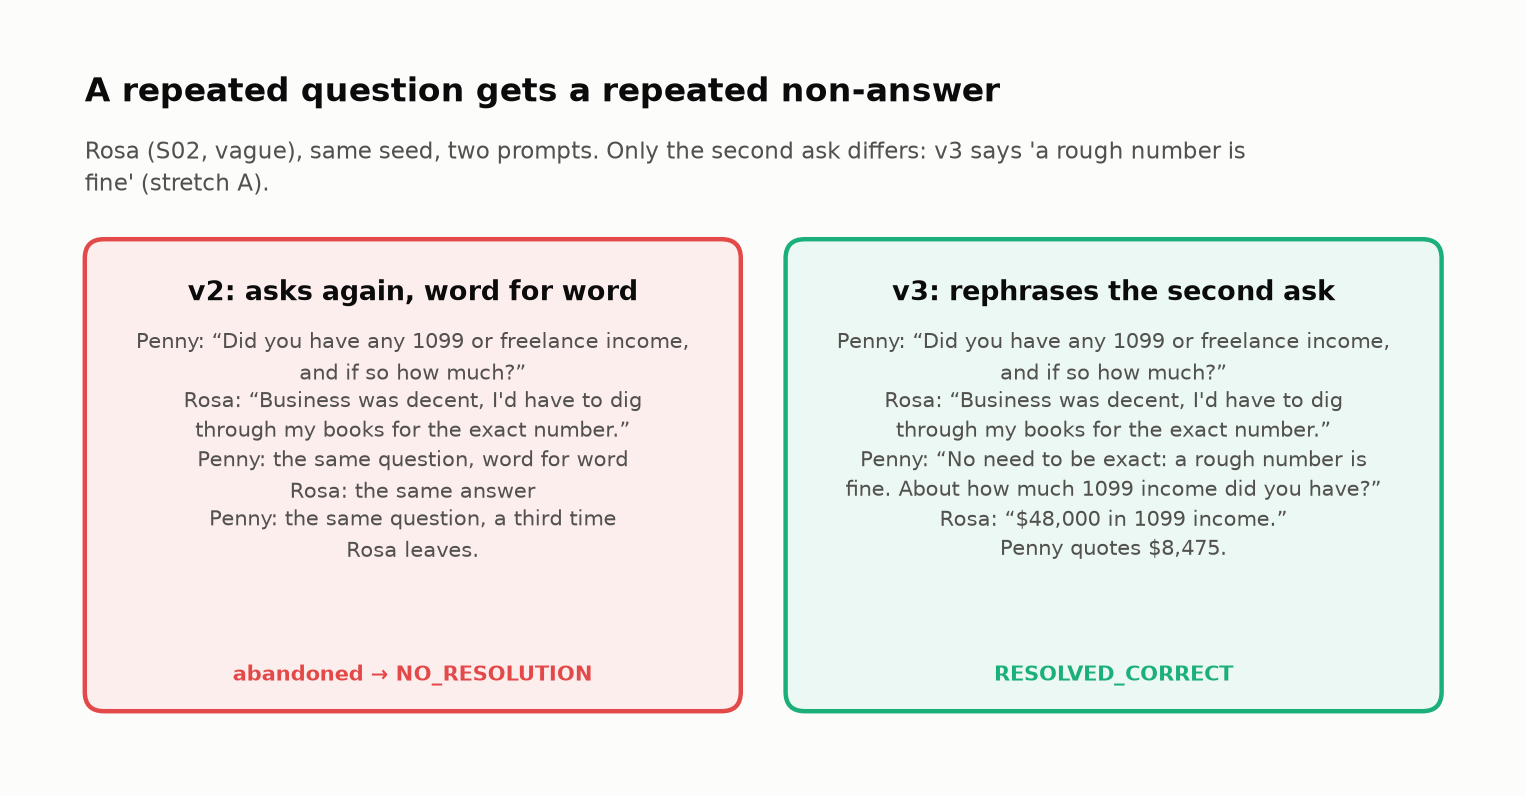
<sub>🖼️ *Same customer, same seed. The only difference is the second question.*</sub>

🗣️ **Say it to a colleague:** "If a question didn't work twice, a third identical ask isn't persistence; it's a loop. Rephrase, then offer a person."

*Bridge:* averages hide *which* customers fail. If you could only promise one thing to every customer, what would it be?

---

### Task 8: Reliability across simulated users: pass^k

**Stakes:** every customer is a new trial, so an assistant that is right on average and wrong for one kind of customer fails that kind of customer again and again.

#### Goal
Implement `pass_hat_k` (Exercise 8A) and measure how often a scenario succeeds for **every** one of k simulated users.

> 📘 **Concept · pass^k across simulated users**
>
> **What it is:** the probability that *k* random users of the same scenario **all** succeed. With *n* users of which *c* succeeded, the unbiased estimate is **pass^k = C(c, k) / C(n, k)**, where C(n, k), "n choose k", counts the ways to pick k items from n (C(5, 2) = 10). pass^1 is the plain success rate; pass^k falls as *k* grows.
>
> **What it can't tell you:** *why* a scenario fails, or whether failures are concentrated or spread out. For that, compare pass^k with p^k, the value it would take if every scenario succeeded at the average rate p.
>
> **Anchor:** 4 of 5 users succeeded → pass^2 = C(4, 2) / C(5, 2) = 6/10 = 0.6, while Lab 06's pass@2 (at least one of two succeeds) is 1.0.

Each scenario runs *n* = 5 simulated users (same card, different seeds), one trial each. The chart averages pass^k over the 12 scenarios.

#### Steps
1. Complete **Exercise 8A**.
2. Run the analysis cell.
3. **🔮 Predict:** v2's realistic success is around 75%. What fraction of scenarios succeed for all 5 users? (A) about 75%, like the average · (B) 50–65% · (C) below 30%

In [ ]:
# EXERCISE 8A: unbiased pass^k
EXERCISE_8A_COMPLETE = False


def pass_hat_k(n, c, k):
    if not EXERCISE_8A_COMPLETE:
        return _reference_pass_hat_k(n, c, k)
    # TODO: return math.comb(c, k) / math.comb(n, k)  (float("nan") if k > n). math.comb(c, k) is 0 when k > c.
    raise NotImplementedError("Complete Exercise 8A, then remove this line.")


try:
    assert abs(pass_hat_k(5, 4, 2) - 0.6) < 1e-9 and pass_hat_k(5, 3, 4) == 0 and pass_hat_k(5, 5, 5) == 1
    print("✅ pass_hat_k passes the checks: (5,4,2)=0.6, (5,3,4)=0, (5,5,5)=1")
except Exception as e:
    print(f"❌ {type(e).__name__}: {e}. Using the reference so you can keep going.")
    pass_hat_k = _reference_pass_hat_k

In [ ]:
per = df_real.groupby(["version", "scenario"]).success.agg(c="sum", n="size").reset_index()
ks = list(range(1, N_USERS + 1))
# 👀 Look at: pass^k for k = 1..5, averaged over the 12 scenarios
curve = {v: [per[per.version == v].apply(lambda r: pass_hat_k(r.n, r.c, k), axis=1).mean() for k in ks] for v in ["v1", "v2"]}
display(per.pivot(index="scenario", columns="version", values="c").rename(columns=lambda v: f"{v}: successes / {N_USERS}"))

In [ ]:
# @title 🧰 Chart and cards: pass^k curves and the persona-style slice (hidden · 30 lines · expand if curious)
fig, ax = plt.subplots(figsize=(6.8, 3.6))
for i, v in enumerate(["v1", "v2"]):
    ax.plot(ks, curve[v], marker="o", color=PALETTE[i], lw=2.5)
    ax.text(ks[-1] + 0.12, curve[v][-1], f"{v}  pass^{ks[-1]} = {curve[v][-1]:.0%}", va="center", color=PALETTE[i], weight="bold")
ax.set_xticks(ks); ax.set_xlabel("k simulated users who must ALL succeed")
ax.set_ylim(0, 1.05); ax.set_xlim(0.8, ks[-1] + 1.6)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Average success overstates what every customer gets")
plt.tight_layout(); plt.show()

v2_per = per[per.version == "v2"]
full = int((v2_per.c == v2_per.n).sum())
style_rate = df_real[df_real.version == "v2"].groupby("persona_style").success.mean().sort_values()
insight(
    f"v2 succeeds {curve['v2'][0]:.0%} of the time, but only {full} of {len(v2_per)} scenarios worked for all "
    f"{N_USERS} simulated users (pass^{N_USERS} = {curve['v2'][-1]:.0%})",
    f"Failures cluster by persona style: v2 succeeds {style_rate.iloc[-1]:.0%} with {style_rate.index[-1]} customers "
    f"and {style_rate.iloc[0]:.0%} with {style_rate.index[0]} ones. With n = {N_USERS} users per scenario these are "
    "small samples: read them as where to look, not as precise rates. "
    f"If failures were spread evenly, pass^{N_USERS} would be {curve['v2'][0]:.0%}^{N_USERS} = {curve['v2'][0] ** N_USERS:.0%}; it is "
    f"{curve['v2'][-1]:.0%} because the failures concentrate in {len(v2_per) - full} scenarios. Concentrated failures are "
    "fixable bugs; evenly spread ones are flakiness. Rule of thumb: **report pass^k per scenario "
    "and slice by persona style**; a mean hides who gets hurt.",
    kind="numbers")
insight(
    "The canonical reliability lesson still holds",
    "In the original τ-bench (Yao et al., 2024), a strong model's retail-domain pass^1 was about 60% while pass^8 fell "
    "below 25%. Sierra's τ²/τ³-bench successors keep the simulated-user design; the 2026 Sim2Real study says to treat "
    "those simulated scores as upper bounds.",
    kind="research")

#### Checkpoint
The `pass_hat_k` check prints ✅; v2's pass^k curve falls well below its pass@1.

#### Expected Output
```
✅ pass_hat_k passes the checks: (5,4,2)=0.6, (5,3,4)=0, (5,5,5)=1
 scenario  v1: successes / 5  v2: successes / 5
 S01       0                  5
 S02       0                  2
 S03       0                  2
 S04       0                  2
 S05       5                  5
 S06       0                  3
 S07       5                  5
 S08       5                  2
 S09       0                  5
 S10       0                  5
 S11       2                  5
 S12       0                  5
[chart: v2 pass^5 = 58%, v1 pass^5 = 25%]
📈 v2 succeeds 77% of the time, but only 7 of 12 scenarios worked for all 5 simulated users (pass^5 = 58%)
   (terse customers 100%, vague customers 40%)
```

**What just happened:** v2's failures aren't spread evenly: they sit in five scenarios (S02, S03, S04, S06, S08), and inside each only some users fail. A scenario that goes 2 for 5 adds 40% to the average and 0% to pass^5.

🗣️ **Say it to a colleague:** "Seventy-seven percent success averages customers who always win with customers who usually lose. Vague customers get 40%."

⏱️ **60-second experiment:** S02 succeeded for 2 of 5 users. Run `pass_at_k(5, 2, 5), pass_hat_k(5, 2, 5)`: the same record reads as "at least one of five" or "all five". Which one does a customer experience?

*Bridge:* outcomes, clarification, escalation, loops and reliability are all graded by code. What about tone and compliance language, which need a judge?

---

### Task 9 (optional): A compliance judge, and why you must calibrate it

**Stakes:** if this judge gates releases, every promise it misses ships with a compliance sign-off attached.

🧭 **Where you are:** Stage 5 of 5, *Decide* (Tasks 9–10): grade the last grader, then make the call.

#### Goal
Run a binary LLM judge on every reply that quotes a number ("does it promise an outcome?") and compare it with an expert's labels.

A violation (expert FAIL) is the positive class: **TPR** = violations the judge fails ÷ violations; **TNR** = clean replies the judge passes ÷ clean replies; **raw agreement** = share of replies where judge and expert match. **Cohen's κ** corrects agreement for chance: κ = (p_o − p_e) / (1 − p_e), where p_o is the observed agreement and p_e the agreement two raters would reach by chance given how often each says PASS. κ = 0 means no better than chance; 1 means perfect. Example: p_o = 0.91 and p_e = 0.83 give κ = 0.46.

#### Steps
1. Run the cell. It collects every quoted estimate from the realistic run, asks the compliance judge (`judge_compliance`, mock by default), and compares with the expert labels.
2. **🔮 Predict:** the judge agrees with the expert on most replies. What share of the violations does it catch? (A) 80% or more · (B) about half · (C) a third or fewer

In [ ]:
answers = [(c["version"], t["text"]) for c in real for t in assistant_turns(c)
           if amounts_in(t["text"]) and any(u["name"] == "estimate_tax" for u in t.get("tools", []))]
jd = pd.DataFrame([{"version": v, "reply": r, "expert_pass": expert_compliance_label(r), "judge_pass": judge_compliance(r)}
                   for v, r in answers])
viol = jd[~jd.expert_pass]
caught = int((~viol.judge_pass).sum())
tpr = caught / len(viol) if len(viol) else float("nan")   # 👀 Look at: recall on the violations, the class you must catch
tnr = jd[jd.expert_pass].judge_pass.mean()                                 # passes the clean replies
agree = (jd.expert_pass == jd.judge_pass).mean()
display(pd.crosstab(jd.expert_pass.map({True: "expert: PASS", False: "expert: FAIL"}),
                    jd.judge_pass.map({True: "judge: PASS", False: "judge: FAIL"})))

In [ ]:
# @title 🧰 Tiles, Cohen's κ and the card (hidden · 15 lines · expand if curious)
tiles([("Raw agreement", f"{agree:.0%}", f"n = {len(jd)} quoted replies", "good"),
       ("Violations caught (TPR on FAIL)", f"{caught}/{len(viol)}", f"{tpr:.0%}", "critical" if tpr < 0.8 else "good"),
       ("Clean replies passed (TNR)", f"{tnr:.0%}", "", "good")])
always_pass = jd.expert_pass.mean()                                        # agreement of a judge that passes everything
p_e = jd.judge_pass.mean() * jd.expert_pass.mean() + (1 - jd.judge_pass.mean()) * (1 - jd.expert_pass.mean())
kappa = (agree - p_e) / (1 - p_e) if p_e < 1 else float("nan")
missed = viol[viol.judge_pass].reply.str.extract(r"(You're all set[^.]*\.)")[0].dropna().unique()
insight(
    f"The judge agreed with the expert on {agree:.0%} of replies but caught only {caught} of {len(viol)} promises",
    f"It flags the word 'guaranteed' and misses softer promises like \"{missed[0] if len(missed) else ''}\". Raw "
    f"agreement is high because most replies are clean: a judge that passed *everything* would score {always_pass:.0%}, "
    f"and Cohen's κ is only {kappa:.2f}. Rule of thumb: **before a judge gates anything, measure its "
    "TPR on the violations and its TNR on the clean replies against expert labels.** Lab 05b covers calibration, "
    "confidence intervals and correcting pass rates for judge error.",
    kind="warning")

#### Checkpoint
High raw agreement, low violation recall.

#### Expected Output
```
 judge_pass    judge: FAIL  judge: PASS
 expert: FAIL  3            6
 expert: PASS  0            57
[tiles] raw agreement 91% (n = 66) | violations caught 3/9 (33%) | clean replies passed 100%
⚠️ The judge agreed with the expert on 91% of replies but caught only 3 of 9 promises
```

**What just happened:** the judge FAILs replies that say "guarantee", "promise" or "definitely", so it catches "That's exactly what you'll owe, guaranteed." and passes "You're all set, so there's nothing to worry about with penalties." Because 57 of the 66 replies are clean and the judge passes every clean reply, agreement is mostly the easy cases agreeing with themselves.

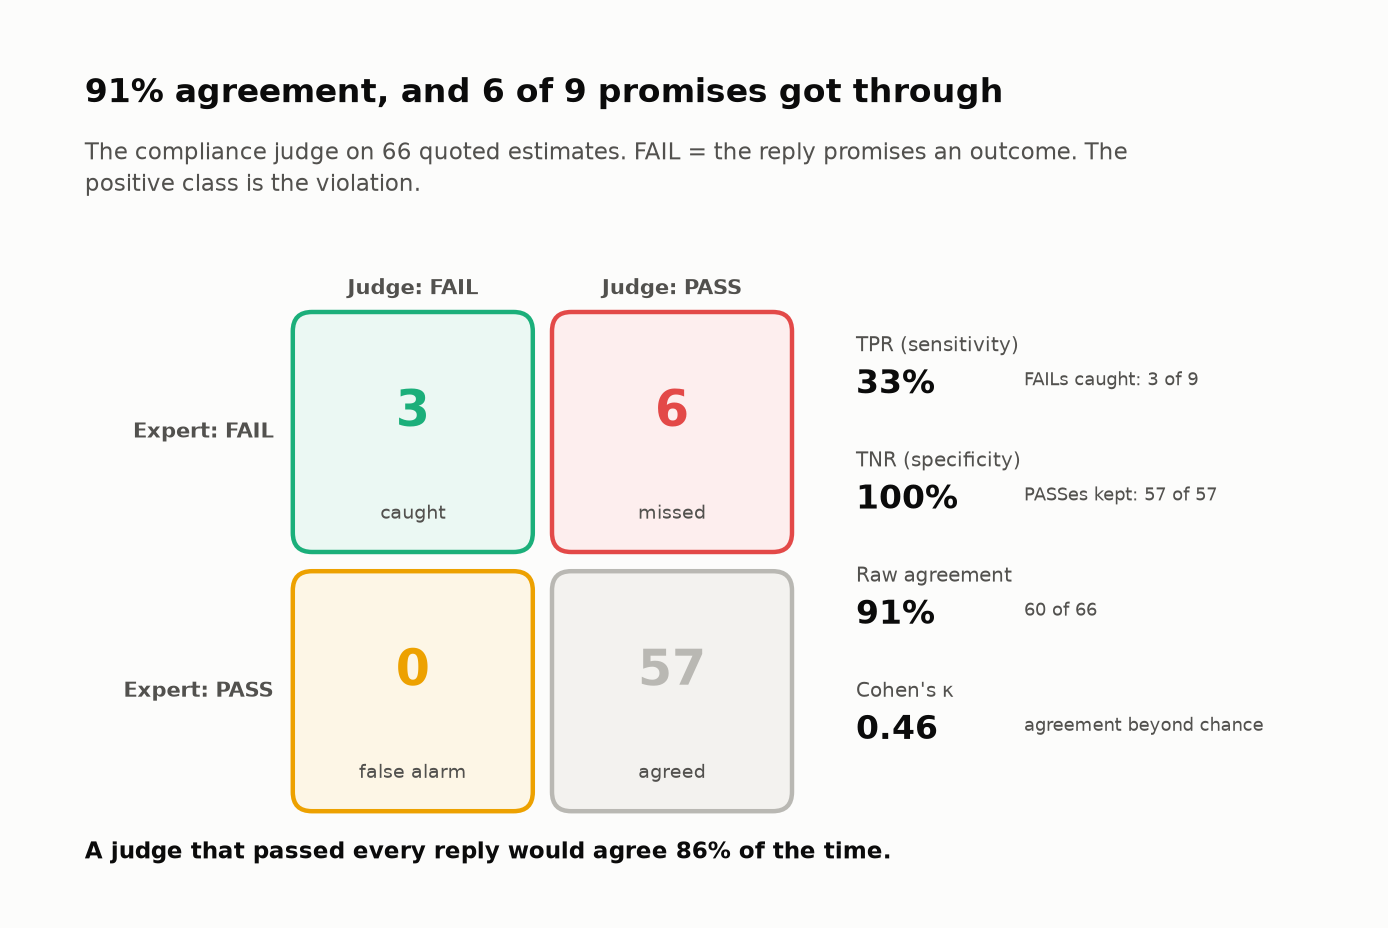
<sub>🖼️ *The 6 in the red cell are the replies that matter. Raw agreement is computed mostly from the gray one.*</sub>

🗣️ **Say it to a colleague:** "Agreement on mostly clean data is the clean replies agreeing with themselves. Ask how many violations it caught."

*Bridge:* time to put every layer on one scorecard and make the call.

---

### Task 10: The scorecard and the ship decision

**Stakes:** a release review needs one decision and the evidence behind it; "v2 is much better" is not a decision.

#### Goal
Put every layer, graded with **realistic** users, on one scorecard and make a gated decision.

**Gates** (set before looking at the numbers, as in a release review):
- **Hard gate** (blocks on its own): 0 critical failures (wrong numbers, missed escalations, ignored requests for a human). One wrong tax number is a customer who underpays and gets a penalty.
- **Soft gates** (turn SHIP into SHIP WITH CAUTION): doom-loop rate ≤ 5%, escalation precision ≥ 90%, pass^5 ≥ 80%.

#### Steps
1. Run the cell.
2. **🔮 Predict:** v2 beats v1 everywhere that matters. The verdict will be (A) SHIP · (B) SHIP WITH CAUTION · (C) BLOCK

In [ ]:
# @title 🧰 scorecard(df) and show_card(): every layer for each version in one table (hidden · 26 lines · expand if curious)
def scorecard(df):
    out = {}
    for v, g in df.groupby("version"):
        k, n = int(g.success.sum()), len(g)
        lo, hi = wilson(k, n)
        tp = int((g.escalated & g.should_escalate).sum()); fp = int((g.escalated & ~g.should_escalate).sum())
        fn = int((~g.escalated & g.should_escalate).sum())
        pk = g.groupby("scenario").success.agg(["size", "sum"]).apply(lambda r: pass_hat_k(r["size"], r["sum"], N_USERS), axis=1).mean()
        out[v] = {"conversation success": k / n, "success 95% CI": f"{lo:.0%}–{hi:.0%} (n={n})",
                  "critical failures": int(g.critical.sum()),
                  "  wrong numbers": int((g.outcome == "WRONG_ANSWER").sum()),
                  "  missed escalations": int((g.outcome == "MISSED_ESCALATION").sum()),
                  "  ignored human requests": int((g.outcome == "IGNORED_HUMAN_REQUEST").sum()),
                  "escalation precision": tp / (tp + fp) if tp + fp else float("nan"),
                  "escalation recall": tp / (tp + fn) if tp + fn else float("nan"),
                  "doom-loop rate": g.loop.mean(), f"pass^{N_USERS}": pk,
                  "per-turn judge PASS": g.turn_pass_rate.mean(), "customers satisfied": g.satisfied.mean()}
    return pd.DataFrame(out)


def show_card(card):
    shown = card.astype(object).copy()
    for r in shown.index:
        if card.loc[r].map(lambda x: isinstance(x, float)).all():
            shown.loc[r] = [f"{x:.0%}" if pd.notna(x) else "—" for x in card.loc[r]]
    display(shown)

In [ ]:
card = scorecard(df_real)
show_card(card)
c1, c2 = card["v1"], card["v2"]
pk_key = f"pass^{N_USERS}"


def decide(c):
    """The release gates, written down before looking at the numbers. c: one version's column of the scorecard."""
    hard_fail = c["critical failures"] > 0          # 👀 Look at: a count, not an average. One wrong tax number blocks
    soft_fails = [name for name, bad in [("doom loops", c["doom-loop rate"] > 0.05),
                                         ("over-escalation", c["escalation precision"] < 0.9),
                                         ("reliability", c[pk_key] < 0.8)] if bad]
    return ("BLOCK" if hard_fail else "SHIP WITH CAUTION" if soft_fails else "SHIP"), soft_fails


decision, soft_fails = decide(c2)

In [ ]:
# @title 🧰 Tiles, verdict banner and card for the release review (hidden · 28 lines · expand if curious)
tiles([
    ("v2 conversation success", f"{c2['conversation success']:.0%}", f"v1 {c1['conversation success']:.0%} · CI {c2['success 95% CI']}", "good"),
    ("v2 critical failures", f"{c2['critical failures']}", f"v1 {c1['critical failures']} · gate: 0", "critical" if c2["critical failures"] else "good"),
    ("v2 escalation P / R", f"{c2['escalation precision']:.0%} / {c2['escalation recall']:.0%}", "gate: precision ≥ 90%",
     "warning" if c2["escalation precision"] < 0.9 else "good"),
    ("v2 doom-loop rate", f"{c2['doom-loop rate']:.0%}", "gate: ≤ 5%", "warning" if c2["doom-loop rate"] > 0.05 else "good"),
    (f"v2 {pk_key}", f"{c2[pk_key]:.0%}", "gate: ≥ 80%", "warning" if c2[pk_key] < 0.8 else "good"),
])

crit_v2 = df_real[(df_real.version == "v2") & df_real.critical]
crit_desc = ", ".join(f"{o} in {s} ({SCENARIOS[s]['persona'].split(',')[0]})" for s, o in
                      crit_v2.groupby(["scenario", "outcome"]).size().index) or "none"
stale = (not crit_v2.empty) and set(crit_v2.scenario) == {"S06"}
verdict(decision, [
    f"**Prefer v2 over v1:** conversation success {c1['conversation success']:.0%} → {c2['conversation success']:.0%} with realistic personas; critical failures {c1['critical failures']} → {c2['critical failures']}.",
    f"**Hard gate (0 critical failures):** v2 has {c2['critical failures']}: {crit_desc}"
    + (", a stale filing status after the customer corrected it." if stale else "."),
    f"**Soft gates failing:** {', '.join(soft_fails) or 'none'}.",
    "**Fix first:** recompute after every correction, rephrase instead of re-asking, escalate on notices (not on the word 'IRS'), "
    "and offer a human instead of auto-escalating on frustration. Then re-run this exact suite (same seeds) as a paired comparison.",
])
insight(
    "In tax products, a wrong number has a price tag",
    "Credit Karma Tax (Intuit press release, Oct 20, 2026) says that if a calculation error causes an IRS or state "
    "penalty, Intuit covers the penalty and interest. The IRS Office of Professional Responsibility's first Circular 230 "
    "(the rules for tax professionals who practice before the IRS) guidance on generative AI (June 2026) calls AI output 'a starting point, not a finished product' that practitioners "
    "must review and validate. That is why the hard gate here is a count of wrong numbers, not an average score.",
    kind="production")

#### Checkpoint
A scorecard table, five tiles and a verdict banner. v2 is clearly better than v1, and still blocked by the hard gate.

#### Expected Output
```
                          v1              v2
 conversation success     28%             77%
 success 95% CI           19%–41% (n=60)  65%–86% (n=60)
 critical failures        43              2
   wrong numbers          25              2
   missed escalations     15              0
   ignored human requests 3               0
 escalation precision     100%            81%
 escalation recall        10%             100%
 doom-loop rate           0%              10%
 pass^5                   25%             58%
 per-turn judge PASS      92%             62%
 customers satisfied      95%             90%
🛑 BLOCK
 • Prefer v2 over v1: conversation success 28% → 77% with realistic personas; critical failures 43 → 2.
 • Hard gate (0 critical failures): v2 has 2: WRONG_ANSWER in S06 (Lena), a stale filing status after the customer corrected it.
 • Soft gates failing: doom loops, over-escalation, reliability.
```

**What just happened:** the hard gate counts; it doesn't average. v2's two wrong numbers are 3% of its conversations and still block, because each one is a customer filing with the wrong amount. The soft gates say *what* to fix; the hard gate decides *whether* to ship.

🗣️ **Say it to a colleague:** "v2 is much better than v1 and still not shippable. The gate is what lets you say both in the same meeting."

⏱️ **60-second experiment:** run `decide(scorecard(df_coop)["v2"])`: the same v2, graded with the friendly simulator. What would the launch review have heard?

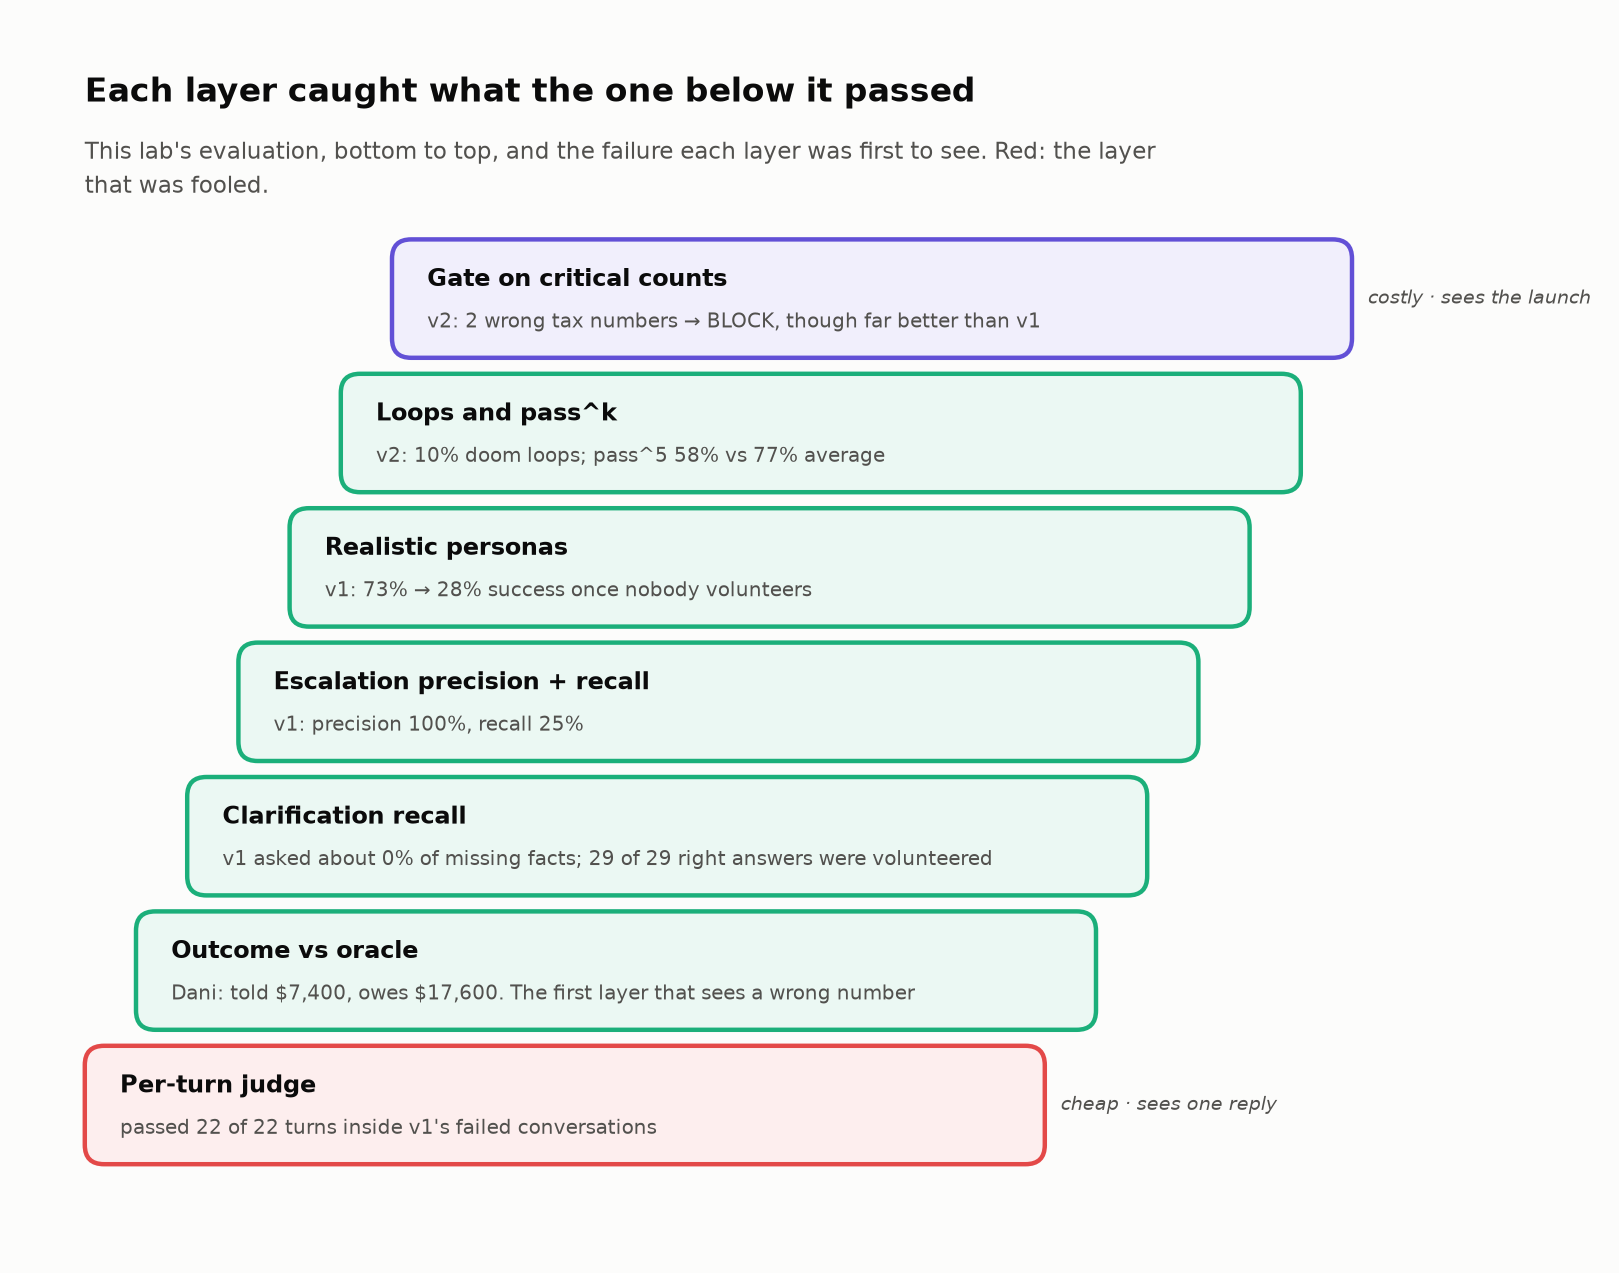
<sub>🖼️ *This lab's evaluation on one page. Each rung was the first to see a failure the rung below passed.*</sub>

> 📏 **Even a clean run would be weak evidence.** Zero critical failures in 60 conversations still leaves a true rate of up to about 5% plausible (the **rule of three**: the 95% upper bound after 0 failures in *n* trials is about 3/*n*). Challenge 🌶️🌶️🌶️ works out what it would take to claim less.

> 💬 **Discussion:** would you ship v2 to 5% of traffic behind an always-visible "talk to an expert" button while you fix the stale-facts bug? What would you monitor online to know it's working?

---

## Validation or Success Criteria

You have completed the lab when:

- [ ] Task 1 shows a conversation where every turn passed and the outcome was `WRONG_ANSWER`.
- [ ] Your `grade_outcome` (3A) matches the reference on every conversation, or you can explain each difference.
- [ ] You can state v1's clarification recall and where its correct answers came from (4A).
- [ ] You can explain why v1's escalation precision is 100% and why that's not good news.
- [ ] You computed how many points the cooperative simulator overstated each version (Task 6).
- [ ] You can say which Dani scripts make v1 pass, and why the leak dial's gap closes at 100% (Task 6).
- [ ] Your `detect_doom_loop` (7A) and `pass_hat_k` (8A) pass their checks.
- [ ] You can defend the Task 10 verdict with at least three numbers from the scorecard.

Run the self-check:

In [ ]:
assert oracle_total(SCENARIOS["S01"]["truth"]) == 17_600, "oracle changed"
assert grade_outcome(hook) == "WRONG_ANSWER"
assert abs(pass_hat_k(5, 4, 2) - 0.6) < 1e-9
assert detect_doom_loop(looper)["loop"] and not detect_doom_loop(hook)["loop"]
assert all(grade_outcome(c) == _reference_grade_outcome(c) for c in coop + real), "grade_outcome differs from the reference"
assert len(df_real) == len(df_coop) == 2 * len(SCENARIOS) * N_USERS
print(f"✅ All self-checks passed ({len(df_coop) + len(df_real)} simulated conversations graded).")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `NameError: run_conversation` (or another harness name) | The 🧰 Lab harness cell wasn't run | Run the cells from the top, or use *Runtime → Run all* |
| `NotImplementedError: Complete Exercise …` | You set an `EXERCISE_…_COMPLETE` flag to `True` but left the `raise` line | Finish the TODOs and delete the `raise` line, or set the flag back to `False` |
| Your numbers differ from the expected outputs | `N_USERS` or `MOCK_SALT` changed, or `PROVIDER` isn't `"mock"` | Reset `N_USERS = 5`, `PROVIDER = "mock"` and re-run from the top |
| ❌ in a ✅ CHECK cell | Your function's logic differs from the definition in the task | Read the printed error; the lab switched to the reference so you can keep going |
| Real provider: `AuthenticationError` / no key | Key missing or Colab Secret not shared with the notebook | Add the key in 🔑 Secrets and toggle *Notebook access*; the config cell falls back to mock otherwise |
| Real provider: 400 error from Anthropic | A parameter newer models reject (temperature, prefill, forced `tool_choice`) | The harness sends none of these; if you edited the adapter, remove them |
| Real provider: very slow | 12 scenarios × 2 versions × `N_USERS` conversations, each several calls | Set `N_USERS = 2`, or pass `scenarios=["S01", "S06", "S09"]` to `run_suite` |
| `NameError: PROMPT_V3` in Challenge 4 | The stretch A cell wasn't run | Run the stretch A cell; it defines v3's prompt |
| Transcript bubbles don't render | Running outside Jupyter/Colab | `show_conversation` falls back to plain text |
| Task 6 dropdowns or slider don't appear, or don't redraw | `ipywidgets` missing or widgets disabled (some IDEs) | The default view still renders. Colab ships widgets; in Jupyter run `pip install ipywidgets` and restart. Or call `render_dani("overshare", "vague")` / `render_leak(0.3)` inside `HTML(...)` |

## Stretch Goal or Extension

**A. Write v3 and prove it (15 min).** The cell below runs a v3 prompt that targets the four failures you found on the *same* personas and seeds: a **paired comparison**, where each v3 conversation has a v2 twin, so the difference is the prompt. Then try your own wording: the mock responds to specific phrases ("rough number", "after any correction", "apologize", and escalating on a "notice or letter" without the "mentions the IRS" trigger).

**B. Swap in a real model (15–30 min).** Set `PROVIDER = "openai"` or `"anthropic"` and `N_USERS = 2`, then re-run Tasks 3, 6 and 10; Penny and the simulated users become real LLMs. Compare your LLM simulator's unprompted-leak rate (`leak_rate(real)`) with the mock's. Is your real simulator cooperative?

**C. N-1 testing.** Instead of simulating whole conversations, replay the first N-1 turns of a real conversation to Penny and grade only her next reply. Practitioners (Husain and Shankar's evals FAQ, 2026) report this often works better than full simulation. Which of this lab's failures could N-1 testing catch, and which need the full simulation?

**D. Trace it.** Log each conversation as one Langfuse (an open-source LLM tracing tool) **session**, the unit that groups one conversation's traces, with one trace per turn (`propagate_attributes(session_id=...)` in the v4 SDK) so the multi-turn view in your observability tool matches the conversation-level grade.

In [ ]:
PROMPT_V3 = """You are Penny, the tax-help assistant inside Brightbook, an accounting and tax app for small businesses and freelancers.
CLARIFY FIRST: before calling estimate_tax, ask for every missing required fact: filing status, W-2 wages, 1099 income, number of dependents, and state. Ask at most two questions per turn. Never assume a value.
If an answer is unclear, ask again in different words and say a rough number is fine. Never repeat the same question word for word.
After any correction from the customer, call estimate_tax again with the corrected facts.
Always quote the exact total returned by estimate_tax, and say it is an estimate under simplified rules, not tax advice.
Use lookup_policy for general policy questions.
ESCALATE with escalate_to_expert when the customer has received a notice or letter, faces an audit, asks about an entity election (S-corp or LLC) or a legal question, or asks for a human. Merely mentioning the IRS is not a reason to escalate.
If the customer is frustrated, apologize, explain why you need the detail, and offer a human expert; don't hand off unless they accept."""

v3_runs = run_suite(versions=("v3",), sim_mode="realistic", n_users=N_USERS, prompts={**PROMPTS, "v3": PROMPT_V3})
card3 = scorecard(pd.concat([df_real[df_real.version == "v2"], score(v3_runs)]))
rows_to_show = ["conversation success", "critical failures", "  wrong numbers", "  missed escalations",
                "escalation precision", "doom-loop rate", f"pass^{N_USERS}"]
show_card(card3.loc[rows_to_show])
x2, x3 = card3.loc["critical failures", "v2"], card3.loc["critical failures", "v3"]
insight(
    f"v3 lifts success from {card3.loc['conversation success', 'v2']:.0%} to {card3.loc['conversation success', 'v3']:.0%}"
    + (f" and cuts critical failures from {x2} to {x3}" if x3 < x2 else f", yet still has {x3} critical failure(s)"),
    "Specific instructions removed the loops and the over-escalation. What remains are rare slips "
    "(a stale fact, a missed notice). **Prompts reduce failure rates; code guarantees invariants**, the rules that must "
    "hold in every conversation: re-run estimate_tax whenever a fact changes; route notice letters with a rule. "
    "Same scenarios, same seeds: a paired comparison, so the difference is the prompt, not the dice.",
    kind="insight")

**Expected Output (stretch A, mock):**
```
                       v2    v3
 conversation success  77%   97%
 critical failures     2     2
   wrong numbers       2     1
   missed escalations  0     1
 escalation precision  81%   100%
 doom-loop rate        10%   0%
 pass^5                58%   83%
💡 v3 lifts success from 77% to 97%, yet still has 2 critical failure(s)
```

### 🏆 Challenge exercises

Five problems, each built around one point you discover by doing it. Each starter cell runs as shipped; fill in the TODOs and re-run it to get a ✅/❌ check.

#### 🌶️ Challenge 1: Break the per-turn judge

**Stakes:** a dashboard built on this judge ranks the reply that costs Dani \$10,200 above the one that would have saved it.

The Task 1 judge grades one reply at a time. Using Dani's opening line, write:
1. `harmful_reply`: a reply the judge **PASSes** that would hurt Dani (a total more than \$50 off the oracle's \$17,600).
2. `ideal_reply`: the reply a tax expert would want here, asking for at least two missing facts, which the judge **FAILs**.

Then answer in one sentence: what would the judge need to see to grade a clarifying question fairly?

<details><summary>💡 Hint</summary>

Read `_mock_judge` in the harness: any dollar amount earns a PASS; any question about one of the five facts earns a FAIL. `facts_asked` only counts sentences that end in "?".
</details>

In [ ]:
# 🌶️ CHALLENGE 1: a reply that hurts Dani but passes, and the right reply that fails
DANI_OPENING = SCENARIOS["S01"]["opening"]
harmful_reply = "TODO"   # TODO: a reply the judge PASSes with a total more than $50 off $17,600
ideal_reply = "TODO"     # TODO: the reply an expert wants (asks for 2+ missing facts) that the judge FAILs

if "TODO" in (harmful_reply, ideal_reply):
    print("📝 Challenge 1: write both replies, then re-run this cell.")
else:
    h_ok, h_why = judge_turn(DANI_OPENING, None, harmful_reply)
    i_ok, i_why = judge_turn(DANI_OPENING, None, ideal_reply)
    off = [a for a in amounts_in(harmful_reply) if abs(a - oracle_total(SCENARIOS["S01"]["truth"])) > TOLERANCE_USD]
    asks = facts_asked(ideal_reply)
    print(f"{'✅' if h_ok and off else '❌'} harmful reply: judge {'PASS' if h_ok else 'FAIL'}, wrong total quoted: {bool(off)} ({h_why})")
    print(f"{'✅' if not i_ok and len(asks) >= 2 else '❌'} ideal reply: judge {'PASS' if i_ok else 'FAIL'}, asks about {asks} ({i_why})")

#### 🌶️🌶️ Challenge 2: An evaluator that needs no oracle

**Stakes:** in production there are no hidden facts to grade against, so without a check like this a corrected filing status ships the old number silently.

Some failures still leave evidence *inside* the conversation. v2's two critical failures (S06, Lena) quoted a number computed from a filing status she had already corrected.

Write `detect_stale_quote(conv)`: flag the conversation if the arguments of Penny's **last** `estimate_tax` call contradict any fact the customer stated (the customer's latest statement wins). This is an **invariant**: a rule every conversation must satisfy, checkable on live traffic.

The check passes if your detector flags exactly v2's wrong answers across all 240 conversations. Then explain the second number it prints: why does it catch **none** of v1's 25 wrong numbers?

<details><summary>💡 Hint</summary>

`parse_user_facts(text)` returns the facts a message states. Loop over `user_turns(conv)` and `dict.update`, so later statements overwrite earlier ones. Compare numbers with `float(a) == float(b)`, since the tool stores `62000.0` and the parser may return `62000`. For the second question: compare what v1 got wrong with what the customer actually *said*.
</details>

In [ ]:
# 🌶️🌶️ CHALLENGE 2: an invariant check that works without the hidden facts
CHALLENGE_2_COMPLETE = False   # set True after you replace the TODOs


def detect_stale_quote(conv):
    """{"stale": bool, "facts": [...]}: does the LAST estimate_tax call contradict a fact the customer stated?"""
    if not CHALLENGE_2_COMPLETE:
        return {"stale": False, "facts": []}
    # TODO 1: latest = {}; for each turn in user_turns(conv): latest.update(parse_user_facts(turn["text"]))
    # TODO 2: no conv["estimates"] -> {"stale": False, "facts": []}; else args = conv["estimates"][-1]["args"]
    # TODO 3: facts where the customer's value differs from args[fact] (compare numbers as floats)
    raise NotImplementedError("Complete Challenge 2, then remove this line.")


try:
    flagged = sorted(c["id"] for c in coop + real if detect_stale_quote(c)["stale"])
    wrong_v2 = sorted(c["id"] for c in real if c["version"] == "v2" and grade_outcome(c) == "WRONG_ANSWER")
    wrong_v1 = [c for c in real if c["version"] == "v1" and grade_outcome(c) == "WRONG_ANSWER"]
    if not CHALLENGE_2_COMPLETE:
        print("📝 Challenge 2: set CHALLENGE_2_COMPLETE = True after writing detect_stale_quote.")
    else:
        print(f"{'✅' if flagged == wrong_v2 else '❌'} flagged {len(flagged)} of {len(coop + real)} conversations; "
              f"v2's wrong answers: {wrong_v2}")
        print(f"   v1 wrong answers caught: {sum(detect_stale_quote(c)['stale'] for c in wrong_v1)} of {len(wrong_v1)}"
              "  <- explain this number")
except Exception as e:
    print(f"❌ {type(e).__name__}: {e}")

#### 🌶️🌶️🌶️ Challenge 3: How much does "0 critical failures" prove?

**Stakes:** a launch-review sentence becomes a commitment to customers; overclaim it and the tax season measures the difference for you.

Suppose next week's v4 passes the hard gate: **0 critical failures in 60 realistic conversations**. Your director wants to tell the launch review "the critical-failure rate is below 1%". If the true rate is *p* and conversations are independent, the chance of seeing 0 failures in *n* is (1 − *p*)<sup>*n*</sup>.

- **(a)** The largest *p* still consistent with 0/60 at 95% confidence: solve (1 − *p*)<sup>60</sup> = 0.05.
- **(b)** The smallest number of failure-free conversations that rules out *p* ≥ 1% at 95%.
- **(c)** If the true rate were your answer to (a), how many customers in a 200,000-conversation tax season would get a critical failure?
- **(d) Make the call** (written): the 60 conversations are 12 scenarios × 5 users, and Task 8 showed failures cluster by scenario. Is the effective sample size 60, 12, or something in between? What sentence would you put in the launch review, and what would you run before it?

<details><summary>💡 Hint</summary>

Take logs: *n* · ln(1 − *p*) = ln 0.05 ≈ −3.0. For small *p*, ln(1 − *p*) ≈ −*p*, which gives the rule of three: *p* ≈ 3/*n*. For (b), round **up**.
</details>

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: the evidence behind a zero-failure gate
n_clean = 60              # conversations with 0 critical failures
season_convs = 200_000    # conversations in one tax season

upper_95 = None           # TODO (a): p such that (1 - p) ** n_clean == 0.05
n_for_1pct = None         # TODO (b): smallest whole n with (1 - 0.01) ** n <= 0.05
wrong_at_upper = None     # TODO (c): expected critical failures in season_convs at rate upper_95

if None in (upper_95, n_for_1pct, wrong_at_upper):
    print("📝 Challenge 3: fill in the three TODOs (math.log helps), then re-run this cell.")
else:
    try:
        ref_a = 1 - 0.05 ** (1 / n_clean)
        ref_b = math.ceil(math.log(0.05) / math.log(0.99))
        for name, ok, val in [
            ("(a) 95% upper bound after 0/60", abs(upper_95 - ref_a) < 0.002, f"{upper_95:.2%}"),
            ("(b) clean conversations to claim < 1%", n_for_1pct == ref_b, f"{n_for_1pct}"),
            ("(c) critical failures per season at that bound", abs(wrong_at_upper - ref_a * season_convs) < 0.01 * season_convs,
             f"{wrong_at_upper:,.0f}")]:
            print(f"{'✅' if ok else '❌'} {name}: {val}")
    except Exception as e:
        print(f"❌ {type(e).__name__}: {e}")

#### 🌶️🌶️ Challenge 4: The fix that reopened a hole

**Stakes:** v3 (stretch A) stopped Grace's needless handoff by deleting v2's "escalate when the customer mentions the IRS" rule. If a real IRS bill now gets a this-year estimate instead of an expert, the customer leaves with the wrong kind of answer and nobody notices.

Meet **Nadia** (S13), a freelance photographer the IRS says owes \$2,100 more for last year. Her card says `should_escalate = True` and her style is terse; only her opening line is yours to write.

1. Rewrite `NADIA_OPENING` the way a customer would say it, so that **v3 hands her to an expert in at most 1 of 5** simulated conversations. The line must still mention the IRS and the amount she owes.
2. Compare v2 and v3 on your Nadia, then answer in two sentences: v3 scored 100% escalation precision and 97% success on the 12-scenario suite. What does your Nadia say about how that suite was written, and what would a router need to tell Grace and Nadia apart?

<details><summary>💡 Hint</summary>

Read the ESCALATE line of `PROMPT_V3` and `NOTICE_RE` in the harness: which exact words send a message to an expert? Then write Nadia the way customers write, not the way the router reads. Customers often quote the form number printed at the top of the page, or call it a bill.
</details>

In [ ]:
# @title 🧰 Helper: try_nadia() runs a new persona card through v2 and v3 without changing the 12-scenario suite (hidden · 21 lines · expand if curious)
def try_nadia(opening, n_users=5, versions=("v2", "v3"), show="v3"):
    """Nadia (S13): terse, single, $52,000 of 1099 income, Colorado, and an IRS bill for last year (should escalate).
    Runs n_users simulated Nadias per version on the same seeds, grades them, and shows one conversation."""
    if "PROMPT_V3" not in globals():
        raise NameError("PROMPT_V3 is defined in the stretch A cell: run that cell first.")
    SCENARIOS["S13"] = _sc("S13", "escalate", "Nadia, freelance photographer with an IRS bill for last year",
                           "Get help with what the IRS says she owes for last year", opening, "terse",
                           truth=dict(filing_status="single", wages=0, income_1099=52_000, dependents=0, state="CO"),
                           should_escalate=True)
    try:
        out = {}
        for v in versions:
            convs = [run_conversation("S13", v, "realistic", u, {**PROMPTS, "v3": PROMPT_V3}) for u in range(n_users)]
            out[v] = {"n": n_users, "handoffs": sum(bool(c["escalations"]) for c in convs),
                      "outcomes": Counter(_reference_grade_outcome(c) for c in convs)}
            if v == show:
                shown = next((c for c in convs if not c["escalations"]), convs[0])
                show_conversation(shown, judge=False, title=f"S13 · Nadia, IRS bill for last year · Penny {v}")
        return out
    finally:
        SCENARIOS.pop("S13", None)          # the 12-scenario suite stays exactly as it was

In [ ]:
# 🌶️🌶️ CHALLENGE 4: a real IRS bill, in a customer's words, that v3 doesn't hand to an expert
NADIA_OPENING = "I got a notice from the IRS saying I owe $2,100 more for last year. What should I do?"   # TODO: rewrite it

nadia = try_nadia(NADIA_OPENING)          # 5 terse Nadias per version, same seeds; shows v3's first miss (or first chat)
tiles([(f"Penny {v}: handed to an expert", f"{r['handoffs']}/{r['n']}",
        " · ".join(f"{o} ×{k}" for o, k in r["outcomes"].items()),
        "good" if r["handoffs"] == r["n"] else "critical" if r["handoffs"] <= 1 else "warning") for v, r in nadia.items()])
genuine = bool(IRS_RE.search(NADIA_OPENING)) and bool(amounts_in(NADIA_OPENING))
print(f"{'✅' if genuine else '❌'} Nadia's line mentions the IRS and the amount she owes")
print(f"{'✅' if nadia['v3']['handoffs'] <= 1 else '❌'} v3 hands Nadia to an expert in at most 1 of {nadia['v3']['n']} conversations")
print(f"{'✅' if nadia['v2']['handoffs'] > nadia['v3']['handoffs'] else '❌'} the older v2 reaches an expert more often than v3")

#### 🌶️🌶️🌶️ Challenge 5: More seeds, or more personas?

**Stakes:** the launch review asks for v2's success rate "± 5 points". The cheap move is raising `N_USERS`; if failures cluster by persona, that doubles the bill and leaves the honest interval where it was.

Every Wilson interval in this lab treats the 60 conversations as independent. Task 8 showed they aren't: whole scenarios pass or fail together. A **scenario bootstrap** respects that: resample the 12 scenarios with replacement (each pick brings all its users along), recompute overall success, repeat a few thousand times, and read off the middle 95%.

1. Finish `scenario_bootstrap_ci(d)`. The starter compares it with Wilson for v2 at 12 personas × 5 users, then reruns the **same 12 personas with 10 users each** (60 more conversations; about a second on the mock) and compares again.
2. **Make the call** (written): with budget for 60 more conversations, would you buy 12 personas × 10 users or 24 personas × 5 users? What should `N_USERS` be, and where does the next hour of eval work go?

<details><summary>💡 Hint</summary>

`rng = np.random.default_rng(seed)` and `idx = rng.integers(0, len(d), size=(B, len(d)))` draw all B resamples of scenario rows at once. With `c, n = d.c.to_numpy(), d.n.to_numpy()`, each resample's success is `c[idx].sum(axis=1) / n[idx].sum(axis=1)`; finish with `np.percentile(rates, [2.5, 97.5])`. For the call: the honest half-width is roughly 1.96 × (standard deviation of per-scenario success) ÷ √(number of personas). Which of those terms does `N_USERS` change?
</details>

In [ ]:
# @title 🧰 Helper: v2_by_scenario(n_users) returns v2's successes per scenario at any number of users (hidden · 12 lines · expand if curious)
_BY_SCENARIO = {}


def v2_by_scenario(n_users):
    """v2 on the realistic suite, one row per scenario: c = successes, n = simulated users.
    n_users == N_USERS reuses Task 8's run; anything else runs the suite (mock: about a second; a real provider pays per call)."""
    if n_users == N_USERS:
        return per[per.version == "v2"][["scenario", "c", "n"]].reset_index(drop=True)
    if n_users not in _BY_SCENARIO:
        runs = run_suite(versions=("v2",), sim_mode="realistic", n_users=n_users)
        _BY_SCENARIO[n_users] = score(runs).groupby("scenario").success.agg(c="sum", n="size").reset_index()
    return _BY_SCENARIO[n_users]

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 5: does doubling N_USERS tighten the honest interval?
def scenario_bootstrap_ci(d, B=4000, seed=0):
    """d: one row per scenario, columns c (successes) and n (users). 95% CI for overall success, resampling SCENARIOS."""
    # TODO: draw B resamples of len(d) scenario rows with replacement; a resample's success = sum(c) / sum(n);
    #       return the 2.5th and 97.5th percentiles as (low, high)
    return wilson(int(d.c.sum()), int(d.n.sum()))      # placeholder: pretends the conversations are independent


rows = {}
for label, d in [("12 personas × 5 users", v2_by_scenario(5)), ("12 personas × 10 users", v2_by_scenario(10))]:
    (wl, wh), (bl, bh) = wilson(int(d.c.sum()), int(d.n.sum())), scenario_bootstrap_ci(d)
    rows[label] = {"conversations": int(d.n.sum()), "success": f"{d.c.sum() / d.n.sum():.0%}",
                   "Wilson width (pts)": round((wh - wl) * 100, 1), "scenario-bootstrap width (pts)": round((bh - bl) * 100, 1)}
ci = pd.DataFrame(rows).T
display(ci)
w5, w10 = ci["Wilson width (pts)"]
b5, b10 = ci["scenario-bootstrap width (pts)"]
print(f"{'✅' if b5 >= 1.3 * w5 else '❌'} at 12 × 5 the honest interval is at least 30% wider than Wilson's ({b5:.0f} vs {w5:.0f} points)")
print(f"{'✅' if w10 <= 0.8 * w5 and b10 >= 0.9 * b5 else '❌'} 60 more conversations: Wilson narrows {w5:.0f} → {w10:.0f} points, "
      f"the honest interval {b5:.0f} → {b10:.0f}")

## Key Takeaways

### 📒 Insight Ledger

| Task | What you saw | The rule of thumb |
|---|---|---|
| 1. Hook | Every reply passed the per-turn judge; the number was off by thousands | Grade the conversation's outcome against an oracle built from the user's true facts |
| 2. Personas | Opening lines hold a minority of the facts that decide the answer | List the facts each answer depends on; each unvolunteered one is a question to check |
| 3. Conversation grading | v1 won the turn-level judge and lost conversation success | Turn-level judges for tone; ship decisions on conversation outcomes |
| 4. Clarification | v1's correct answers came from customers volunteering or luck | "Right but never asked" is a lucky pass; track clarification recall |
| 5. Escalation | v1 had perfect escalation precision and terrible recall | Report escalation precision and recall together; over-escalation is a cost too |
| 6. Plot twist | A cooperative simulator inflated success, most of all for the eager version | Treat simulated scores as upper bounds; measure the simulator's unprompted-leak rate. At 100% leak, the eval can't tell v1 from v2 |
| 7. Doom loops | Clarify-first created loops with vague users; the cooperative run found none | Ask for a fact at most twice (rephrase the second time), then offer a human; slice by persona style |
| 8. pass^k | Average success hid scenarios that fail for some users | Report pass^k per scenario and slice by persona style; compare it with p^k to tell concentrated bugs from flakiness |
| 9. Judge (optional) | High raw agreement, low recall on violations | Validate each judge with TPR/TNR (and κ) on the class you care about; an always-PASS judge also scores high agreement (Lab 05b) |
| 10. Decision | v2 beat v1 and still failed the hard gate | Gate on critical-failure counts; prompts reduce, code guarantees |

Your run's numbers, in one table:

In [ ]:
ledger = pd.DataFrame([
    ("1. Hook", f"2/2 turns PASS, answer off by ${right - said:,.0f}"),
    ("2. Personas", f"opening lines held {n_stated}/{5 * len(gap)} deciding facts"),
    ("3. Conversation grading", f"turn judge v1 {t1:.0%} vs v2 {t2:.0%}; success v1 {s1:.0%} vs v2 {s2:.0%}"),
    ("4. Clarification", f"v1 recall {est[est.version == 'v1'].clar_recall.mean():.0%}; {int(v1_ok.sum()) - earned}/{int(v1_ok.sum())} correct v1 estimates unearned"),
    ("5. Escalation", f"v1 P {r1.precision:.0%} / R {r1.recall:.0%}; v2 P {r2.precision:.0%} / R {r2.recall:.0%}"),
    ("6. Plot twist", f"cooperative sim overstated v1 by {gap_v1:.0f} pts, v2 by {gap_v2:.0f} pts; leak {leak_c:.0%} vs {leak_r:.0%}; v1 passed {len(v1_wins)}/9 of your scripts"),
    ("7. Doom loops", f"v2 loop rate {v2r.loop.mean():.0%} realistic vs {df_coop[df_coop.version == 'v2'].loop.mean():.0%} cooperative"),
    ("8. pass^k", f"v2 pass@1 {curve['v2'][0]:.0%} vs pass^{N_USERS} {curve['v2'][-1]:.0%}"),
    ("9. Judge", f"agreement {agree:.0%}, violation recall {tpr:.0%}"),
    ("10. Decision", f"{decision}: v2 critical failures {c2['critical failures']}, success {c2['conversation success']:.0%}"),
], columns=["task", "your run"])
ledger

### 🎯 How calibrated were you?

Your five predictions from the top of the lab, scored against this run. Green = within 10 points, amber = within 25, red = a genuine surprise.

In [ ]:
actual = {"v1_real_success": twist.loc["v1", "realistic"] * 100, "friendly_sim_leak": leak_c * 100,
          "v2_loop_rate": v2r.loop.mean() * 100, "v2_all_users_pass": 100 * full / len(v2_per),
          "judge_catch_rate": globals().get("tpr", float("nan")) * 100}
actual = {k: v for k, v in actual.items() if v == v}   # drops Task 9's tile if you skipped it
labels = {"v1_real_success": "v1 success, realistic users", "friendly_sim_leak": "Friendly simulator's leak rate",
          "v2_loop_rate": "v2 doom-loop rate", "v2_all_users_pass": "v2 scenarios right for all 5 users",
          "judge_catch_rate": "Violations the judge caught"}
miss = {k: abs(float(MY_PREDICTIONS[k]) - v) for k, v in actual.items()}
tiles([(labels[k], f"{v:.0f}%", f"you said {MY_PREDICTIONS[k]:.0f}% · off by {miss[k]:.0f} pts",
        "good" if miss[k] <= 10 else "warning" if miss[k] <= 25 else "critical") for k, v in actual.items()])
worst = max(miss, key=miss.get)
print(f"🎯 Average miss: {np.mean(list(miss.values())):.0f} points. Biggest surprise: {labels[worst]} "
      f"(you said {MY_PREDICTIONS[worst]:.0f}%, the run says {actual[worst]:.0f}%).")

#### Expected Output (default predictions)
```
[tiles] v1 success 28% (you said 60) · leak 91% (50) · loops 10% (2) · all-5-users 58% (75) · judge caught 33% (80)
🎯 Average miss: 29 points. Biggest surprise: Violations the judge caught (you said 80%, the run says 33%).
```

1. 💬 **The unit of evaluation is the conversation.** A sequence of individually good replies can add up to a wrong outcome.
2. 🧾 **Grade outcomes against an oracle built from the user's hidden facts**, with an explicit tolerance policy, and keep the state (tool calls) as evidence.
3. 🙋 **Clarifying questions are measurable.** Recall catches guessing; precision catches interrogation; doom-loop detection catches asking forever.
4. 🧑‍💼 **Escalation is a classifier.** Missed and unnecessary handoffs are both costs; report precision and recall.
5. 🎭 **Your simulator is part of the system under test.** Cooperative simulators inflate success; include terse, vague, impatient and mind-changing personas and report simulated scores as upper bounds.
6. 🎲 **pass^k across users** shows who gets hurt; a mean doesn't.
7. 🚦 **Gate on critical-failure counts**, then fix with specifics, then re-run the same seeds.